# Regresión Lineal Múltiple: exploración, selección, validación y predicción

---

## ¿De qué trata este cuadernillo?

Este cuadernillo enseña, paso a paso, cómo construir y evaluar un **modelo de regresión lineal múltiple** en Python. Se puede usar tal como está (trae una base de datos de ejemplo) o con cualquier otra base que tenga una variable numérica que se quiera explicar o predecir.

El recorrido completo es:

> **Comprender el problema → explorar los datos → prepararlos → construir el modelo → seleccionar variables → regularizar → validar supuestos → evaluar la predicción → predecir → concluir.**

En cada sección encontrará la misma estructura:

- **Qué vamos a hacer**: la tarea concreta.
- **Por qué**: la razón estadística o práctica.
- **Código**: comentado línea a línea cuando hace falta.
- **Cómo leer el resultado**: qué mirar en la salida y qué significa.

## Objetivos de aprendizaje

Al finalizar, usted podrá:

- identificar una variable respuesta cuantitativa y sus posibles predictores;
- realizar un análisis exploratorio de datos completo;
- construir e interpretar un modelo de regresión lineal múltiple;
- detectar multicolinealidad;
- seleccionar variables con distintos métodos (Backward, Forward, Stepwise, AIC/BIC);
- comprender y aplicar regularización (Ridge, Lasso, Elastic Net);
- verificar los supuestos del modelo;
- medir la calidad del ajuste y la capacidad predictiva;
- hacer predicciones con sus intervalos;
- formular conclusiones sustentadas en los resultados.

## Cómo trabajar con el cuadernillo

1. **Ejecute las celdas en orden**, de arriba hacia abajo (o use *Run All*). Cada celda usa resultados de las anteriores; si se salta una, las siguientes pueden fallar.
2. **Ningún número está escrito a mano.** Todas las cifras (coeficientes, p-valores, métricas) se calculan al ejecutar. Si cambia la base, cambian los resultados.
3. **Celdas de configuración.** Algunas celdas contienen valores que usted puede ajustar (el nombre del archivo, la variable respuesta, los predictores, etc.). Siempre están precedidas por una explicación titulada **"Configuración"** que dice:
   - qué controla cada valor,
   - cuándo conviene cambiarlo,
   - y un ejemplo de cómo hacerlo.

   Si trabaja con la base de ejemplo, **no necesita cambiar nada**: el cuadernillo funciona completo tal como está.

---
# PARTE 1. Comprensión del problema

## 1.1 ¿Qué es un problema de regresión?

Un problema de **regresión** aparece cuando queremos entender o anticipar el valor de una **variable numérica** a partir de otras variables. Algunos ejemplos:

| Pregunta | Variable respuesta ($Y$) | Posibles predictores ($X$) |
|---|---|---|
| ¿De qué depende el precio de una vivienda? | Precio | Área, estrato, número de habitaciones, antigüedad |
| ¿Qué explica el rendimiento académico? | Promedio de notas | Horas de estudio, asistencia, nivel socioeconómico |
| ¿Cómo progresa una enfermedad? | Indicador de progresión | Edad, índice de masa corporal, presión arterial |

Cuando hay **varios predictores a la vez**, hablamos de **regresión lineal múltiple**. Su ecuación es:

$$
Y_i = \beta_0+\beta_1X_{1i}+\beta_2X_{2i}+\cdots+\beta_pX_{pi}+\varepsilon_i, \qquad i = 1,\dots,n
$$

Leída en palabras: *"el valor de $Y$ para la observación $i$ es igual a una constante, más la contribución de cada predictor, más un error"*.

| Símbolo | Nombre | Qué representa |
|---|---|---|
| $Y_i$ | Variable respuesta | Lo que queremos explicar o predecir. |
| $X_{1i},\dots,X_{pi}$ | Predictores | Las variables que usamos para explicar $Y$. |
| $\beta_0$ | Intercepto | Valor esperado de $Y$ cuando todos los predictores valen 0. |
| $\beta_j$ | Coeficiente de $X_j$ | Cuánto cambia $Y$, en promedio, cuando $X_j$ aumenta una unidad **y los demás predictores se mantienen fijos**. |
| $\varepsilon_i$ | Error aleatorio | Todo lo que el modelo no captura: variables no medidas, variación natural, errores de medición. |

## 1.2 ¿Cómo se calculan los coeficientes?

El método más usado es **Mínimos Cuadrados Ordinarios (OLS, por sus siglas en inglés)**. La idea es sencilla: buscar la combinación de coeficientes que haga **lo más pequeña posible la suma de los errores al cuadrado**.

$$
\min_{\beta_0,\dots,\beta_p}\ \sum_{i=1}^{n}\left(y_i-\hat y_i\right)^2
$$

donde $\hat y_i$ es el valor que el modelo predice para la observación $i$ y $y_i - \hat y_i$ es el **residuo** (el error de esa predicción). Se eleva al cuadrado para que los errores positivos y negativos no se cancelen y para castigar más los errores grandes.

La solución tiene una fórmula cerrada en notación matricial: $\hat{\boldsymbol\beta} = (\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$. No es necesario calcularla a mano: Python lo hace por nosotros.

## 1.3 Dos objetivos distintos: explicar y predecir

- **Explicar:** interesa saber **qué variables se asocian con $Y$**, en qué dirección y con cuánta intensidad. Aquí importan los coeficientes, sus p-valores y que se cumplan los supuestos del modelo.
- **Predecir:** interesa que el modelo **acierte con datos nuevos** que no vio al construirse. Aquí importa el error de predicción.

Un buen análisis suele atender a ambos objetivos. Por eso este cuadernillo combina herramientas de **inferencia estadística** (p-valores, intervalos de confianza, supuestos) con herramientas de **evaluación predictiva** (datos de prueba, validación cruzada).

## 1.4 Preguntas para orientar el análisis

Antes de tocar los datos, conviene tener claras estas respuestas:

1. ¿Qué fenómeno se quiere explicar?
2. ¿Cuál es la variable respuesta y en qué unidades se mide?
3. ¿Qué variables podrían explicarla y por qué (conocimiento del tema, estudios previos)?
4. ¿Cuál es la unidad de análisis: personas, hogares, municipios, meses…?
5. ¿El objetivo principal es explicar, predecir o ambos?

**Aplicado a la base de ejemplo (diabetes):** cada fila es un **paciente**. La variable respuesta, `progresion`, es una medida numérica de cuánto avanzó la enfermedad un año después de la primera medición. Los posibles predictores son edad, sexo, índice de masa corporal, presión arterial y seis mediciones en sangre. Queremos tanto **identificar** qué factores se asocian con la progresión como **predecirla** para nuevos pacientes.

---
# PARTE 2. Importación de librerías

**Qué vamos a hacer:** cargar las herramientas de Python que usaremos en todo el análisis.

**Por qué:** Python básico no trae funciones estadísticas avanzadas. Las **librerías** son paquetes de código ya escrito que añaden esas capacidades. Cargarlas todas al inicio permite saber, de un vistazo, de qué depende el cuadernillo.

| Librería | Para qué la usamos |
|---|---|
| `numpy`, `pandas` | Manejar tablas de datos y hacer cálculos numéricos. |
| `matplotlib`, `seaborn` | Hacer gráficos. |
| `statsmodels` | Ajustar modelos OLS con salida estadística completa (p-valores, intervalos, pruebas de supuestos). |
| `scipy.stats` | Pruebas estadísticas (normalidad, distribuciones). |
| `scikit-learn` (`sklearn`) | Dividir los datos, validación cruzada, Ridge, Lasso y métricas de error. |

Si al ejecutar aparece un error del tipo `ModuleNotFoundError`, falta instalar una librería. Instálela **una sola vez** desde la terminal o Anaconda Prompt:

```
pip install statsmodels seaborn scikit-learn openpyxl
```

In [1]:
# ---------------------------------------------------------------
# Manipulación de datos
# ---------------------------------------------------------------
import numpy as np
import pandas as pd
from pathlib import Path

# ---------------------------------------------------------------
# Gráficos
# ---------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------------
# Estadística e inferencia (modelos OLS, pruebas de supuestos)
# ---------------------------------------------------------------
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_rainbow
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from scipy import stats

# ---------------------------------------------------------------
# Aprendizaje automático (partición, validación, regularización)
# ---------------------------------------------------------------
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.linear_model import Lasso, LassoCV
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# ---------------------------------------------------------------
# Métricas de error
# ---------------------------------------------------------------
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# ---------------------------------------------------------------
# Presentación de resultados
# ---------------------------------------------------------------
from IPython.display import display, Markdown, Math
import warnings

# Estilo de los gráficos y formato de las tablas (4 decimales)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Se ocultan avisos de versiones futuras que no afectan los resultados
warnings.filterwarnings("ignore", category=FutureWarning)

import sklearn, statsmodels
print("Versiones -> pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__,
      "| statsmodels:", statsmodels.__version__)

Versiones -> pandas: 2.3.3 | scikit-learn: 1.6.1 | statsmodels: 0.14.6


### Configuración: parámetros generales del análisis

Estos cuatro valores controlan decisiones que se repiten a lo largo de todo el cuadernillo. Se definen **una sola vez aquí** para que, si quiere cambiarlos, no tenga que buscarlos en cada sección.

| Parámetro | Qué significa | Valor por defecto | ¿Cuándo cambiarlo? |
|---|---|---|---|
| `RANDOM_STATE` | "Semilla" del azar. Algunos pasos (dividir los datos, validación cruzada) son aleatorios; fijar la semilla hace que **siempre salga la misma división**, de modo que usted, sus compañeros y el docente obtengan los mismos números. | `123` | Normalmente no se cambia. Cambiarla sirve para comprobar si los resultados son estables ante otra división aleatoria. |
| `TEST_SIZE` | Fracción de los datos que se reserva para **probar** el modelo al final (no se usa para construirlo). | `0.20` (20%) | Con bases muy pequeñas (menos de 100 filas) puede usarse 0.25–0.30; con bases grandes, 0.10–0.20. |
| `ALPHA` | **Nivel de significancia**: el umbral para decidir si un p-valor es "pequeño". Con 0.05 se trabaja con un 95% de confianza. | `0.05` | Se usa 0.10 en estudios exploratorios o 0.01 cuando se quiere ser más exigente. |
| `N_FOLDS` | Número de partes en que se divide el entrenamiento para la **validación cruzada** (Parte 19). | `5` | 10 es otra opción común; con pocos datos, 5 es más estable. |

In [2]:
# ===============================================================
# CONFIGURACIÓN GENERAL (ver la tabla de la celda anterior)
# ===============================================================
RANDOM_STATE = 123     # semilla para que los resultados sean reproducibles
TEST_SIZE    = 0.20    # 20% de los datos se reserva para la prueba final
ALPHA        = 0.05    # nivel de significancia (95% de confianza)
N_FOLDS      = 5       # número de particiones en la validación cruzada

# Esquema de validación cruzada que se reutiliza en todo el cuadernillo:
# divide los datos en N_FOLDS partes, mezclándolos antes (shuffle=True).
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

---
# PARTE 3. Carga y reconocimiento inicial de los datos

**Qué vamos a hacer:** leer la base de datos y hacer una primera revisión general.

**Por qué:** antes de construir cualquier modelo hay que conocer los datos: cuántas filas y columnas hay, qué tipo de información contiene cada columna y si hay problemas evidentes (celdas vacías, filas repetidas, columnas que son códigos). Muchos errores de análisis vienen de saltarse este paso.

### Configuración: ¿de dónde vienen los datos?

La celda siguiente decide qué base se carga.

| Parámetro | Qué significa | Ejemplo |
|---|---|---|
| `RUTA_DATOS` | Nombre (o ruta) del archivo. Si se deja en `None`, se carga la **base de ejemplo** incluida en scikit-learn. | `"ventas_2024.csv"` o `"datos/encuesta.xlsx"` |
| `SEPARADOR_CSV` | Carácter que separa las columnas en un archivo CSV. Los CSV exportados desde Excel en español suelen usar punto y coma. | `","` o `";"` |
| `DECIMAL_CSV` | Carácter decimal del CSV. Si los números aparecen como `3,14`, use coma. | `"."` o `","` |
| `HOJA_EXCEL` | Hoja que se leerá si el archivo es Excel: por posición (0 = primera) o por nombre. | `0` o `"Hoja1"` |

**Cómo usar su propia base:**

1. Guarde el archivo en la **misma carpeta** que este cuadernillo (así basta con escribir el nombre).
2. Escriba el nombre entre comillas en `RUTA_DATOS`, por ejemplo `RUTA_DATOS = "mi_base.csv"`.
3. Si al cargar ve una sola columna con todo el texto junto, cambie `SEPARADOR_CSV` a `";"`.
4. Si los números aparecen como texto, revise `DECIMAL_CSV`.

Internamente se usan las instrucciones estándar de pandas: `pd.read_csv("archivo.csv")` para CSV y `pd.read_excel("archivo.xlsx")` para Excel.

In [3]:
# ===============================================================
# CONFIGURACIÓN: origen de los datos (ver la tabla anterior)
# ===============================================================
RUTA_DATOS    = None   # None = base de ejemplo; o por ejemplo "mi_base.csv"
SEPARADOR_CSV = ","    # "," o ";" según cómo se haya guardado el CSV
DECIMAL_CSV   = "."    # "." o "," según el separador decimal
HOJA_EXCEL    = 0      # hoja de Excel: 0 = la primera


def cargar_base_ejemplo():
    """Carga la base 'diabetes' de scikit-learn en sus unidades originales.

    442 pacientes. La variable respuesta mide la progresión de la enfermedad
    un año después de la línea base. Se traducen los nombres de las columnas
    y 'sexo' se deja como categoría (la fuente sólo lo codifica como 1 y 2)
    para poder ilustrar el manejo de variables categóricas.
    """
    from sklearn.datasets import load_diabetes
    datos = load_diabetes(as_frame=True, scaled=False).frame
    nombres = {
        "age": "edad", "sex": "sexo", "bmi": "imc", "bp": "presion_arterial",
        "s1": "colesterol_total", "s2": "ldl", "s3": "hdl",
        "s4": "ratio_col_hdl", "s5": "log_trigliceridos", "s6": "glucosa",
        "target": "progresion",
    }
    datos = datos.rename(columns=nombres)
    datos["sexo"] = datos["sexo"].map({1.0: "Grupo_1", 2.0: "Grupo_2"})
    return datos


def cargar_datos(ruta=None, sep=",", decimal=".", hoja=0):
    """Lee un CSV o un Excel según la extensión del archivo.
    Si no se indica ruta, carga la base de ejemplo."""
    if ruta is None:
        print("Se cargó la base de EJEMPLO (diabetes, scikit-learn).")
        return cargar_base_ejemplo()
    ruta = Path(ruta)
    extension = ruta.suffix.lower()
    if extension in [".csv", ".txt"]:
        datos = pd.read_csv(ruta, sep=sep, decimal=decimal)
    elif extension in [".xlsx", ".xls", ".xlsm"]:
        datos = pd.read_excel(ruta, sheet_name=hoja)
    else:
        raise ValueError(f"Extensión no reconocida: {extension}. Use un archivo CSV o Excel.")
    print(f"Se cargó la base: {ruta.name}")
    return datos


df = cargar_datos(RUTA_DATOS, sep=SEPARADOR_CSV, decimal=DECIMAL_CSV, hoja=HOJA_EXCEL)

Se cargó la base de EJEMPLO (diabetes, scikit-learn).


### Diccionario de variables de la base de ejemplo

Un **diccionario de variables** describe qué mide cada columna y en qué unidades. Es indispensable para interpretar los coeficientes más adelante. Si usa otra base, construya una tabla equivalente.

| Variable | Descripción |
|---|---|
| `edad` | Edad del paciente (años) |
| `sexo` | Sexo; la fuente original sólo lo codifica como 1 y 2 (aquí `Grupo_1` y `Grupo_2`) |
| `imc` | Índice de masa corporal (kg/m²) |
| `presion_arterial` | Presión arterial media |
| `colesterol_total` | Colesterol total en sangre |
| `ldl` | Colesterol LDL ("malo") |
| `hdl` | Colesterol HDL ("bueno") |
| `ratio_col_hdl` | Razón colesterol total / HDL |
| `log_trigliceridos` | Logaritmo del nivel de triglicéridos |
| `glucosa` | Nivel de glucosa en sangre |
| `progresion` | **Variable respuesta**: indicador numérico de progresión de la enfermedad a un año |

## 3.1 Dimensiones de la base

`df.shape` devuelve dos números: **(filas, columnas)**. Cada fila es una **observación** (en el ejemplo, un paciente) y cada columna es una **variable**.

Como regla práctica, se recomienda tener al menos 10 a 20 observaciones por cada predictor que se quiera incluir en el modelo; con menos, los coeficientes se vuelven inestables.

In [4]:
print(f"Observaciones (filas): {df.shape[0]}")
print(f"Variables (columnas):  {df.shape[1]}")
df.shape

Observaciones (filas): 442
Variables (columnas):  11


(442, 11)

## 3.2 Primeras filas y nombres de columnas

`df.head()` muestra las 5 primeras filas. Sirve para comprobar que el archivo se leyó bien: que los encabezados están en su lugar, que las columnas no quedaron pegadas y que los números tienen sus decimales.

In [5]:
display(df.head())
print("Columnas:", list(df.columns))

,edad,sexo,imc,presion_arterial,colesterol_total,ldl,hdl,ratio_col_hdl,log_trigliceridos,glucosa,progresion
0,59.0000,Grupo_2,32.1000,101.0000,157.0000,93.2000,38.0000,4.0000,4.8598,87.0000,151.0000
1,48.0000,Grupo_1,21.6000,87.0000,183.0000,103.2000,70.0000,3.0000,3.8918,69.0000,75.0000
2,72.0000,Grupo_2,30.5000,93.0000,156.0000,93.6000,41.0000,4.0000,4.6728,85.0000,141.0000
3,24.0000,Grupo_1,25.3000,84.0000,198.0000,131.4000,40.0000,5.0000,4.8903,89.0000,206.0000
4,50.0000,Grupo_1,23.0000,101.0000,192.0000,125.4000,52.0000,4.0000,4.2905,80.0000,135.0000


Columnas: ['edad', 'sexo', 'imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'progresion']


## 3.3 Tipo de cada variable

`df.info()` muestra, para cada columna, cuántos valores **no vacíos** tiene y su **tipo de dato**:

- `float64` o `int64`: números (decimales o enteros).
- `object`, `str` o `category`: texto o categorías.

**Qué revisar:** si una columna que debería ser numérica aparece como texto, casi siempre es por un problema de formato: comas decimales, símbolos como `$` o `%`, o celdas con palabras como "ND" o "sin dato". Hay que corregirlo antes de continuar.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   edad               442 non-null    float64
 1   sexo               442 non-null    object 
 2   imc                442 non-null    float64
 3   presion_arterial   442 non-null    float64
 4   colesterol_total   442 non-null    float64
 5   ldl                442 non-null    float64
 6   hdl                442 non-null    float64
 7   ratio_col_hdl      442 non-null    float64
 8   log_trigliceridos  442 non-null    float64
 9   glucosa            442 non-null    float64
 10  progresion         442 non-null    float64
dtypes: float64(10), object(1)
memory usage: 38.1+ KB


## 3.4 Estadísticos descriptivos

`df.describe(include="all")` resume todas las columnas en una tabla:

- **Columnas numéricas:** `count` (cantidad de datos), `mean` (media), `std` (desviación estándar), `min`, `25%`, `50%` (mediana), `75%` y `max`.
- **Columnas de texto:** `unique` (número de categorías distintas), `top` (la más frecuente) y `freq` (cuántas veces aparece).

**Qué revisar:** que los mínimos y máximos tengan sentido. Una edad negativa, un porcentaje de 150 o un peso de 0 kg indican errores de digitación.

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,442.0000,NaN,NaN,NaN,48.5181,13.1090,19.0000,38.2500,50.0000,59.0000,79.0000
sexo,442,2,Grupo_1,235,NaN,NaN,NaN,NaN,NaN,NaN,NaN
imc,442.0000,NaN,NaN,NaN,26.3758,4.4181,18.0000,23.2000,25.7000,29.2750,42.2000
presion_arterial,442.0000,NaN,NaN,NaN,94.6470,13.8313,62.0000,84.0000,93.0000,105.0000,133.0000
colesterol_total,442.0000,NaN,NaN,NaN,189.1403,34.6081,97.0000,164.2500,186.0000,209.7500,301.0000
ldl,442.0000,NaN,NaN,NaN,115.4391,30.4131,41.6000,96.0500,113.0000,134.5000,242.4000
hdl,442.0000,NaN,NaN,NaN,49.7885,12.9342,22.0000,40.2500,48.0000,57.7500,99.0000
ratio_col_hdl,442.0000,NaN,NaN,NaN,4.0702,1.2904,2.0000,3.0000,4.0000,5.0000,9.0900
log_trigliceridos,442.0000,NaN,NaN,NaN,4.6414,0.5224,3.2581,4.2767,4.6200,4.9972,6.1070
glucosa,442.0000,NaN,NaN,NaN,91.2602,11.4963,58.0000,83.2500,91.0000,98.0000,124.0000


## 3.5 Valores faltantes y filas duplicadas

- `df.isna().sum()` cuenta las **celdas vacías** de cada columna.
- `df.duplicated().sum()` cuenta las filas que son **idénticas** a otra fila anterior.

**Por qué importa:** los modelos no pueden trabajar con celdas vacías, y las filas duplicadas pueden dar un peso indebido a ciertas observaciones. Sin embargo, **no se eliminan automáticamente**: una fila repetida puede ser un error o puede ser un caso real (dos personas con las mismas características). Primero se detecta, luego se decide.

In [8]:
faltantes = df.isna().sum()
print("Faltantes por columna:")
display(faltantes.to_frame("n_faltantes").assign(pct=lambda t: 100 * t["n_faltantes"] / len(df)))
print(f"Filas duplicadas: {df.duplicated().sum()}")

Faltantes por columna:


,n_faltantes,pct
edad,0,0.0000
sexo,0,0.0000
imc,0,0.0000
presion_arterial,0,0.0000
colesterol_total,0,0.0000
ldl,0,0.0000
hdl,0,0.0000
ratio_col_hdl,0,0.0000
log_trigliceridos,0,0.0000
glucosa,0,0.0000


Filas duplicadas: 0


## 3.6 Cardinalidad y posibles identificadores

La **cardinalidad** es el número de valores distintos que toma una variable.

- **Un solo valor** (cardinalidad 1): la variable es constante y no aporta información, porque no varía entre observaciones.
- **Tantos valores como filas**: suele tratarse de un **identificador** (número de documento, código de encuesta, consecutivo).

**¿Por qué no usar un identificador como predictor?** Porque es sólo una etiqueta: el número de cédula de una persona no explica su salud ni sus ingresos. Incluirlo produciría resultados sin sentido. La celda siguiente señala los posibles identificadores para que usted los revise.

In [9]:
cardinalidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_unicos": df.nunique(dropna=True),
    "pct_unicos": 100 * df.nunique(dropna=True) / len(df),
})
display(cardinalidad)

# Se marcan como posibles identificadores las columnas que tienen un valor distinto
# en cada fila (y no son decimales) o cuyo nombre sugiere un código.
posibles_id = [
    c for c in df.columns
    if (df[c].nunique(dropna=True) == len(df) and not pd.api.types.is_float_dtype(df[c]))
    or c.lower() in ("id", "codigo", "código", "consecutivo")
    or c.lower().startswith("id_")
]
print("Posibles identificadores (revisar manualmente):", posibles_id if posibles_id else "ninguno")

,tipo,n_unicos,pct_unicos
edad,float64,58,13.1222
sexo,object,2,0.4525
imc,float64,163,36.8778
presion_arterial,float64,100,22.6244
colesterol_total,float64,141,31.9005
ldl,float64,302,68.3258
hdl,float64,63,14.2534
ratio_col_hdl,float64,66,14.9321
log_trigliceridos,float64,184,41.6290
glucosa,float64,56,12.6697


Posibles identificadores (revisar manualmente): ninguno


## 3.7 Definición de la variable respuesta

### Configuración: ¿qué queremos explicar y qué columnas no sirven como predictores?

| Parámetro | Qué significa | Ejemplo |
|---|---|---|
| `variable_objetivo` | Nombre **exacto** de la columna que se quiere explicar o predecir ($Y$). Debe ser numérica. Las mayúsculas, tildes y espacios deben coincidir con el encabezado del archivo. | `"precio_venta"`, `"nota_final"` |
| `columnas_excluir` | Lista de columnas que **no** deben usarse como predictores: identificadores, fechas de registro, nombres, o variables medidas **después** de $Y$ (usar información del futuro para explicar el pasado sería trampa). Por defecto contiene los posibles identificadores detectados arriba. | `["id_encuestado", "fecha_registro"]` |

Si al ejecutar aparece el mensaje *"La variable objetivo no existe en la base"*, revise que el nombre esté escrito exactamente igual que en la lista de columnas de la sección 3.2.

In [10]:
# ===============================================================
# CONFIGURACIÓN: variable respuesta y columnas excluidas
# ===============================================================
variable_objetivo = "progresion"          # columna Y (numérica)

columnas_excluir = list(posibles_id)      # identificadores detectados automáticamente
# Para agregar más columnas a excluir, por ejemplo:
# columnas_excluir = columnas_excluir + ["fecha_registro", "nombre"]

# Verificaciones de seguridad
assert variable_objetivo in df.columns, "La variable objetivo no existe en la base."
assert pd.api.types.is_numeric_dtype(df[variable_objetivo]), "La variable objetivo debe ser numérica."
print("Variable respuesta:", variable_objetivo)
print("Columnas excluidas del modelamiento:", columnas_excluir if columnas_excluir else "ninguna")

Variable respuesta: progresion
Columnas excluidas del modelamiento: ninguna


In [11]:
df

,edad,sexo,imc,presion_arterial,colesterol_total,ldl,hdl,ratio_col_hdl,log_trigliceridos,glucosa,progresion
0,59.0000,Grupo_2,32.1000,101.0000,157.0000,93.2000,38.0000,4.0000,4.8598,87.0000,151.0000
1,48.0000,Grupo_1,21.6000,87.0000,183.0000,103.2000,70.0000,3.0000,3.8918,69.0000,75.0000
2,72.0000,Grupo_2,30.5000,93.0000,156.0000,93.6000,41.0000,4.0000,4.6728,85.0000,141.0000
3,24.0000,Grupo_1,25.3000,84.0000,198.0000,131.4000,40.0000,5.0000,4.8903,89.0000,206.0000
4,50.0000,Grupo_1,23.0000,101.0000,192.0000,125.4000,52.0000,4.0000,4.2905,80.0000,135.0000
...,...,...,...,...,...,...,...,...,...,...,...
437,60.0000,Grupo_2,28.2000,112.0000,185.0000,113.8000,42.0000,4.0000,4.9836,93.0000,178.0000
438,47.0000,Grupo_2,24.9000,75.0000,225.0000,166.0000,42.0000,5.0000,4.4427,102.0000,104.0000
439,60.0000,Grupo_2,24.9000,99.6700,162.0000,106.6000,43.0000,3.7700,4.1271,95.0000,132.0000
440,36.0000,Grupo_1,30.0000,95.0000,201.0000,125.2000,42.0000,4.7900,5.1299,85.0000,220.0000


---
# PARTE 4. Análisis Exploratorio de Datos (EDA)

**Qué vamos a hacer:** conocer a fondo cada variable (cómo se distribuye, si tiene errores) y cómo se relacionan las variables entre sí, especialmente con la respuesta $Y$.

**Por qué:** el Análisis Exploratorio de Datos (EDA, por sus siglas en inglés) es como el examen previo que hace un médico antes de formular un tratamiento. Permite:

- detectar **errores** en los datos antes de que contaminen el modelo;
- identificar variables que podrían necesitar una **transformación** (por ejemplo, logaritmo);
- anticipar qué predictores podrían ser **útiles** y cuáles **redundantes**;
- entender el contexto para luego interpretar el modelo con criterio.

Un modelo construido sobre datos no explorados puede ser numéricamente correcto y, aun así, conducir a conclusiones equivocadas.

Todas las funciones de esta parte son **genéricas**: funcionan con cualquier base, siempre que se haya definido `variable_objetivo` en la Parte 3.

## 4.1 Identificación de tipos de variables

El tipo de variable determina qué gráficos, estadísticos y tratamiento le corresponden:

| Tipo | Descripción | Ejemplos |
|---|---|---|
| **Cuantitativa** | Número con muchos valores posibles; tiene sentido sumar, promediar. | Edad, ingreso, peso |
| **Cuantitativa discreta / posible ordinal** | Número con pocos valores. Hay que decidir si se trata como número o como categoría ordenada. | Número de hijos (0–5), escala de satisfacción 1–5 |
| **Binaria** | Sólo dos valores posibles. | Sí/No, 0/1, hombre/mujer |
| **Cualitativa (nominal)** | Categorías sin orden natural. | Región, tipo de vivienda, color |

La celda siguiente **propone** un tipo para cada variable según su contenido. Es sólo una propuesta: la computadora no sabe, por ejemplo, que un código de municipio escrito con números es en realidad una categoría.

In [12]:
def clasificar_variables(datos, max_niveles_discreta=10):
    """Propone un tipo para cada variable. La decisión final es del analista."""
    filas = []
    for col in datos.columns:
        s = datos[col]
        n_unicos = s.nunique(dropna=True)
        es_numerica = pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
        if n_unicos == 2:
            tipo = "binaria"
        elif es_numerica and n_unicos <= max_niveles_discreta:
            tipo = "cuantitativa discreta / posible ordinal"
        elif es_numerica:
            tipo = "cuantitativa"
        else:
            tipo = "cualitativa"
        filas.append({"variable": col, "dtype": str(s.dtype), "n_unicos": n_unicos,
                      "numerica_en_python": es_numerica, "tipo_propuesto": tipo})
    return pd.DataFrame(filas).set_index("variable")


tabla_tipos = clasificar_variables(df.drop(columns=columnas_excluir))
display(tabla_tipos)

,dtype,n_unicos,numerica_en_python,tipo_propuesto
variable,,,,
edad,float64,58,True,cuantitativa
sexo,object,2,False,binaria
imc,float64,163,True,cuantitativa
presion_arterial,float64,100,True,cuantitativa
colesterol_total,float64,141,True,cuantitativa
ldl,float64,302,True,cuantitativa
hdl,float64,63,True,cuantitativa
ratio_col_hdl,float64,66,True,cuantitativa
log_trigliceridos,float64,184,True,cuantitativa


### Configuración: revisión manual de los tipos de variables

La celda siguiente arma tres listas de forma automática. Revíselas comparándolas con su diccionario de variables:

| Lista | Qué contiene | Cómo se tratará en el modelo |
|---|---|---|
| `vars_numericas` | Variables que se usarán **como números**. Incluye las binarias ya codificadas como 0/1. | Entran directamente al modelo. |
| `vars_categoricas` | Variables de **texto o categorías**. | Se convierten en variables indicadoras 0/1 (*dummies*, Parte 5). |
| `vars_ordinales` | Opcional. Sirve sólo para **dejar anotado** qué variables tienen un orden natural. | No cambia el cálculo; es documentación. |

**¿Cuándo corregir?** El caso más común es una variable que es categoría pero está escrita con números, como un código de departamento (`5`, `8`, `11`…). Si se deja como número, el modelo supondría que el departamento 11 "vale" más que el 5, lo cual no tiene sentido. Para moverla de lista, quite el `#` de las líneas de ejemplo y escriba el nombre de su variable:

```python
vars_numericas.remove("codigo_departamento")
vars_categoricas.append("codigo_departamento")
```

Con la base de ejemplo no hace falta cambiar nada.

In [13]:
# Detección automática (la variable objetivo y las excluidas no se incluyen)
candidatas = [c for c in df.columns if c != variable_objetivo and c not in columnas_excluir]
vars_numericas = [c for c in candidatas if tabla_tipos.loc[c, "numerica_en_python"]]
vars_categoricas = [c for c in candidatas if not tabla_tipos.loc[c, "numerica_en_python"]]
vars_ordinales = []   # opcional, por ejemplo ["nivel_educativo"]

# Corrección manual (quite el # y cambie el nombre si lo necesita):
# vars_numericas.remove("codigo_municipio")
# vars_categoricas.append("codigo_municipio")

# Las categóricas se guardan como texto para que su codificación sea consistente
for c in vars_categoricas:
    df[c] = df[c].astype("string")

print("Numéricas  :", vars_numericas)
print("Categóricas:", vars_categoricas)
print("Ordinales  :", vars_ordinales if vars_ordinales else "ninguna declarada")

Numéricas  : ['edad', 'imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa']
Categóricas: ['sexo']
Ordinales  : ninguna declarada


## 4.2 Calidad de los datos

**Qué vamos a hacer:** buscar problemas que afecten la confiabilidad de los datos.

| Problema | Por qué importa | Ejemplo |
|---|---|---|
| Valores faltantes | El modelo no puede usar celdas vacías. | Ingreso sin responder |
| Filas duplicadas | Una observación pesaría el doble. | Encuesta digitada dos veces |
| Valores imposibles | Distorsionan medias y coeficientes. | Edad = 250 años |
| Categorías inconsistentes | Una misma categoría se contaría como varias. | "Bogotá", "bogota", "BOGOTÁ " |
| Variables constantes | No varían, así que no pueden explicar nada. | Todas las filas con país = "Colombia" |
| Alta cardinalidad | Una categórica con demasiados niveles genera demasiadas dummies. | Nombre del barrio con 800 valores |

**Principio fundamental:** en esta etapa **no se borra nada automáticamente**. Primero se detecta el problema; después, se decide qué hacer con cada caso (corregir, recodificar, imputar, excluir la variable o mantenerla) y se deja registrada la razón.

La tabla siguiente muestra, para cada variable, los faltantes, el número de valores distintos y una columna de **alertas**. Un guion (`-`) significa que no se encontró ningún problema.

In [14]:
def diagnostico_calidad(datos, umbral_cardinalidad=0.5, max_categorias=20):
    """Tabla de calidad por variable."""
    n = len(datos)
    filas = []
    for col in datos.columns:
        s = datos[col]
        n_unicos = s.nunique(dropna=True)
        es_num = pd.api.types.is_numeric_dtype(s)
        alertas = []
        if s.isna().any():
            alertas.append("faltantes")
        if n_unicos <= 1:
            alertas.append("constante")
        if not es_num and (n_unicos > max_categorias or n_unicos / n > umbral_cardinalidad):
            alertas.append("alta cardinalidad")
        filas.append({"variable": col, "n_faltantes": int(s.isna().sum()),
                      "pct_faltantes": 100 * s.isna().mean(), "n_unicos": n_unicos,
                      "alertas": ", ".join(alertas) if alertas else "-"})
    return pd.DataFrame(filas).set_index("variable")


display(diagnostico_calidad(df))
print(f"Filas duplicadas completas: {df.duplicated().sum()}")

,n_faltantes,pct_faltantes,n_unicos,alertas
variable,,,,
edad,0,0.0000,58,-
sexo,0,0.0000,2,-
imc,0,0.0000,163,-
presion_arterial,0,0.0000,100,-
colesterol_total,0,0.0000,141,-
ldl,0,0.0000,302,-
hdl,0,0.0000,63,-
ratio_col_hdl,0,0.0000,66,-
log_trigliceridos,0,0.0000,184,-


Filas duplicadas completas: 0


### Configuración: valores imposibles

Un computador no sabe que una edad de 250 años es imposible; eso lo sabe quien conoce el tema. Por eso usted debe indicar el **rango plausible** de las variables que quiera revisar.

**Cómo se escribe:** un diccionario con el formato `"nombre_variable": (mínimo, máximo)`.

- Si sólo quiere controlar un extremo, escriba `None` en el otro. Por ejemplo, `"ingreso": (0, None)` significa "no puede ser negativo, sin límite superior".
- Las variables que no existan en su base se ignoran sin generar error, así que puede dejar los ejemplos.
- No es obligatorio incluir todas las variables: sólo aquellas donde exista un límite lógico claro.

**Qué hace el código:** **cuenta** cuántos valores están fuera del rango. No los elimina ni los modifica.

Ejemplo para otra base:

```python
rangos_validos = {
    "edad": (0, 110),
    "porcentaje_asistencia": (0, 100),
    "numero_hijos": (0, 20),
}
```

In [15]:
# ===============================================================
# CONFIGURACIÓN: rangos plausibles  {variable: (mínimo, máximo)}
# Use None cuando no haya límite en ese extremo.
# ===============================================================
rangos_validos = {
    "edad": (0, 120),
    "imc": (10, 80),
    "presion_arterial": (30, 250),
    "progresion": (0, None),
}

def revisar_rangos(datos, rangos):
    filas = []
    for var, (minimo, maximo) in rangos.items():
        if var not in datos.columns:
            continue
        s = datos[var]
        bajo = (s < minimo).sum() if minimo is not None else 0
        alto = (s > maximo).sum() if maximo is not None else 0
        filas.append({"variable": var, "minimo_permitido": minimo, "maximo_permitido": maximo,
                      "min_observado": s.min(), "max_observado": s.max(),
                      "n_fuera_de_rango": int(bajo + alto)})
    return pd.DataFrame(filas)

display(revisar_rangos(df, rangos_validos))

,variable,minimo_permitido,maximo_permitido,min_observado,max_observado,n_fuera_de_rango
0,edad,0,120.0000,19.0000,79.0000,0
1,imc,10,80.0000,18.0000,42.2000,0
2,presion_arterial,30,250.0000,62.0000,133.0000,0
3,progresion,0,NaN,25.0000,346.0000,0


### Categorías inconsistentes

Para Python, `"Bogota"`, `"bogota "` y `"BOGOTA"` son **tres categorías distintas**, aunque para nosotros sean la misma ciudad. Esto ocurre con frecuencia en datos digitados a mano.

La celda siguiente compara el número de categorías **antes** y **después** de pasar todo a minúsculas y quitar espacios sobrantes. Si los números difieren (`posible_inconsistencia = True`), hay categorías escritas de varias formas que deben unificarse. También muestra la frecuencia de cada categoría para que pueda revisarlas a simple vista.

In [16]:
def revisar_categorias(datos, columnas):
    filas = []
    for col in columnas:
        original = datos[col].dropna()
        normalizada = original.str.strip().str.lower()
        filas.append({"variable": col, "categorias_originales": original.nunique(),
                      "categorias_normalizadas": normalizada.nunique(),
                      "posible_inconsistencia": original.nunique() != normalizada.nunique()})
    return pd.DataFrame(filas)

if vars_categoricas:
    display(revisar_categorias(df, vars_categoricas))
    for col in vars_categoricas:
        print(f"\nCategorías de '{col}':")
        display(df[col].value_counts(dropna=False).to_frame("frecuencia"))
else:
    print("No hay variables categóricas.")

,variable,categorias_originales,categorias_normalizadas,posible_inconsistencia
0,sexo,2,2,False



Categorías de 'sexo':


,frecuencia
sexo,
Grupo_1,235
Grupo_2,207


**Cómo leer los resultados de calidad:** para cada alerta encontrada, decida qué hacer y por qué. Si no aparece ninguna alerta, eso también es un resultado valioso: indica que la base está lista para el análisis.

## 4.3 Análisis univariado (una variable a la vez)

**Qué vamos a hacer:** describir cada variable por separado: dónde se concentran sus valores, cuánto varían y si tienen valores extremos.

**Por qué:** antes de estudiar relaciones entre variables hay que entender cada una. Por ejemplo, una variable muy asimétrica o con valores extremos puede influir mucho en el modelo.

### Variables cuantitativas

| Estadístico | Qué indica | Cómo leerlo |
|---|---|---|
| Media | El "centro de gravedad" de los datos. | Se ve muy afectada por valores extremos. |
| Mediana | El valor que deja la mitad de los datos por debajo y la mitad por encima. | No se afecta por extremos. Si es muy distinta de la media, la distribución es asimétrica. |
| Desviación estándar | Cuánto se alejan los datos, en promedio, de la media. | En las mismas unidades de la variable. |
| Q1 y Q3 (cuartiles) | Valores que dejan por debajo el 25% y el 75% de los datos. | Entre Q1 y Q3 está la mitad central de los datos. |
| RIC (rango intercuartílico) | Q3 − Q1. | Dispersión de la mitad central; robusta a extremos. |
| Rango | Máximo − mínimo. | Amplitud total. |
| Asimetría | Si la distribución tiene una cola más larga hacia un lado. | ≈ 0: simétrica; > 0: cola hacia la derecha (valores altos poco frecuentes); < 0: cola hacia la izquierda. |
| Curtosis | Qué tan pesadas son las colas frente a una normal. | > 0: más valores extremos que en una normal; < 0: menos. |

In [17]:
import sweetviz as sv

In [18]:
from ydata_profiling import ProfileReport

In [19]:
profile = ProfileReport(df, title="Reporte de perfilamiento", explorative=True)
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 11/11 [00:00<00:00, 35517.59it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [20]:
def descriptivos_numericos(datos, columnas):
    d = datos[columnas]
    tabla = pd.DataFrame({
        "n": d.count(), "media": d.mean(), "mediana": d.median(), "desv_est": d.std(),
        "min": d.min(), "Q1": d.quantile(0.25), "Q3": d.quantile(0.75), "max": d.max(),
    })
    tabla["rango"] = tabla["max"] - tabla["min"]
    tabla["RIC"] = tabla["Q3"] - tabla["Q1"]
    tabla["asimetria"] = d.skew()
    tabla["curtosis"] = d.kurt()
    return tabla

cols_num_eda = vars_numericas + [variable_objetivo]
tabla_descriptivos = descriptivos_numericos(df, cols_num_eda)
display(tabla_descriptivos)

,n,media,mediana,desv_est,min,Q1,Q3,max,rango,RIC,asimetria,curtosis
edad,442,48.5181,50.0000,13.1090,19.0000,38.2500,59.0000,79.0000,60.0000,20.7500,-0.2314,-0.6712
imc,442,26.3758,25.7000,4.4181,18.0000,23.2000,29.2750,42.2000,24.2000,6.0750,0.5981,0.0951
presion_arterial,442,94.6470,93.0000,13.8313,62.0000,84.0000,105.0000,133.0000,71.0000,21.0000,0.2907,-0.5328
colesterol_total,442,189.1403,186.0000,34.6081,97.0000,164.2500,209.7500,301.0000,204.0000,45.5000,0.3781,0.2329
ldl,442,115.4391,113.0000,30.4131,41.6000,96.0500,134.5000,242.4000,200.8000,38.4500,0.4366,0.6014
hdl,442,49.7885,48.0000,12.9342,22.0000,40.2500,57.7500,99.0000,77.0000,17.5000,0.7993,0.9815
ratio_col_hdl,442,4.0702,4.0000,1.2904,2.0000,3.0000,5.0000,9.0900,7.0900,2.0000,0.7354,0.4444
log_trigliceridos,442,4.6414,4.6200,0.5224,3.2581,4.2767,4.9972,6.1070,2.8489,0.7205,0.2918,-0.1344
glucosa,442,91.2602,91.0000,11.4963,58.0000,83.2500,98.0000,124.0000,66.0000,14.7500,0.2079,0.2369
progresion,442,152.1335,140.5000,77.0930,25.0000,87.0000,211.5000,346.0000,321.0000,124.5000,0.4406,-0.8831


**Gráficos para cada variable numérica:**

- **Histograma con curva de densidad (izquierda):** las barras muestran cuántas observaciones caen en cada intervalo de valores; la curva suaviza esa forma. Las líneas verticales marcan la **media** (roja) y la **mediana** (verde): si están separadas, hay asimetría.
- **Boxplot o diagrama de caja (derecha):** la caja va de Q1 a Q3, la línea interna es la mediana y los "bigotes" se extienden hasta 1.5 veces el RIC. Los puntos sueltos fuera de los bigotes son **valores atípicos potenciales** (no necesariamente errores).

In [21]:
def graficar_univariado_numerico(datos, columnas):
    """Histograma con curva de densidad (KDE) y boxplot para cada variable."""
    for col in columnas:
        fig, ejes = plt.subplots(1, 2, figsize=(11, 3.2),
                                 gridspec_kw={"width_ratios": [2, 1]})
        sns.histplot(datos[col].dropna(), kde=True, ax=ejes[0], color="steelblue")
        ejes[0].axvline(datos[col].mean(), color="darkred", ls="--", label="media")
        ejes[0].axvline(datos[col].median(), color="darkgreen", ls=":", label="mediana")
        ejes[0].legend()
        ejes[0].set_title(f"Distribución de {col}")
        sns.boxplot(x=datos[col], ax=ejes[1], color="lightsteelblue")
        ejes[1].set_title(f"Boxplot de {col}")
        plt.tight_layout()
        plt.show()

graficar_univariado_numerico(df, vars_numericas)

C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\4134250066.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\4134250066.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\4134250066.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\4134250066.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\4134250066.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\4134250066.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\4134250066.py:14: Us

### Variables categóricas

Para cada variable categórica se muestra:

- **Frecuencia:** cuántas observaciones hay en cada categoría.
- **Porcentaje:** qué proporción del total representa cada categoría.
- **Gráfico de barras:** la misma información en forma visual.

**Qué revisar:** si alguna categoría tiene **muy pocas observaciones** (por ejemplo, menos de 10 o menos del 5%), su coeficiente en el modelo se estimará con mucha incertidumbre. En ese caso, conviene considerar agruparla con otra categoría afín (por ejemplo, unir "Otro" con categorías pequeñas).

In [22]:
def univariado_categorico(datos, columnas):
    for col in columnas:
        tabla = (datos[col].value_counts(dropna=False).to_frame("frecuencia")
                 .assign(porcentaje=lambda t: 100 * t["frecuencia"] / t["frecuencia"].sum()))
        display(Markdown(f"**{col}**"))
        display(tabla)
        fig, ax = plt.subplots(figsize=(6, 3))
        sns.barplot(x=tabla.index.astype(str).tolist(), y=tabla["porcentaje"].to_numpy(),
                    ax=ax, color="steelblue")
        ax.set_ylabel("%"); ax.set_xlabel(col); ax.set_title(f"Distribución de {col}")
        plt.tight_layout(); plt.show()

if vars_categoricas:
    univariado_categorico(df, vars_categoricas)
else:
    print("No hay variables categóricas.")

**sexo**

,frecuencia,porcentaje
sexo,,
Grupo_1,235,53.1674
Grupo_2,207,46.8326


C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\3118164619.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 4.4 Variable respuesta

**Qué vamos a hacer:** estudiar en detalle la variable que queremos explicar.

**Por qué:** es la protagonista del análisis. Su forma condiciona el comportamiento de todo el modelo. Revisaremos:

- **Distribución:** ¿los valores se agrupan alrededor de un centro o están muy dispersos?
- **Asimetría:** ¿hay una cola larga hacia valores altos o bajos?
- **Valores atípicos:** ¿hay casos muy alejados del resto?
- **Concentración:** ¿un solo valor (por ejemplo, el cero) se repite muchísimo?
- **Coeficiente de variación:** desviación estándar dividida por la media, en porcentaje. Permite juzgar si la variabilidad es grande en relación con el nivel típico de la variable.

**Aclaración importante:** la regresión lineal **no exige** que $Y$ tenga distribución normal. El supuesto de normalidad se refiere a los **residuos** (los errores del modelo), y se revisa en la Parte 15. Sin embargo, una $Y$ muy asimétrica suele producir residuos también asimétricos, y en ese caso una transformación (como el logaritmo) puede ayudar.

El tercer gráfico es un **Q-Q plot**: compara los valores de $Y$ con los que tendría una distribución normal perfecta. Si los puntos siguen la línea diagonal, la forma es parecida a la normal; si se curvan en los extremos, hay asimetría o colas pesadas.

In [23]:
y_completa = df[variable_objetivo].dropna()

q1, q3 = y_completa.quantile([0.25, 0.75])
ric = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * ric, q3 + 1.5 * ric
n_atipicos_y = int(((y_completa < lim_inf) | (y_completa > lim_sup)).sum())

resumen_y = pd.Series({
    "n": len(y_completa), "media": y_completa.mean(), "mediana": y_completa.median(),
    "desv_est": y_completa.std(), "coef_variacion_%": 100 * y_completa.std() / y_completa.mean(),
    "min": y_completa.min(), "max": y_completa.max(), "asimetria": y_completa.skew(),
    "curtosis": y_completa.kurt(), "atipicos_regla_1.5RIC": n_atipicos_y,
    "valor_mas_frecuente": y_completa.mode().iloc[0],
    "%_valor_mas_frecuente": 100 * (y_completa == y_completa.mode().iloc[0]).mean(),
    "%_ceros": 100 * (y_completa == 0).mean(),
})
display(resumen_y.to_frame(variable_objetivo))

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(y_completa, kde=True, ax=ejes[0], color="steelblue")
ejes[0].set_title(f"Histograma y densidad de {variable_objetivo}")
sns.boxplot(y=y_completa, ax=ejes[1], color="lightsteelblue")
ejes[1].set_title("Boxplot")
stats.probplot(y_completa, dist="norm", plot=ejes[2])
ejes[2].set_title("Q-Q plot frente a la normal")
plt.tight_layout(); plt.show()

,progresion
n,442.0000
media,152.1335
mediana,140.5000
desv_est,77.0930
coef_variacion_%,50.6746
min,25.0000
max,346.0000
asimetria,0.4406
curtosis,-0.8831
atipicos_regla_1.5RIC,0.0000


C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\1515057675.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


**Cómo leer los resultados:**

| Valor de la asimetría | Lectura |
|---|---|
| Entre −0.5 y 0.5 | Aproximadamente simétrica |
| Entre 0.5 y 1 (o entre −1 y −0.5) | Moderadamente asimétrica |
| Mayor que 1 (o menor que −1) | Marcadamente asimétrica: considerar una transformación |

- **Atípicos (regla 1.5·RIC):** son valores por debajo de Q1 − 1.5·RIC o por encima de Q3 + 1.5·RIC. **No son errores por definición**: un paciente con progresión muy alta puede ser un caso real. Sólo se corrigen si se confirma que son errores.
- **Concentración:** si un único valor reúne una proporción muy grande de los datos (por ejemplo, 40% de ceros), el modelo lineal puede no ser la mejor herramienta, porque tendrá dificultad para reproducir esa acumulación.

## 4.5 Análisis bivariado (relaciones de a dos variables)

**Qué vamos a hacer:** ver cómo se relaciona cada predictor con la variable respuesta.

**Por qué:** es la primera pista de qué variables podrían ser útiles en el modelo y de si la relación es **lineal** (una línea recta) o tiene otra forma.

### Predictores numéricos frente a la respuesta

En cada gráfico de dispersión, cada punto es una observación. Se dibujan dos líneas:

- **Línea roja (recta de regresión):** la mejor línea recta que resume la relación. La franja sombreada es su intervalo de confianza.
- **Línea verde punteada (LOWESS):** una curva flexible que sigue la forma real de los datos, sin obligarla a ser recta.

En el título aparece el coeficiente de correlación $r$ entre el predictor y $Y$.

In [24]:
def graficar_bivariado_numerico(datos, columnas, objetivo, n_col=3):
    n = len(columnas)
    if n == 0:
        print("No hay predictores numéricos.")
        return
    n_fil = int(np.ceil(n / n_col))
    fig, ejes = plt.subplots(n_fil, n_col, figsize=(5 * n_col, 3.8 * n_fil), squeeze=False)
    for ax, col in zip(ejes.flat, columnas):
        sns.regplot(data=datos, x=col, y=objetivo, ax=ax,
                    scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "darkred"})
        suav = sm.nonparametric.lowess(datos[objetivo], datos[col], frac=0.6)
        ax.plot(suav[:, 0], suav[:, 1], color="darkgreen", ls="--", label="LOWESS")
        r = datos[[col, objetivo]].corr().iloc[0, 1]
        ax.set_title(f"{col} vs {objetivo} (r = {r:.2f})")
        ax.legend(loc="best", fontsize=8)
    for ax in list(ejes.flat)[n:]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

graficar_bivariado_numerico(df.dropna(subset=vars_numericas + [variable_objetivo]),
                            vars_numericas, variable_objetivo)

C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\2948291658.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


**Cómo leer los gráficos:**

- **Nube alargada e inclinada hacia arriba:** relación positiva (cuando el predictor aumenta, $Y$ tiende a aumentar).
- **Nube inclinada hacia abajo:** relación negativa.
- **Nube redonda o sin forma:** poca relación lineal entre ese predictor y $Y$ **por sí solo**. Ojo: esto no descarta que la variable aporte en el modelo múltiple, cuando se consideran las demás variables al mismo tiempo.
- **Curva verde muy distinta de la recta roja:** la relación podría no ser lineal (por ejemplo, crece y luego se estabiliza). En ese caso se puede considerar una transformación del predictor (logaritmo, cuadrado).

### Predictores categóricos frente a la respuesta

Para una variable categórica, la pregunta es: **¿el valor típico de $Y$ cambia de un grupo a otro?** Se muestra:

- una tabla con el número de casos, la media, la mediana y la desviación estándar de $Y$ en cada grupo;
- un **boxplot por grupo**, para comparar medianas y dispersión;
- un **violin plot**, que además muestra la forma completa de la distribución en cada grupo (más ancho donde hay más observaciones).

Si las cajas están a alturas claramente distintas, la variable categórica probablemente aporta información sobre $Y$.

In [25]:
def bivariado_categorico(datos, columnas, objetivo):
    for col in columnas:
        display(Markdown(f"**{objetivo} según {col}**"))
        display(datos.groupby(col, observed=True)[objetivo]
                .agg(["count", "mean", "median", "std", "min", "max"]))
        fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
        sns.boxplot(data=datos, x=col, y=objetivo, ax=ejes[0], color="lightsteelblue")
        ejes[0].set_title("Boxplot por grupo")
        sns.violinplot(data=datos, x=col, y=objetivo, ax=ejes[1], color="lightsteelblue", inner="quartile")
        ejes[1].set_title("Violin plot por grupo")
        plt.tight_layout(); plt.show()

if vars_categoricas:
    bivariado_categorico(df, vars_categoricas, variable_objetivo)
else:
    print("No hay variables categóricas.")

**progresion según sexo**

,count,mean,median,std,min,max
sexo,,,,,,
Grupo_1,235,149.0213,140.0000,75.9058,25.0000,346.0000
Grupo_2,207,155.6667,141.0000,78.4533,39.0000,341.0000


C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\2395924712.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 4.6 Matriz de correlación

**Qué vamos a hacer:** calcular la correlación entre todas las variables numéricas a la vez y mostrarla como un mapa de colores.

**El coeficiente de correlación de Pearson ($r$)** resume en un número, entre −1 y 1, qué tan bien se ajustan dos variables a una **línea recta**:

| Aspecto | Lectura |
|---|---|
| **Signo** | Positivo: ambas variables tienden a crecer juntas. Negativo: cuando una crece, la otra tiende a decrecer. |
| **Magnitud** (guía orientativa) | $|r| < 0.3$: débil; $0.3 \le |r| < 0.7$: moderada; $|r| \ge 0.7$: fuerte. |
| $r = 0$ | No hay relación **lineal** (podría haber una relación curva). |

**Cómo leer el mapa de calor:** los tonos **rojos** indican correlación positiva y los **azules**, negativa; cuanto más intenso el color, más fuerte la relación. Se muestra sólo la mitad inferior, porque la matriz es simétrica (la correlación de A con B es igual a la de B con A).

Hay dos lecturas distintas en la misma matriz:

1. **Correlación de cada predictor con $Y$** (última fila): pistas de qué variables podrían explicar la respuesta.
2. **Correlación entre predictores:** si dos predictores están muy correlacionados entre sí, aportan información repetida. Esto se llama **multicolinealidad** y se analiza a fondo en la Parte 10.

**Dos advertencias:**

- **Correlación no implica causalidad.** Que dos variables se muevan juntas no significa que una cause a la otra; puede haber una tercera variable que influya en ambas.
- **La correlación no debe ser el único criterio para elegir predictores.** Mide la relación de a dos variables. Un predictor con correlación baja puede ser importante cuando se consideran los demás, y uno con correlación alta puede resultar redundante.

In [26]:
matriz_corr = df[cols_num_eda].corr(method="pearson")

mascara = np.triu(np.ones_like(matriz_corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(1.0 * len(cols_num_eda) + 3, 0.8 * len(cols_num_eda) + 2))
sns.heatmap(matriz_corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, linewidths=0.5, ax=ax, cbar_kws={"label": "r de Pearson"})
ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout(); plt.show()

# Correlación de cada predictor con Y, ordenada por magnitud
corr_con_y = (matriz_corr[variable_objetivo].drop(variable_objetivo)
              .to_frame("r_con_Y").assign(abs_r=lambda t: t["r_con_Y"].abs())
              .sort_values("abs_r", ascending=False))
display(corr_con_y)

C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\3939599535.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


,r_con_Y,abs_r
imc,0.5865,0.5865
log_trigliceridos,0.5659,0.5659
presion_arterial,0.4415,0.4415
ratio_col_hdl,0.4305,0.4305
hdl,-0.3948,0.3948
glucosa,0.3825,0.3825
colesterol_total,0.2120,0.2120
edad,0.1879,0.1879
ldl,0.1741,0.1741


### Pares de predictores muy correlacionados

La celda siguiente lista los pares de predictores cuya correlación, en valor absoluto, supera `UMBRAL_CORR`. El valor 0.70 corresponde a una correlación "fuerte" según la guía anterior; puede bajarlo a 0.60 si quiere una revisión más exigente.

Además, se calcula la **correlación de Spearman** con $Y$. A diferencia de Pearson, Spearman trabaja con el **orden** de los datos (rangos), por lo que detecta relaciones que siempre crecen o siempre decrecen aunque no sean rectas, y se ve menos afectada por valores atípicos. Si Pearson y Spearman son muy diferentes para una variable, revise su gráfico de dispersión: puede haber una relación curva o atípicos influyentes.

In [27]:
# Pares de predictores con correlación alta (posible multicolinealidad)
UMBRAL_CORR = 0.70   # umbral de |r| considerado "alto"

pares_altos = []
for i, a in enumerate(vars_numericas):
    for b in vars_numericas[i + 1:]:
        r = matriz_corr.loc[a, b]
        if abs(r) >= UMBRAL_CORR:
            pares_altos.append({"variable_1": a, "variable_2": b, "r": r})
pares_altos = pd.DataFrame(pares_altos, columns=["variable_1", "variable_2", "r"])
print(f"Pares de predictores con |r| >= {UMBRAL_CORR}:")
display(pares_altos if len(pares_altos) else "Ninguno")

# Complemento: correlación de Spearman (monótona, robusta a atípicos)
display(Markdown("**Correlación de Spearman con Y** (útil si hay relaciones no lineales monótonas o atípicos)"))
display(df[cols_num_eda].corr(method="spearman")[variable_objetivo].drop(variable_objetivo)
        .sort_values(key=np.abs, ascending=False).to_frame("rho_Spearman"))

Pares de predictores con |r| >= 0.7:


,variable_1,variable_2,r
0,colesterol_total,ldl,0.8967
1,hdl,ratio_col_hdl,-0.7385


**Correlación de Spearman con Y** (útil si hay relaciones no lineales monótonas o atípicos)

,rho_Spearman
log_trigliceridos,0.5894
imc,0.5614
ratio_col_hdl,0.4489
presion_arterial,0.4162
hdl,-0.4100
glucosa,0.3508
colesterol_total,0.2324
edad,0.1978
ldl,0.1958


## 4.7 Pairplot (opcional)

Un **pairplot** es una cuadrícula de gráficos que muestra, de una sola vez, la relación entre cada par de variables. En la diagonal aparece la distribución de cada variable.

Con muchas variables la cuadrícula se vuelve ilegible (10 variables generan 45 gráficos). Por eso se incluyen sólo $Y$ y los predictores con mayor correlación con ella. El número total de variables se controla con `MAX_VARS_PAIRPLOT` (se recomienda no superar 6).

In [28]:
MAX_VARS_PAIRPLOT = 5   # número de variables en el pairplot (Y incluida)
vars_pair = [variable_objetivo] + list(corr_con_y.index[:MAX_VARS_PAIRPLOT - 1])
g = sns.pairplot(df[vars_pair].dropna(), corner=True, diag_kind="kde",
                 plot_kws={"alpha": 0.4, "s": 12})
g.figure.suptitle("Pairplot de Y y los predictores más correlacionados", y=1.02)
plt.show()

C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\1408941015.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 4.8 Síntesis del EDA

Después de tantos gráficos y tablas, conviene reunir lo más importante. La celda siguiente resume **automáticamente** los hallazgos principales: variables más relacionadas con $Y$, variables asimétricas, atípicos y pares de predictores muy correlacionados.

Este resumen es un punto de partida: la interpretación final requiere mirar los gráficos y usar el conocimiento del tema.

In [29]:
print("=== SÍNTESIS AUTOMÁTICA DEL ANÁLISIS EXPLORATORIO ===\n")
print(f"Observaciones: {len(df)} | Predictores candidatos: {len(candidatas)} "
      f"({len(vars_numericas)} numéricos, {len(vars_categoricas)} categóricos)")
print(f"Celdas faltantes totales: {int(df.isna().sum().sum())} | Filas duplicadas: {df.duplicated().sum()}")

top = corr_con_y.head(3)
print("\nPredictores numéricos con mayor |r| con Y:")
for var, fila in top.iterrows():
    print(f"  - {var}: r = {fila['r_con_Y']:.3f}")

asimetricas = tabla_descriptivos.index[tabla_descriptivos["asimetria"].abs() > 1].tolist()
print("\nVariables con |asimetría| > 1 (posible transformación):", asimetricas if asimetricas else "ninguna")

atipicos = {}
for c in cols_num_eda:
    s = df[c].dropna(); a, b = s.quantile([0.25, 0.75]); r = b - a
    atipicos[c] = int(((s < a - 1.5 * r) | (s > b + 1.5 * r)).sum())
print("Número de atípicos (regla 1.5·RIC) por variable:", {k: v for k, v in atipicos.items() if v > 0})

print(f"\nPares de predictores con |r| >= {UMBRAL_CORR}:",
      [f"{f.variable_1}-{f.variable_2} ({f.r:.2f})" for f in pares_altos.itertuples()] or "ninguno")

=== SÍNTESIS AUTOMÁTICA DEL ANÁLISIS EXPLORATORIO ===

Observaciones: 442 | Predictores candidatos: 10 (9 numéricos, 1 categóricos)
Celdas faltantes totales: 0 | Filas duplicadas: 0

Predictores numéricos con mayor |r| con Y:
  - imc: r = 0.586
  - log_trigliceridos: r = 0.566
  - presion_arterial: r = 0.441

Variables con |asimetría| > 1 (posible transformación): ninguna
Número de atípicos (regla 1.5·RIC) por variable: {'imc': 3, 'colesterol_total': 8, 'ldl': 7, 'hdl': 7, 'ratio_col_hdl': 2, 'log_trigliceridos': 4, 'glucosa': 9}

Pares de predictores con |r| >= 0.7: ['colesterol_total-ldl (0.90)', 'hdl-ratio_col_hdl (-0.74)']


### Preguntas de reflexión

Con base en todo el análisis exploratorio:

1. ¿Qué variables parecen relacionadas con $Y$? ¿Con qué signo?
2. ¿Qué variables tienen distribuciones problemáticas (muy asimétricas, concentradas, con pocos valores)?
3. ¿Hay valores atípicos? ¿Parecen errores o casos reales?
4. ¿Hay predictores muy correlacionados entre sí? ¿Qué pasaría si se incluyen juntos en el modelo?
5. ¿Alguna variable podría necesitar una transformación (logaritmo, raíz, cuadrado)?
6. ¿Alguna variable parece no aportar información?

**Aplicado a la base de ejemplo:** el índice de masa corporal y los triglicéridos son los predictores con mayor correlación con la progresión; el colesterol total y el LDL están muy correlacionados entre sí, lo que anticipa problemas de multicolinealidad que se confirmarán más adelante.

---
# PARTE 5. Preparación de los datos

**Qué vamos a hacer:** construir las dos piezas que necesita cualquier modelo de regresión:

- **$X$**: la tabla de predictores (una fila por observación, una columna por predictor);
- **$y$**: la columna con la variable respuesta.

**Por qué:** los modelos sólo entienden números. Hay que decidir qué variables entran, convertir las categorías en números y resolver los valores faltantes. Cada una de esas decisiones afecta los resultados, por eso se hacen de forma explícita y ordenada.

## 5.1 Selección de predictores candidatos

### Configuración: ¿qué variables se ofrecen al modelo?

La lista `predictores` define qué columnas podrán usarse para explicar $Y$. Por defecto incluye **todas** las columnas excepto la variable respuesta y las excluidas en la Parte 3.

**Criterios para decidir qué variables incluir:**

| Criterio | Pregunta que debe hacerse |
|---|---|
| Sentido conceptual | ¿Existe una razón lógica o teórica para que esta variable se relacione con $Y$? |
| Momento de medición | ¿Se mide **antes** o al mismo tiempo que $Y$? Una variable registrada después sería "información del futuro". |
| Disponibilidad | Si se quiere usar el modelo para predecir casos nuevos, ¿se tendrá esta variable en ese momento? |
| No es un identificador | ¿Es una medición real y no un código o número de registro? |

**Cómo cambiar la lista:** quite el `#` de la línea de ejemplo y escriba los nombres exactos de las columnas que quiere usar, entre comillas y separados por comas.

In [30]:
# ===============================================================
# CONFIGURACIÓN: predictores candidatos (por defecto, todas las columnas no excluidas)
# ===============================================================
predictores = list(candidatas)
# Para elegirlos manualmente, quite el # y escriba sus variables:
# predictores = ["edad", "sexo", "imc", "presion_arterial", "hdl", "log_trigliceridos"]

pred_numericos = [c for c in predictores if c in vars_numericas]
pred_categoricos = [c for c in predictores if c in vars_categoricas]

# Observaciones sin valor en Y no pueden usarse para ajustar ni evaluar el modelo
n_sin_y = int(df[variable_objetivo].isna().sum())
datos_modelo = df.loc[df[variable_objetivo].notna(), predictores + [variable_objetivo]].copy()
print(f"Observaciones sin valor de Y (no utilizables): {n_sin_y}")
print(f"Observaciones disponibles para modelar: {len(datos_modelo)}")
print("Predictores numéricos  :", pred_numericos)
print("Predictores categóricos:", pred_categoricos)

Observaciones sin valor de Y (no utilizables): 0
Observaciones disponibles para modelar: 442
Predictores numéricos  : ['edad', 'imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa']
Predictores categóricos: ['sexo']


## 5.2 Variables categóricas: codificación *dummy*

**El problema:** una regresión multiplica cada predictor por un coeficiente. Eso es imposible con texto: no se puede calcular "5.3 × Norte".

**La solución:** transformar cada categoría en una **variable indicadora** (llamada *dummy*) que vale **1** si la observación pertenece a esa categoría y **0** si no.

**Ejemplo** con una variable `region` de tres categorías (Centro, Norte, Sur):

| region | region_Norte | region_Sur |
|---|---|---|
| Centro | 0 | 0 |
| Norte | 1 | 0 |
| Sur | 0 | 1 |

Observe que hay 3 categorías pero sólo **2 columnas**. La categoría que no tiene columna propia (aquí, Centro) se llama **categoría de referencia**: se reconoce porque tiene ceros en todas las dummies.

**¿Por qué se omite una categoría? (La trampa de las variables dummy)** Si se crearan las tres columnas, en cada fila siempre habría exactamente un 1, de modo que su suma sería siempre 1, igual a la columna del intercepto. El modelo no podría distinguir el efecto del intercepto del de las dummies (hay **colinealidad perfecta**) y no se podría calcular. Por eso, con $k$ categorías se crean $k-1$ dummies (`drop_first=True`).

**¿Cómo se interpreta después?** El coeficiente de `region_Norte` será la **diferencia promedio en $Y$ entre Norte y Centro** (la referencia), manteniendo constantes las demás variables.

### Configuración: elegir la categoría de referencia

Por defecto, la referencia es la **primera categoría en orden alfabético**. Conviene elegir como referencia una categoría que tenga sentido como punto de comparación (el grupo más numeroso, el grupo "base" o el grupo de control). Para cambiarla, quite el `#` de la línea de ejemplo de la celda siguiente y ponga primero la categoría que quiere como referencia.

**Nota sobre fuga de información:** crear dummies no "aprende" nada de los datos (sólo usa la lista de categorías posibles), por eso puede hacerse antes de separar entrenamiento y prueba. Otros pasos, como rellenar faltantes o estandarizar, sí aprenden de los datos y se harán sólo con el entrenamiento (se explica en la Parte 6).

In [31]:
# Categorías posibles de cada variable categórica (la primera será la referencia)
categorias = {c: sorted(datos_modelo[c].dropna().unique().tolist()) for c in pred_categoricos}
# CONFIGURACIÓN: para cambiar la referencia, ponga primero la categoría deseada. Ejemplo:
# categorias["sexo"] = ["Grupo_2", "Grupo_1"]   # Grupo_2 pasaría a ser la referencia


def codificar_predictores(datos, cols_numericas, cols_categoricas, categorias):
    """Devuelve la matriz numérica de predictores con dummies k-1 (drop_first=True).

    Usa siempre las mismas categorías, de modo que nuevos datos (prueba o casos
    nuevos) quedan con exactamente las mismas columnas que el entrenamiento.
    """
    datos = datos[cols_numericas + cols_categoricas].copy()
    for c in cols_categoricas:
        datos[c] = pd.Categorical(datos[c], categories=categorias[c])
    codificada = pd.get_dummies(datos, columns=cols_categoricas, drop_first=True, dtype=float)
    # Si la categoría original falta, sus dummies quedan como NaN (no como 0), para que
    # el faltante no se confunda con la categoría de referencia y pueda imputarse después.
    for c in cols_categoricas:
        columnas_c = [k for k in codificada.columns if k.startswith(f"{c}_") and k not in cols_numericas]
        codificada.loc[datos[c].isna(), columnas_c] = np.nan
    return codificada


X = codificar_predictores(datos_modelo, pred_numericos, pred_categoricos, categorias)
y = datos_modelo[variable_objetivo].astype(float)

for c in pred_categoricos:
    print(f"'{c}': categoría de referencia = '{categorias[c][0]}'")
print(f"\nMatriz X: {X.shape[0]} filas x {X.shape[1]} columnas")
display(X.head())

'sexo': categoría de referencia = 'Grupo_1'

Matriz X: 442 filas x 10 columnas


,edad,imc,presion_arterial,colesterol_total,ldl,hdl,ratio_col_hdl,log_trigliceridos,glucosa,sexo_Grupo_2
0,59.0000,32.1000,101.0000,157.0000,93.2000,38.0000,4.0000,4.8598,87.0000,1.0000
1,48.0000,21.6000,87.0000,183.0000,103.2000,70.0000,3.0000,3.8918,69.0000,0.0000
2,72.0000,30.5000,93.0000,156.0000,93.6000,41.0000,4.0000,4.6728,85.0000,1.0000
3,24.0000,25.3000,84.0000,198.0000,131.4000,40.0000,5.0000,4.8903,89.0000,0.0000
4,50.0000,23.0000,101.0000,192.0000,125.4000,52.0000,4.0000,4.2905,80.0000,0.0000


## 5.3 Valores faltantes en los predictores

Si algún predictor tiene celdas vacías, hay tres caminos posibles:

| Alternativa | Ventaja | Desventaja |
|---|---|---|
| Eliminar las filas incompletas | Sencillo; no se inventa información. | Se pierden observaciones; si los faltantes no son al azar, los resultados pueden sesgarse. |
| **Imputar** (rellenar) con la mediana o la moda | Se conservan todas las filas. | Reduce artificialmente la variabilidad de la variable. |
| Excluir la variable | Útil si la variable tiene muchísimos faltantes. | Se pierde un predictor posiblemente relevante. |

En este cuadernillo, si hay faltantes, se **rellenan con la mediana calculada sólo en los datos de entrenamiento** (Parte 6). Si la base no tiene faltantes, este paso no cambia nada.

In [32]:
faltantes_X = X.isna().sum()
print("Faltantes en X por columna:")
display(faltantes_X[faltantes_X > 0].to_frame("n") if faltantes_X.sum() else "Ninguno")

Faltantes en X por columna:


'Ninguno'

---
# PARTE 6. División en entrenamiento y prueba

**Qué vamos a hacer:** separar los datos en dos grupos:

- **Entrenamiento (80%):** con estos datos se construye todo: se estiman los coeficientes, se seleccionan variables y se ajustan los parámetros.
- **Prueba (20%):** se guardan "bajo llave" y sólo se usan **al final**, para medir qué tan bien predice el modelo con datos que nunca vio.

**Por qué:** es la misma lógica de un examen. Si un estudiante ve las preguntas del examen mientras estudia, su nota no refleja lo que realmente sabe. Del mismo modo, un modelo evaluado con los mismos datos con los que se construyó parecerá mejor de lo que es. El conjunto de prueba es el "examen" con preguntas nuevas.

**Regla de oro:** no se debe volver una y otra vez al conjunto de prueba para decidir qué variables incluir o qué modelo elegir. Si se hace, el conjunto de prueba deja de ser "nuevo" y el error que se mida será demasiado optimista. Para comparar modelos durante el desarrollo se usa la **validación cruzada** dentro del entrenamiento (Parte 13 y Parte 19).

La división es aleatoria, pero gracias a `random_state=123` siempre sale igual cada vez que se ejecuta el cuadernillo.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print(f"Entrenamiento: {X_train.shape[0]} observaciones | Prueba: {X_test.shape[0]} observaciones")
display(pd.DataFrame({"entrenamiento": y_train.describe(), "prueba": y_test.describe()}).T)

Entrenamiento: 353 observaciones | Prueba: 89 observaciones


,count,mean,std,min,25%,50%,75%,max
entrenamiento,353.0000,152.4278,76.5028,25.0000,88.0000,141.0000,209.0000,346.0000
prueba,89.0000,150.9663,79.8233,31.0000,80.0000,140.0000,214.0000,336.0000


**Cómo leer el resultado:** la tabla compara la variable respuesta en ambos grupos. Las medias y desviaciones estándar deberían ser parecidas; eso indica que la división al azar produjo dos grupos representativos. Si fueran muy distintas (algo más frecuente con bases pequeñas), convendría revisar la partición.

### Relleno de faltantes sin fuga de información

**Qué es la fuga de información (*data leakage*):** ocurre cuando información del conjunto de prueba se "cuela" en la construcción del modelo. Por ejemplo, si se calcula la mediana usando **todos** los datos, esa mediana ya contiene información de las observaciones de prueba.

**Cómo se evita:** la mediana se calcula **sólo con el entrenamiento** y ese mismo valor se usa para rellenar los faltantes en ambos conjuntos.

In [34]:
medianas_train = X_train.median()
n_imputados_train = int(X_train.isna().sum().sum())
n_imputados_test = int(X_test.isna().sum().sum())
X_train = X_train.fillna(medianas_train)
X_test = X_test.fillna(medianas_train)
print(f"Celdas imputadas con la mediana de entrenamiento -> train: {n_imputados_train}, test: {n_imputados_test}")

Celdas imputadas con la mediana de entrenamiento -> train: 0, test: 0


### Funciones auxiliares

Una **función** es un bloque de código con nombre que se escribe una vez y se usa muchas veces. Aquí se definen cuatro funciones que se usarán a lo largo del cuadernillo, para no repetir código:

| Función | Qué hace |
|---|---|
| `con_constante(X)` | Agrega a la tabla una columna de unos llamada `const`. `statsmodels` la necesita para estimar el intercepto $\beta_0$. |
| `ajustar_ols(X, y, variables)` | Ajusta un modelo de regresión OLS usando sólo las variables indicadas. |
| `metricas_regresion(y_real, y_pred, p)` | Calcula las medidas de error y ajuste ($R^2$, $R^2$ ajustado, MAE, MSE, RMSE), que se explican en la Parte 17. |
| `rmse_cv(X, y, variables)` | Estima el error de predicción mediante validación cruzada (se explica en la Parte 19). |

Esta celda no produce salida visible: sólo deja las funciones listas para usarse.

In [35]:
def con_constante(X_):
    """Agrega la columna 'const' (intercepto) siempre, aunque exista una columna constante."""
    return sm.add_constant(X_, has_constant="add")


def ajustar_ols(X_, y_, variables=None):
    """Ajusta un OLS de statsmodels con las variables indicadas (todas si variables=None)."""
    variables = list(X_.columns) if variables is None else list(variables)
    return sm.OLS(y_, con_constante(X_[variables])).fit()


def metricas_regresion(y_real, y_pred, p=None):
    """Métricas de ajuste/predicción. p = número de predictores (para R² ajustado)."""
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_real)
    mse = mean_squared_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    salida = {"R2": r2}
    if p is not None and n - p - 1 > 0:
        salida["R2_ajustado"] = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    salida.update({"MAE": mean_absolute_error(y_real, y_pred), "MSE": mse, "RMSE": np.sqrt(mse)})
    return {k: float(v) for k, v in salida.items()}


def rmse_cv(X_, y_, variables=None, cv=None):
    """RMSE por validación cruzada de una regresión lineal OLS (sin penalización)."""
    variables = list(X_.columns) if variables is None else list(variables)
    cv = kf if cv is None else cv
    puntajes = cross_val_score(LinearRegression(), X_[variables], y_, cv=cv,
                               scoring="neg_root_mean_squared_error")
    return -puntajes

---
# PARTE 7. Modelo lineal múltiple completo

**Qué vamos a hacer:** ajustar un primer modelo OLS que incluye **todos** los predictores candidatos, usando sólo los datos de entrenamiento.

**Por qué:** es el punto de partida. Muestra cómo se relaciona cada variable con $Y$ **cuando se tienen en cuenta todas las demás al mismo tiempo**, y sirve de referencia para comparar después modelos más pequeños.

**Qué hace el código:**

1. `sm.add_constant(X_train)` agrega la columna del intercepto.
2. `sm.OLS(y_train, X_train_sm)` define el modelo: $y$ en función de $X$.
3. `.fit()` calcula los coeficientes por mínimos cuadrados.
4. `.summary()` muestra la tabla completa de resultados.

### Cómo leer la salida de `summary()`

**Parte superior (el modelo en conjunto):**

| Elemento | Qué significa | Cómo leerlo |
|---|---|---|
| `R-squared` ($R^2$) | Proporción de la variabilidad de $Y$ que el modelo explica. | 0.45 significa que el modelo explica el 45% de las diferencias en $Y$ entre observaciones. Siempre aumenta al agregar variables, aunque sean inútiles. |
| `Adj. R-squared` ($R^2$ ajustado) | $R^2$ corregido por el número de predictores: $1-(1-R^2)\frac{n-1}{n-p-1}$. | Sólo aumenta si la nueva variable aporta más de lo que se esperaría por azar. Mejor para comparar modelos. |
| `F-statistic` y `Prob (F-statistic)` | Prueba si el modelo, en conjunto, explica algo. Hipótesis nula: todos los coeficientes (excepto el intercepto) son cero. | Si el p-valor es menor que 0.05, el modelo explica $Y$ mejor que simplemente usar su promedio. |
| `AIC`, `BIC` | Criterios de información (se explican en la Parte 11.5). | Sirven para comparar modelos: menor es mejor. |

**Parte central (cada coeficiente):**

| Columna | Qué significa | Cómo leerlo |
|---|---|---|
| `coef` | El coeficiente estimado $\hat\beta_j$. `const` es el intercepto. | Signo y magnitud de la relación (se interpreta en la Parte 8). |
| `std err` | Error estándar: cuánta incertidumbre tiene la estimación. | Cuanto más pequeño en relación con el coeficiente, más precisa la estimación. |
| `t` | Coeficiente dividido por su error estándar. | Valores lejanos a 0 (en general, mayores que 2 en valor absoluto) sugieren un efecto distinto de cero. |
| `P>|t|` | **p-valor**: probabilidad de observar un coeficiente tan grande si en realidad el efecto fuera cero. | Si es **menor que 0.05**, se concluye que la variable se asocia significativamente con $Y$, **una vez consideradas las demás variables**. |
| `[0.025  0.975]` | Intervalo de confianza del 95% para el coeficiente. | Rango de valores plausibles para el efecto real. Si **no incluye el 0**, el coeficiente es significativo al 5%. |

**Parte inferior:** `Durbin-Watson`, `Jarque-Bera` y `Cond. No.` son diagnósticos de supuestos y de colinealidad que se estudian con detalle en las Partes 10 y 15.

In [36]:
X_train_sm = sm.add_constant(X_train)

modelo_completo = sm.OLS(
    y_train,
    X_train_sm
).fit()

modelo_completo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             progresion   R-squared:                       0.502
Model:                            OLS   Adj. R-squared:                  0.487
Method:                 Least Squares   F-statistic:                     34.41
Date:                Fri, 25 Sep 2026   Prob (F-statistic):           4.80e-46
Time:                        19:52:18   Log-Likelihood:                -1908.6
No. Observations:                 353   AIC:                             3839.
Df Residuals:                     342   BIC:                             3882.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              -342.5560     73.205     -4.679      0.000    -486.545    -198.567
edad                 -0.0225      0.247     -0.091      0.927      -0.508       0.463
imc                   5.4451      0.794      6.861      0.000       3.884       7.006
presion_arterial      1.0177      0.250      4.079      0.000       0.527       1.509
colesterol_total     -1.1366      0.626     -1.815      0.070      -2.368       0.095
ldl                   0.7311      0.582      1.257      0.210      -0.413       1.875
hdl                   0.4814      0.849      0.567      0.571      -1.188       2.150
ratio_col_hdl         9.3343      6.694      1.394      0.164      -3.833      22.502
log_trigliceridos    62.9963     17.294      3.643      0.000      28.980      97.013
glucosa               0.4606      0.305      1.510      0.132      -0.139       1.061
sexo_Grupo_2        -21.4695      6.627     -3.240      0.001     -34.505      -8.434
==============================================================================
Omnibus:                        1.011   Durbin-Watson:                   2.250
Prob(Omnibus):                  0.603   Jarque-Bera (JB):                1.031
Skew:                          -0.016   Prob(JB):                        0.597
Kurtosis:                       2.737   Cond. No.                     6.92e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.92e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Tabla de coeficientes simplificada

La salida de `summary()` es completa pero difícil de copiar o reutilizar. La función `tabla_coeficientes` organiza los mismos resultados en una tabla limpia y agrega una columna `significativo` ("sí" / "no") según el nivel `ALPHA`. La función `resumen_global` reúne en una sola columna las medidas del modelo en conjunto.

In [37]:
def tabla_coeficientes(modelo, alpha=ALPHA):
    ic = modelo.conf_int(alpha=alpha)
    tabla = pd.DataFrame({
        "coeficiente": modelo.params, "error_estandar": modelo.bse,
        "t": modelo.tvalues, "p_valor": modelo.pvalues,
        f"IC_{int((1 - alpha) * 100)}%_inf": ic[0], f"IC_{int((1 - alpha) * 100)}%_sup": ic[1],
    })
    tabla["significativo"] = np.where(tabla["p_valor"] < alpha, "sí", "no")
    return tabla


def resumen_global(modelo):
    return pd.Series({
        "n": int(modelo.nobs), "p (predictores)": int(modelo.df_model),
        "R2": modelo.rsquared, "R2_ajustado": modelo.rsquared_adj,
        "F": modelo.fvalue, "p_valor_F": modelo.f_pvalue,
        "AIC": modelo.aic, "BIC": modelo.bic,
        "sigma_residual": np.sqrt(modelo.scale),
    })

display(tabla_coeficientes(modelo_completo))
display(resumen_global(modelo_completo).to_frame("modelo completo"))

,coeficiente,error_estandar,t,p_valor,IC_95%_inf,IC_95%_sup,significativo
const,-342.5560,73.2049,-4.6794,0.0000,-486.5446,-198.5675,sí
edad,-0.0225,0.2466,-0.0911,0.9275,-0.5076,0.4626,no
imc,5.4451,0.7936,6.8609,0.0000,3.8841,7.0062,sí
presion_arterial,1.0177,0.2495,4.0786,0.0001,0.5269,1.5086,sí
colesterol_total,-1.1366,0.6262,-1.8150,0.0704,-2.3684,0.0952,no
ldl,0.7311,0.5815,1.2572,0.2096,-0.4127,1.8749,no
hdl,0.4814,0.8485,0.5673,0.5709,-1.1876,2.1503,no
ratio_col_hdl,9.3343,6.6944,1.3943,0.1641,-3.8331,22.5018,no
log_trigliceridos,62.9963,17.2942,3.6426,0.0003,28.9799,97.0128,sí
glucosa,0.4606,0.3051,1.5097,0.1320,-0.1395,1.0608,no


,modelo completo
n,353.0000
p (predictores),10.0000
R2,0.5016
R2_ajustado,0.4870
F,34.4129
p_valor_F,0.0000
AIC,"3,839.1441"
BIC,"3,881.6753"
sigma_residual,54.7956


### Otra forma de escribir el mismo modelo: fórmulas

`statsmodels` también permite escribir el modelo como una **fórmula de texto**, al estilo del programa R:

```
progresion ~ edad + imc + presion_arterial + ...
```

Se lee: *"progresión en función de edad, IMC, presión arterial…"*. Esta forma es cómoda para escribir modelos a mano y para incluir transformaciones, por ejemplo `np.log(ingreso)`, o interacciones entre variables, por ejemplo `edad:imc`.

La celda siguiente construye la fórmula automáticamente y comprueba que produce **exactamente los mismos coeficientes** que el método anterior. (`Q('...')` sólo protege los nombres de variables para que se lean correctamente.)

In [38]:
datos_train = X_train.assign(**{variable_objetivo: y_train})
formula_completa = f"Q('{variable_objetivo}') ~ " + " + ".join(f"Q('{c}')" for c in X_train.columns)
print(formula_completa)

modelo_formula = smf.ols(formula_completa, data=datos_train).fit()
print("\n¿Coinciden los coeficientes con sm.OLS?",
      np.allclose(modelo_formula.params.values, modelo_completo.params.values))

Q('progresion') ~ Q('edad') + Q('imc') + Q('presion_arterial') + Q('colesterol_total') + Q('ldl') + Q('hdl') + Q('ratio_col_hdl') + Q('log_trigliceridos') + Q('glucosa') + Q('sexo_Grupo_2')

¿Coinciden los coeficientes con sm.OLS? True


### Preguntas de reflexión

1. ¿El modelo es significativo en conjunto (prueba F)?
2. ¿Qué porcentaje de la variabilidad de $Y$ explica? ¿Cuánto baja al pasar de $R^2$ a $R^2$ ajustado?
3. ¿Qué coeficientes son significativos al 5%? ¿Tienen el signo que se esperaría según el conocimiento del tema?
4. ¿Hay coeficientes con signo contrario al esperado o con errores estándar muy grandes? Eso suele ser una señal de multicolinealidad (Parte 10).

---
# PARTE 8. Interpretación de coeficientes

**Qué vamos a hacer:** traducir los números del modelo a frases con significado.

### La regla general

El coeficiente $\beta_j$ indica **cuánto cambia $Y$, en promedio, cuando $X_j$ aumenta una unidad y todas las demás variables del modelo se mantienen constantes**.

La parte final ("manteniendo las demás constantes", en latín *ceteris paribus*) es la gran diferencia con una correlación simple: el coeficiente mide el aporte **propio** de cada variable, descontando lo que ya explican las otras.

### Tres casos

| Tipo de término | Cómo se interpreta | Ejemplo |
|---|---|---|
| **Predictor numérico** | Cambio promedio en $Y$ por cada unidad adicional de $X_j$. | Si $\hat\beta_{imc} = 5.4$: *"controlando por las demás variables, cada punto adicional de IMC se asocia con un aumento promedio de 5.4 unidades en la progresión"*. |
| **Predictor dummy** | Diferencia promedio en $Y$ entre esa categoría y la categoría de referencia. | Si $\hat\beta_{sexo\_Grupo\_2} = -20$: *"controlando por las demás variables, el Grupo 2 presenta en promedio 20 unidades menos de progresión que el Grupo 1"*. |
| **Intercepto** | Valor esperado de $Y$ cuando **todos** los predictores valen 0. | Muchas veces no tiene sentido práctico (nadie tiene edad 0 e IMC 0); se necesita para ubicar la ecuación, pero no se interpreta. |

### Asociación no es causalidad

Con datos observacionales (encuestas, registros, historias clínicas) el modelo muestra **asociaciones**, no causas. Por eso se usan expresiones como *"se asocia con"*, *"se relaciona con"*, *"está vinculado a"*, y se evitan *"causa"*, *"produce"* o *"provoca"*. Sólo un diseño experimental (por ejemplo, un ensayo aleatorizado) permite afirmar causalidad.

### Interpretación automática

La función siguiente redacta una frase para cada coeficiente usando los valores calculados. Es un **borrador**: revise que las unidades tengan sentido (por ejemplo, "una unidad de edad" = un año).

In [39]:
def interpretar_coeficientes(modelo, nombre_y, variables_dummy=None, alpha=ALPHA):
    """Genera frases de interpretación a partir de un modelo OLS ajustado."""
    variables_dummy = variables_dummy or []
    frases = []
    for var in modelo.params.index:
        b, p = modelo.params[var], modelo.pvalues[var]
        sig = (f"estadísticamente significativo (p = {p:.4f})" if p < alpha
               else f"no significativo al {int(alpha * 100)}% (p = {p:.4f})")
        if var == "const":
            frases.append(f"- **Intercepto:** valor esperado de {nombre_y} cuando todos los predictores "
                          f"valen 0: {b:.4f}. Evalúe si ese escenario tiene sentido.")
        elif var in variables_dummy:
            direccion = "mayor" if b > 0 else "menor"
            frases.append(f"- **{var}:** controlando por las demás variables, esta categoría presenta en "
                          f"promedio un valor de {nombre_y} {abs(b):.4f} unidades {direccion} que la categoría "
                          f"de referencia; {sig}.")
        else:
            direccion = "aumento" if b > 0 else "disminución"
            frases.append(f"- **{var}:** controlando por las demás variables del modelo, un incremento de una "
                          f"unidad en {var} se asocia con una {direccion} promedio de {abs(b):.4f} unidades "
                          f"en {nombre_y}; {sig}.")
    return "\n".join(frases)

columnas_dummy = [c for c in X.columns if c not in pred_numericos]
display(Markdown(interpretar_coeficientes(modelo_completo, variable_objetivo, columnas_dummy)))

- **Intercepto:** valor esperado de progresion cuando todos los predictores valen 0: -342.5560. Evalúe si ese escenario tiene sentido.
- **edad:** controlando por las demás variables del modelo, un incremento de una unidad en edad se asocia con una disminución promedio de 0.0225 unidades en progresion; no significativo al 5% (p = 0.9275).
- **imc:** controlando por las demás variables del modelo, un incremento de una unidad en imc se asocia con una aumento promedio de 5.4451 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **presion_arterial:** controlando por las demás variables del modelo, un incremento de una unidad en presion_arterial se asocia con una aumento promedio de 1.0177 unidades en progresion; estadísticamente significativo (p = 0.0001).
- **colesterol_total:** controlando por las demás variables del modelo, un incremento de una unidad en colesterol_total se asocia con una disminución promedio de 1.1366 unidades en progresion; no significativo al 5% (p = 0.0704).
- **ldl:** controlando por las demás variables del modelo, un incremento de una unidad en ldl se asocia con una aumento promedio de 0.7311 unidades en progresion; no significativo al 5% (p = 0.2096).
- **hdl:** controlando por las demás variables del modelo, un incremento de una unidad en hdl se asocia con una aumento promedio de 0.4814 unidades en progresion; no significativo al 5% (p = 0.5709).
- **ratio_col_hdl:** controlando por las demás variables del modelo, un incremento de una unidad en ratio_col_hdl se asocia con una aumento promedio de 9.3343 unidades en progresion; no significativo al 5% (p = 0.1641).
- **log_trigliceridos:** controlando por las demás variables del modelo, un incremento de una unidad en log_trigliceridos se asocia con una aumento promedio de 62.9963 unidades en progresion; estadísticamente significativo (p = 0.0003).
- **glucosa:** controlando por las demás variables del modelo, un incremento de una unidad en glucosa se asocia con una aumento promedio de 0.4606 unidades en progresion; no significativo al 5% (p = 0.1320).
- **sexo_Grupo_2:** controlando por las demás variables, esta categoría presenta en promedio un valor de progresion 21.4695 unidades menor que la categoría de referencia; estadísticamente significativo (p = 0.0013).

### ¿Qué variable pesa más? Coeficientes estandarizados

Los coeficientes originales **no se pueden comparar entre sí** para decir cuál variable es "más importante", porque cada uno está en las unidades de su variable. Un coeficiente de 60 para `log_trigliceridos` no significa que pese más que uno de 5 para `imc`: una unidad de logaritmo de triglicéridos es un cambio enorme, mientras que un punto de IMC es pequeño.

La solución es expresar todo en **desviaciones estándar**:

$$
\beta_j^{*} = \beta_j \cdot \frac{s_{X_j}}{s_Y}
$$

Se lee: *"cuántas desviaciones estándar cambia $Y$ cuando $X_j$ aumenta una desviación estándar"*. Ahora sí son comparables: el que tenga mayor valor absoluto tiene mayor peso relativo en el modelo.

In [40]:
def coeficientes_estandarizados(modelo, X_, y_):
    b = modelo.params.drop("const")
    return (b * X_[b.index].std() / y_.std()).to_frame("beta_estandarizado") \
        .assign(abs_beta=lambda t: t["beta_estandarizado"].abs()) \
        .sort_values("abs_beta", ascending=False)

display(coeficientes_estandarizados(modelo_completo, X_train, y_train))

,beta_estandarizado,abs_beta
colesterol_total,-0.5224,0.5224
log_trigliceridos,0.4335,0.4335
imc,0.3183,0.3183
ldl,0.2935,0.2935
presion_arterial,0.1845,0.1845
ratio_col_hdl,0.1607,0.1607
sexo_Grupo_2,-0.1403,0.1403
hdl,0.0838,0.0838
glucosa,0.0710,0.0710
edad,-0.0038,0.0038


---
# PARTE 9. Construcción automática de la ecuación

**Qué vamos a hacer:** escribir el modelo como una ecuación, a partir de los coeficientes estimados.

**Por qué:** la ecuación es la forma más clara de comunicar un modelo de regresión. Tiene la forma

$$
\hat{Y} = \hat\beta_0 + \hat\beta_1X_1 + \hat\beta_2X_2 + \dots + \hat\beta_pX_p
$$

donde el "sombrero" ($\hat{\ }$) indica que son valores **estimados** a partir de los datos. Con esta ecuación cualquier persona puede calcular una predicción reemplazando los valores de los predictores.

La función `ecuacion_modelo` genera la ecuación en dos formatos: **texto simple** (para copiar en cualquier documento) y **LaTeX** (se muestra con formato matemático).

In [41]:
def ecuacion_modelo(coeficientes, nombre_y="Y", decimales=4, intercepto="const"):
    """Devuelve (texto, latex) de la ecuación estimada a partir de una Serie de coeficientes."""
    coef = pd.Series(coeficientes, dtype=float)
    b0 = coef.get(intercepto, 0.0)
    otros = coef.drop(intercepto, errors="ignore")
    texto = f"{nombre_y}_estimado = {b0:.{decimales}f}"
    latex_y = nombre_y.replace("_", r"\_")
    latex = rf"\widehat{{\text{{{latex_y}}}}} = {b0:.{decimales}f}"
    for var, b in otros.items():
        signo = "+" if b >= 0 else "-"
        texto += f" {signo} {abs(b):.{decimales}f}*{var}"
        var_tex = var.replace("_", r"\_")
        latex += rf" {signo} {abs(b):.{decimales}f}\,\text{{{var_tex}}}"
    return texto, latex

ec_texto, ec_latex = ecuacion_modelo(modelo_completo.params, variable_objetivo, decimales=3)
print(ec_texto)
display(Math(ec_latex))

progresion_estimado = -342.556 - 0.022*edad + 5.445*imc + 1.018*presion_arterial - 1.137*colesterol_total + 0.731*ldl + 0.481*hdl + 9.334*ratio_col_hdl + 62.996*log_trigliceridos + 0.461*glucosa - 21.470*sexo_Grupo_2


<IPython.core.display.Math object>

La misma función sirve para cualquier modelo: basta con entregarle sus coeficientes. Se usará de nuevo en la Parte 14 con el modelo final.

---
# PARTE 10. Multicolinealidad

### ¿Qué es?

Hay **multicolinealidad** cuando dos o más predictores contienen **casi la misma información**, es decir, uno se puede predecir bien a partir de los otros. Por ejemplo, el colesterol total y el LDL (que es una parte del colesterol total), o el peso y el índice de masa corporal.

### ¿Por qué es un problema?

Imagine que dos personas empujan juntas un carro y usted quiere saber cuánta fuerza hace cada una. Si siempre empujan al mismo tiempo y con la misma intensidad, es imposible separar el aporte de cada una. Lo mismo le pasa al modelo con predictores muy correlacionados:

- los **errores estándar se inflan**, así que variables relevantes pueden aparecer como no significativas;
- los coeficientes se vuelven **inestables**: pueden cambiar mucho, e incluso de signo, al agregar o quitar una variable;
- la interpretación individual de cada coeficiente pierde confiabilidad.

Lo que **no** afecta tanto es la capacidad del modelo para **predecir** $Y$ en conjunto.

### ¿Cómo se mide? El Factor de Inflación de la Varianza (VIF)

Para cada predictor $X_j$ se ajusta una regresión de $X_j$ contra todos los demás predictores y se obtiene su $R_j^2$. Entonces:

$$
VIF_j = \frac{1}{1-R_j^2}
$$

- Si $X_j$ no tiene relación con los demás, $R_j^2 = 0$ y $VIF = 1$.
- Si $X_j$ se predice casi perfectamente con los demás, $R_j^2$ se acerca a 1 y el VIF se dispara.

El VIF indica cuántas veces se multiplica la varianza del coeficiente por culpa de la colinealidad. Guía **orientativa**:

| VIF | Lectura |
|---|---|
| Cercano a 1 | Baja colinealidad |
| Mayor que 5 | Conviene revisar |
| Mayor que 10 | Posible problema importante |

Estas **no son reglas absolutas**. Una variable con VIF alto **no debe eliminarse sólo por eso**: primero hay que preguntarse si es conceptualmente necesaria. Las alternativas son: quitar una de las variables redundantes, combinarlas en un índice, o usar regularización Ridge (Parte 12), que está diseñada para este problema.

La celda también muestra el **número de condición** del modelo, otra medida global de colinealidad: valores muy altos (por ejemplo, mayores a 1000) alertan sobre posibles problemas, aunque también dependen de las escalas de las variables.

In [42]:
def calcular_vif(X_):
    """VIF de cada predictor (se calcula con intercepto, que no se reporta)."""
    Xc = con_constante(X_)
    vif = [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])]
    tabla = pd.DataFrame({"Variable": X_.columns, "VIF": vif})
    tabla["lectura"] = pd.cut(tabla["VIF"], bins=[0, 5, 10, np.inf],
                              labels=["baja/moderada", "revisar (>5)", "posible problema (>10)"])
    return tabla.sort_values("VIF", ascending=False).reset_index(drop=True)

tabla_vif_completo = calcular_vif(X_train)
display(tabla_vif_completo)
print(f"Número de condición del modelo completo: {modelo_completo.condition_number:,.1f}")

,Variable,VIF,lectura
0,colesterol_total,56.8414,posible problema (>10)
1,ldl,37.4028,posible problema (>10)
2,hdl,14.9555,posible problema (>10)
3,log_trigliceridos,9.7186,revisar (>5)
4,ratio_col_hdl,9.1085,revisar (>5)
5,glucosa,1.5191,baja/moderada
6,imc,1.4770,baja/moderada
7,presion_arterial,1.4034,baja/moderada
8,sexo_Grupo_2,1.2871,baja/moderada
9,edad,1.2101,baja/moderada


Número de condición del modelo completo: 6,920.1


**Cómo leer la tabla:** la tabla está ordenada de mayor a menor VIF y la columna `lectura` aplica la guía anterior. Compare las variables con VIF alto con los pares muy correlacionados encontrados en la Parte 4.6: normalmente coinciden.

**En la base de ejemplo:** las mediciones de colesterol (total, LDL, HDL y la razón total/HDL) muestran VIF muy altos. Tiene sentido: son medidas que se calculan unas a partir de otras, así que contienen información casi repetida. Es un caso típico de colinealidad **estructural**, y anticipa que los métodos de selección de la Parte 11 probablemente se queden sólo con algunas de ellas.

---
# PARTE 11. Selección de variables

**Qué vamos a hacer:** buscar un subconjunto de predictores que explique bien $Y$ sin incluir variables innecesarias.

**Por qué:** un buen modelo es **parsimonioso**: explica lo más posible con lo menos posible. Hay que evitar dos extremos:

| Demasiadas variables | Muy pocas variables |
|---|---|
| El modelo "memoriza" particularidades de la muestra (**sobreajuste**) y predice peor con datos nuevos. | Se omiten variables importantes y los coeficientes de las que quedan pueden estar **sesgados**. |
| Aumenta la multicolinealidad y los coeficientes se vuelven inestables. | El modelo explica poco. |
| Es más difícil de interpretar y de usar. | |

Todos los métodos de esta parte trabajan **sólo con el conjunto de entrenamiento**.

## 11.1 Primero el criterio, después el algoritmo

Los métodos automáticos que veremos son **herramientas de apoyo**, no reemplazan el conocimiento del tema. Antes (y después) de usarlos, conviene preguntarse:

| Criterio | Pregunta orientadora |
|---|---|
| Conocimiento del problema | ¿Hay una razón de fondo para que la variable se relacione con $Y$? |
| Estudios previos | ¿Otros trabajos la incluyen como factor explicativo o como variable de control? |
| Plausibilidad | ¿El signo del coeficiente coincide con lo que se esperaría? |
| Calidad de la medición | ¿La variable está bien medida? ¿Tiene errores o muchos faltantes? |
| Disponibilidad | ¿Estará disponible cuando se quiera usar el modelo para predecir? |

**Limitaciones de la selección automática por p-valores:**

- Los p-valores del modelo final son **demasiado optimistas**: las variables se eligieron justamente por tener p-valores pequeños.
- El resultado puede **cambiar** con pequeñas variaciones en los datos.
- Puede **eliminar variables de control** que, conceptualmente, deberían estar.

Por eso se aplican **varios métodos** y se comparan: las variables que aparecen en casi todos son más confiables.

## 11.2 Eliminación hacia atrás (*Backward Elimination*)

**Idea:** empezar con todas las variables e ir quitando, una a una, la menos útil.

**Pasos:**

1. Ajustar el modelo con **todas** las variables.
2. Buscar la variable con el **p-valor más alto** (la que menos evidencia tiene de estar asociada con $Y$).
3. Si ese p-valor es **mayor o igual** que $\alpha$ (0.05), eliminarla y volver al paso 1.
4. Si **todas** las variables tienen p-valor menor que $\alpha$, detenerse.

**Cómo leer la salida:** en cada paso se imprime qué variable sale, con qué p-valor y cuáles quedan. La tabla final (`historial`) resume el proceso e incluye el $R^2$ ajustado después de cada eliminación: si casi no cambia, la variable eliminada no aportaba.

In [43]:
def seleccion_backward(X_, y_, alpha=0.05, verbose=True):
    """Eliminación hacia atrás por p-valor. Devuelve (variables, historial)."""
    variables = list(X_.columns)
    historial = []
    paso = 0
    while variables:
        modelo = ajustar_ols(X_, y_, variables)
        p_valores = modelo.pvalues.drop("const")
        candidata, p_max = p_valores.idxmax(), p_valores.max()
        if p_max < alpha:
            if verbose:
                print(f"Fin: todas las variables tienen p < {alpha}.")
            break
        paso += 1
        variables.remove(candidata)
        historial.append({"paso": paso, "variable_sale": candidata, "p_valor": p_max,
                          "R2_aj_despues": ajustar_ols(X_, y_, variables).rsquared_adj if variables else np.nan,
                          "variables_restantes": ", ".join(variables)})
        if verbose:
            print(f"Paso {paso}: sale '{candidata}' (p = {p_max:.4f}). Restantes: {variables}")
    return variables, pd.DataFrame(historial)


seleccion_backward_vars, hist_backward = seleccion_backward(X_train, y_train, alpha=ALPHA)
print("\nVariables seleccionadas (Backward):", seleccion_backward_vars)
display(hist_backward)

Paso 1: sale 'edad' (p = 0.9275). Restantes: ['imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Paso 2: sale 'hdl' (p = 0.5729). Restantes: ['imc', 'presion_arterial', 'colesterol_total', 'ldl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Paso 3: sale 'ldl' (p = 0.2120). Restantes: ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Paso 4: sale 'glucosa' (p = 0.1210). Restantes: ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'sexo_Grupo_2']
Fin: todas las variables tienen p < 0.05.

Variables seleccionadas (Backward): ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'sexo_Grupo_2']


,paso,variable_sale,p_valor,R2_aj_despues,variables_restantes
0,1,edad,0.9275,0.4885,"imc, presion_arterial, colesterol_total, ldl, ..."
1,2,hdl,0.5729,0.4895,"imc, presion_arterial, colesterol_total, ldl, ..."
2,3,ldl,0.2120,0.4886,"imc, presion_arterial, colesterol_total, ratio..."
3,4,glucosa,0.1210,0.4865,"imc, presion_arterial, colesterol_total, ratio..."


## 11.3 Selección hacia adelante (*Forward Selection*)

**Idea:** el camino inverso. Empezar sin variables e ir agregando, una a una, la más útil.

**Pasos:**

1. Empezar con el **modelo nulo** (sólo el intercepto, es decir, predecir siempre el promedio de $Y$).
2. Probar agregar **cada** variable disponible, una por una, y registrar su p-valor.
3. Si el menor de esos p-valores es **menor** que $\alpha$, agregar esa variable al modelo.
4. Repetir con las variables restantes hasta que ninguna nueva tenga p-valor menor que $\alpha$.

**Cómo leer la salida:** en cada paso se indica qué variable ingresa, su p-valor y **cuánto mejora el $R^2$ ajustado**. Normalmente las primeras variables aportan mucho y las últimas poco; eso muestra cuáles son las más importantes.

Backward y Forward **no siempre llegan al mismo resultado**, porque recorren caminos diferentes. Cuando hay multicolinealidad, es común que elijan variables distintas pero equivalentes.

In [44]:
def seleccion_forward(X_, y_, alpha=0.05, verbose=True):
    """Selección hacia adelante por p-valor. Devuelve (variables, historial)."""
    seleccionadas, restantes = [], list(X_.columns)
    historial, r2aj_actual, paso = [], 0.0, 0
    while restantes:
        p_vals, r2aj = {}, {}
        for var in restantes:
            m = ajustar_ols(X_, y_, seleccionadas + [var])
            p_vals[var], r2aj[var] = m.pvalues[var], m.rsquared_adj
        mejor = min(p_vals, key=p_vals.get)
        if p_vals[mejor] >= alpha:
            if verbose:
                print(f"Fin: la mejor candidata ('{mejor}', p = {p_vals[mejor]:.4f}) no cumple p < {alpha}.")
            break
        paso += 1
        seleccionadas.append(mejor)
        restantes.remove(mejor)
        historial.append({"paso": paso, "variable_evaluada_que_ingresa": mejor, "p_valor": p_vals[mejor],
                          "R2_aj": r2aj[mejor], "mejora_R2_aj": r2aj[mejor] - r2aj_actual,
                          "variables_seleccionadas": ", ".join(seleccionadas)})
        if verbose:
            print(f"Paso {paso}: ingresa '{mejor}' (p = {p_vals[mejor]:.4f}; "
                  f"mejora R² aj = {r2aj[mejor] - r2aj_actual:+.4f})")
        r2aj_actual = r2aj[mejor]
    return seleccionadas, pd.DataFrame(historial)


seleccion_forward_vars, hist_forward = seleccion_forward(X_train, y_train, alpha=ALPHA)
print("\nVariables seleccionadas (Forward):", seleccion_forward_vars)
display(hist_forward)

Paso 1: ingresa 'imc' (p = 0.0000; mejora R² aj = +0.3303)
Paso 2: ingresa 'log_trigliceridos' (p = 0.0000; mejora R² aj = +0.1048)
Paso 3: ingresa 'presion_arterial' (p = 0.0003; mejora R² aj = +0.0194)
Paso 4: ingresa 'hdl' (p = 0.0013; mejora R² aj = +0.0145)
Paso 5: ingresa 'sexo_Grupo_2' (p = 0.0023; mejora R² aj = +0.0125)
Fin: la mejor candidata ('colesterol_total', p = 0.0872) no cumple p < 0.05.

Variables seleccionadas (Forward): ['imc', 'log_trigliceridos', 'presion_arterial', 'hdl', 'sexo_Grupo_2']


,paso,variable_evaluada_que_ingresa,p_valor,R2_aj,mejora_R2_aj,variables_seleccionadas
0,1,imc,0.0000,0.3303,0.3303,imc
1,2,log_trigliceridos,0.0000,0.4351,0.1048,"imc, log_trigliceridos"
2,3,presion_arterial,0.0003,0.4545,0.0194,"imc, log_trigliceridos, presion_arterial"
3,4,hdl,0.0013,0.4690,0.0145,"imc, log_trigliceridos, presion_arterial, hdl"
4,5,sexo_Grupo_2,0.0023,0.4815,0.0125,"imc, log_trigliceridos, presion_arterial, hdl,..."


## 11.4 Selección paso a paso (*Stepwise*)

**Idea:** combinar los dos métodos anteriores. Avanza como Forward, pero después de cada ingreso **revisa** si alguna variable que ya estaba perdió importancia; si es así, la retira.

**¿Por qué puede pasar eso?** Una variable puede parecer útil al principio, pero cuando entra otra variable correlacionada con ella, su aporte propio puede desaparecer (la nueva variable "explica lo mismo").

**Pasos:**

1. Paso hacia adelante: agregar la variable con menor p-valor, si ese p-valor es menor que $\alpha_{entrada}$ = 0.05.
2. Paso hacia atrás: revisar las variables del modelo y retirar la de mayor p-valor si supera $\alpha_{salida}$ = 0.10.
3. Repetir hasta que no haya entradas ni salidas.

**¿Por qué dos umbrales distintos?** Si fueran iguales, una variable podría entrar con p = 0.049 y salir con p = 0.051 en el siguiente paso, y el proceso quedaría en un ciclo sin fin. Exigir más para entrar (0.05) que para salir (0.10) evita ese problema.

In [45]:
def seleccion_stepwise(X_, y_, alpha_entrada=0.05, alpha_salida=0.10, max_iter=100, verbose=True):
    """Selección stepwise por p-valores. Devuelve (variables, historial)."""
    if alpha_entrada >= alpha_salida:
        raise ValueError("Use alpha_entrada < alpha_salida para evitar ciclos.")
    seleccionadas, historial = [], []
    for iteracion in range(1, max_iter + 1):
        cambio = False
        # --- Paso hacia adelante ---
        restantes = [v for v in X_.columns if v not in seleccionadas]
        if restantes:
            p_vals = {v: ajustar_ols(X_, y_, seleccionadas + [v]).pvalues[v] for v in restantes}
            mejor = min(p_vals, key=p_vals.get)
            if p_vals[mejor] < alpha_entrada:
                seleccionadas.append(mejor)
                cambio = True
                historial.append({"iteracion": iteracion, "accion": "entra", "variable": mejor,
                                  "p_valor": p_vals[mejor], "variables": ", ".join(seleccionadas)})
                if verbose:
                    print(f"Iteración {iteracion}: ENTRA '{mejor}' (p = {p_vals[mejor]:.4f})")
        # --- Paso hacia atrás ---
        while seleccionadas:
            p_actuales = ajustar_ols(X_, y_, seleccionadas).pvalues.drop("const")
            peor = p_actuales.idxmax()
            if p_actuales[peor] >= alpha_salida:
                seleccionadas.remove(peor)
                cambio = True
                historial.append({"iteracion": iteracion, "accion": "sale", "variable": peor,
                                  "p_valor": p_actuales[peor], "variables": ", ".join(seleccionadas)})
                if verbose:
                    print(f"Iteración {iteracion}: SALE '{peor}' (p = {p_actuales[peor]:.4f})")
            else:
                break
        if not cambio:
            if verbose:
                print(f"Fin en la iteración {iteracion}: no hay más entradas ni salidas.")
            break
    return seleccionadas, pd.DataFrame(historial)


seleccion_stepwise_vars, hist_stepwise = seleccion_stepwise(X_train, y_train, alpha_entrada=ALPHA, alpha_salida=0.10)
print("\nVariables seleccionadas (Stepwise):", seleccion_stepwise_vars)
display(hist_stepwise)

Iteración 1: ENTRA 'imc' (p = 0.0000)
Iteración 2: ENTRA 'log_trigliceridos' (p = 0.0000)
Iteración 3: ENTRA 'presion_arterial' (p = 0.0003)
Iteración 4: ENTRA 'hdl' (p = 0.0013)
Iteración 5: ENTRA 'sexo_Grupo_2' (p = 0.0023)
Fin en la iteración 6: no hay más entradas ni salidas.

Variables seleccionadas (Stepwise): ['imc', 'log_trigliceridos', 'presion_arterial', 'hdl', 'sexo_Grupo_2']


,iteracion,accion,variable,p_valor,variables
0,1,entra,imc,0.0000,imc
1,2,entra,log_trigliceridos,0.0000,"imc, log_trigliceridos"
2,3,entra,presion_arterial,0.0003,"imc, log_trigliceridos, presion_arterial"
3,4,entra,hdl,0.0013,"imc, log_trigliceridos, presion_arterial, hdl"
4,5,entra,sexo_Grupo_2,0.0023,"imc, log_trigliceridos, presion_arterial, hdl,..."


## 11.5 Criterios de información: AIC y BIC

Los p-valores no son la única forma de comparar modelos. Los **criterios de información** evalúan dos cosas a la vez: **qué tan bien ajusta** el modelo y **cuántos parámetros usa**, penalizando la complejidad.

$$
AIC = -2\ln L + 2k \qquad\qquad BIC = -2\ln L + k\ln n
$$

| Símbolo | Significado |
|---|---|
| $L$ | Verosimilitud: qué tan probables son los datos observados según el modelo (mayor = mejor ajuste). |
| $k$ | Número de parámetros del modelo (coeficientes + intercepto). |
| $n$ | Número de observaciones. |

El primer término ($-2\ln L$) **baja** cuando el modelo ajusta mejor; el segundo **sube** con cada parámetro adicional. El mejor modelo es el que logra el equilibrio.

**Reglas de lectura:**

- **Menor AIC o BIC es mejor.** Sólo tienen sentido para comparar modelos ajustados con los mismos datos; el valor aislado no dice nada.
- **BIC penaliza más la complejidad** que AIC (porque $\ln n$ es mayor que 2 cuando hay más de 7 observaciones), así que suele preferir modelos más pequeños.
- Diferencias menores de 2 puntos se consideran pequeñas: los modelos son prácticamente equivalentes.
- **Mayor $R^2$ ajustado es mejor.**
- **Ningún criterio debe usarse por sí solo.**

**Eliminación hacia atrás por AIC (o BIC):** en lugar de p-valores, en cada paso se quita la variable cuya salida **más reduce** el AIC. El proceso se detiene cuando quitar cualquier variable empeoraría el criterio.

In [46]:
def seleccion_backward_criterio(X_, y_, criterio="aic", verbose=True):
    """Eliminación hacia atrás minimizando AIC o BIC. Devuelve (variables, historial)."""
    variables = list(X_.columns)
    valor_actual = getattr(ajustar_ols(X_, y_, variables), criterio)
    historial = [{"paso": 0, "variable_sale": "-", criterio.upper(): valor_actual,
                  "variables": ", ".join(variables)}]
    paso = 0
    while len(variables) > 1:
        valores = {v: getattr(ajustar_ols(X_, y_, [w for w in variables if w != v]), criterio)
                   for v in variables}
        candidata = min(valores, key=valores.get)
        if valores[candidata] >= valor_actual:
            break
        paso += 1
        variables.remove(candidata)
        valor_actual = valores[candidata]
        historial.append({"paso": paso, "variable_sale": candidata, criterio.upper(): valor_actual,
                          "variables": ", ".join(variables)})
        if verbose:
            print(f"Paso {paso}: sale '{candidata}' -> {criterio.upper()} = {valor_actual:.2f}")
    return variables, pd.DataFrame(historial)


seleccion_aic_vars, hist_aic = seleccion_backward_criterio(X_train, y_train, criterio="aic")
print("\nVariables seleccionadas (Backward por AIC):", seleccion_aic_vars)
display(hist_aic)

seleccion_bic_vars, hist_bic = seleccion_backward_criterio(X_train, y_train, criterio="bic", verbose=False)
print("Variables seleccionadas (Backward por BIC):", seleccion_bic_vars)

Paso 1: sale 'edad' -> AIC = 3837.15
Paso 2: sale 'hdl' -> AIC = 3835.48
Paso 3: sale 'ldl' -> AIC = 3835.08

Variables seleccionadas (Backward por AIC): ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']


,paso,variable_sale,AIC,variables
0,0,-,"3,839.1441","edad, imc, presion_arterial, colesterol_total,..."
1,1,edad,"3,837.1527","imc, presion_arterial, colesterol_total, ldl, ..."
2,2,hdl,"3,835.4803","imc, presion_arterial, colesterol_total, ldl, ..."
3,3,ldl,"3,835.0810","imc, presion_arterial, colesterol_total, ratio..."


Variables seleccionadas (Backward por BIC): ['imc', 'presion_arterial', 'colesterol_total', 'ratio_col_hdl', 'log_trigliceridos', 'sexo_Grupo_2']


In [47]:
def resumen_criterios(modelos_vars):
    """Compara AIC, BIC y R² ajustado de varios subconjuntos (ajustados en entrenamiento)."""
    filas = []
    for nombre, variables in modelos_vars.items():
        m = ajustar_ols(X_train, y_train, variables)
        filas.append({"modelo": nombre, "n_variables": len(variables), "R2": m.rsquared,
                      "R2_ajustado": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic})
    return pd.DataFrame(filas).set_index("modelo")

candidatos_ols = {
    "Completo": list(X_train.columns),
    "Backward (p-valor)": seleccion_backward_vars,
    "Forward (p-valor)": seleccion_forward_vars,
    "Stepwise (p-valor)": seleccion_stepwise_vars,
    "Backward (AIC)": seleccion_aic_vars,
    "Backward (BIC)": seleccion_bic_vars,
}
tabla_criterios = resumen_criterios(candidatos_ols)
display(tabla_criterios.style.format("{:.4f}", subset=["R2", "R2_ajustado"])
        .format("{:.2f}", subset=["AIC", "BIC"])
        .highlight_min(subset=["AIC", "BIC"], color="#d4edda")
        .highlight_max(subset=["R2_ajustado"], color="#d4edda"))

,n_variables,R2,R2_ajustado,AIC,BIC
modelo,,,,,
Completo,10,0.5016,0.4870,3839.14,3881.68
Backward (p-valor),6,0.4953,0.4865,3835.54,3862.61
Forward (p-valor),5,0.4889,0.4815,3838.00,3861.20
Stepwise (p-valor),5,0.4889,0.4815,3838.00,3861.20
Backward (AIC),7,0.4988,0.4886,3835.08,3866.01
Backward (BIC),6,0.4953,0.4865,3835.54,3862.61


**Cómo leer la tabla comparativa:** cada fila es un modelo obtenido por un método distinto. Las celdas resaltadas en verde indican el **menor AIC**, el **menor BIC** y el **mayor $R^2$ ajustado**. Observe si un modelo con menos variables logra valores similares a los del modelo completo: si es así, las variables adicionales aportan poco.

### Preguntas de reflexión

1. ¿Backward, Forward y Stepwise llegan a las mismas variables? Si no, ¿en cuáles difieren?
2. ¿Las variables excluidas tienen sentido desde el conocimiento del tema? ¿Se eliminó alguna que debería estar?
3. ¿Qué modelo tiene menor AIC? ¿Y menor BIC? ¿Las diferencias son grandes o pequeñas?
4. ¿La selección resolvió los problemas de VIF detectados en la Parte 10?

---
# PARTE 12. Regularización

**Qué vamos a hacer:** ajustar modelos de regresión **penalizada**: Ridge, Lasso y Elastic Net.

### La idea central

OLS busca los coeficientes que minimizan los errores al cuadrado, **sin ninguna restricción** sobre su tamaño. Cuando hay muchos predictores o predictores muy correlacionados, esto produce coeficientes grandes e inestables que se ajustan demasiado a la muestra.

La regularización agrega un **"castigo"** a los coeficientes grandes:

$$
\text{Objetivo} = \underbrace{\sum (y_i-\hat y_i)^2}_{\text{error de ajuste}} + \underbrace{\lambda \times \text{tamaño de los coeficientes}}_{\text{penalización}}
$$

El modelo debe encontrar un equilibrio: ajustar bien los datos, pero sin coeficientes exagerados. El resultado son coeficientes más pequeños y estables, que suelen **predecir mejor** con datos nuevos.

### El parámetro $\lambda$ (lambda)

$\lambda$ controla la fuerza del castigo. En scikit-learn se llama `alpha` (no confundir con el nivel de significancia).

| Valor de $\lambda$ | Efecto |
|---|---|
| $\lambda = 0$ | Sin castigo: se obtiene el mismo resultado de OLS. |
| $\lambda$ pequeño | Castigo leve: coeficientes parecidos a los de OLS. |
| $\lambda$ grande | Castigo fuerte: coeficientes muy reducidos, cercanos a cero. |

El valor de $\lambda$ no se estima con la fórmula de mínimos cuadrados: se elige probando muchos valores y quedándose con el que mejor predice en **validación cruzada** (eso hacen `RidgeCV`, `LassoCV` y `ElasticNetCV`).

### Dos reglas obligatorias

1. **Estandarizar los predictores** (restar la media y dividir por la desviación estándar). El castigo depende del tamaño de los coeficientes, y ese tamaño depende de las unidades. Si una variable está en metros y otra en milímetros, sus coeficientes tendrían escalas totalmente distintas y el castigo sería injusto. Al estandarizar, todas quedan en la misma escala.
2. **Estandarizar sin fuga de información.** La media y la desviación estándar deben calcularse sólo con los datos de entrenamiento de cada partición. Para garantizarlo se usa un **`Pipeline`**: una "cadena" de pasos (rellenar faltantes → estandarizar → ajustar el modelo) que se ejecuta completa dentro de cada partición de la validación cruzada.

La celda siguiente define dos funciones de apoyo: una que crea esa cadena de pasos y otra que convierte los coeficientes estandarizados de vuelta a las **unidades originales** de las variables, para poder compararlos con OLS.

In [48]:
def llevar_a_escala_original(pipeline, nombres):
    """Convierte los coeficientes de un pipeline (escalador + modelo) a unidades originales.

    Si z = (x - media)/desv, entonces  b_original = b_z / desv  e
    intercepto_original = intercepto_z - sum(b_z * media / desv).
    """
    escalador = pipeline.named_steps["escalador"]
    modelo = pipeline.named_steps["modelo"]
    b_orig = modelo.coef_ / escalador.scale_
    b0_orig = modelo.intercept_ - np.sum(modelo.coef_ * escalador.mean_ / escalador.scale_)
    return pd.concat([pd.Series({"const": b0_orig}), pd.Series(b_orig, index=nombres)])


def crear_pipeline(modelo):
    """Imputación (red de seguridad) + estandarización + modelo, todo aprendido en entrenamiento."""
    return Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", modelo),
    ])

## 12.1 Ridge (penalización L2)

$$
\min_{\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\lambda\sum_{j=1}^{p}\beta_j^2
\right]
$$

El castigo es la **suma de los coeficientes al cuadrado**.

**Características:**

- **Encoge** todos los coeficientes hacia cero a medida que $\lambda$ crece, pero **casi nunca los vuelve exactamente cero**. Por eso Ridge **conserva todas las variables** y **no sirve para seleccionar** variables.
- Es especialmente útil ante **multicolinealidad**: cuando dos predictores están muy correlacionados, en lugar de dar a uno un coeficiente enorme y al otro uno enorme de signo contrario (como puede pasar en OLS), Ridge **reparte el efecto** entre ambos de forma estable.
- El intercepto no se castiga.

### Configuración: rango de valores de $\lambda$

`malla_alphas_ridge` es la lista de valores de $\lambda$ que se probarán. `np.logspace(-3, 4, 100)` genera 100 valores entre $10^{-3}$ (0.001) y $10^{4}$ (10 000), repartidos en escala logarítmica para cubrir desde castigos muy leves hasta muy fuertes.

Si el mejor valor queda justo en el **extremo superior** de la lista, significa que convendría probar valores aún mayores: cambie el 4 por 5 o 6. El código avisa automáticamente si esto ocurre.

**Cómo leer la salida:** se muestra el $\lambda$ elegido y una tabla con los coeficientes estandarizados, los coeficientes en unidades originales y, para comparar, los coeficientes del OLS completo. Si son muy parecidos a los de OLS, el castigo elegido es leve.

In [49]:
malla_alphas_ridge = np.logspace(-3, 4, 100)   # 100 valores de lambda entre 0.001 y 10 000

pipe_ridge = crear_pipeline(RidgeCV(alphas=malla_alphas_ridge, cv=kf,
                                    scoring="neg_mean_squared_error"))
pipe_ridge.fit(X_train, y_train)

alpha_ridge = pipe_ridge.named_steps["modelo"].alpha_
print(f"Alpha (lambda) seleccionado por validación cruzada: {alpha_ridge:.4f}")
if np.isclose(alpha_ridge, malla_alphas_ridge.max()):
    print("⚠️ El alpha óptimo está en el borde SUPERIOR de la malla: amplíe el rango hacia valores mayores.")
elif np.isclose(alpha_ridge, malla_alphas_ridge.min()):
    print("Nota: el alpha óptimo está en el borde INFERIOR de la malla. La validación cruzada prefiere una "
          "penalización prácticamente nula, es decir, Ridge se comporta casi como OLS: la colinealidad "
          "no está deteriorando la capacidad predictiva en estos datos.")

coef_ridge = pd.DataFrame({
    "coef_estandarizado": pd.Series(pipe_ridge.named_steps["modelo"].coef_, index=X_train.columns),
    "coef_escala_original": llevar_a_escala_original(pipe_ridge, X_train.columns).drop("const"),
    "coef_OLS_completo": modelo_completo.params.drop("const"),
})
display(coef_ridge)

pred_ridge_test = pipe_ridge.predict(X_test)
print("Desempeño en PRUEBA (Ridge):", {k: round(v, 4) for k, v in metricas_regresion(y_test, pred_ridge_test).items()})

Alpha (lambda) seleccionado por validación cruzada: 0.0010
Nota: el alpha óptimo está en el borde INFERIOR de la malla. La validación cruzada prefiere una penalización prácticamente nula, es decir, Ridge se comporta casi como OLS: la colinealidad no está deteriorando la capacidad predictiva en estos datos.


,coef_estandarizado,coef_escala_original,coef_OLS_completo
edad,-0.2922,-0.0225,-0.0225
imc,24.3181,5.4451,5.4451
presion_arterial,14.0915,1.0177,1.0177
colesterol_total,-39.8960,-1.1363,-1.1366
ldl,22.4140,0.7308,0.7311
hdl,6.3929,0.4810,0.4814
ratio_col_hdl,12.2715,9.3332,9.3343
log_trigliceridos,33.1144,62.9879,62.9963
glucosa,5.4270,0.4606,0.4606
sexo_Grupo_2,-10.7191,-21.4693,-21.4695


Desempeño en PRUEBA (Ridge): {'R2': 0.5676, 'MAE': 42.8761, 'MSE': 2724.2592, 'RMSE': 52.1944}


In [50]:
%matplotlib inline
import matplotlib.pyplot as plt

### Trayectoria de los coeficientes Ridge

Este gráfico muestra qué le pasa a cada coeficiente a medida que el castigo aumenta (de izquierda a derecha). Cada línea es una variable.

- A la **izquierda** ($\lambda$ pequeño), los coeficientes son parecidos a los de OLS.
- Hacia la **derecha** ($\lambda$ grande), todos se van acercando a cero de forma gradual, sin llegar a ser exactamente cero.
- La **línea vertical punteada** marca el $\lambda$ elegido por validación cruzada.

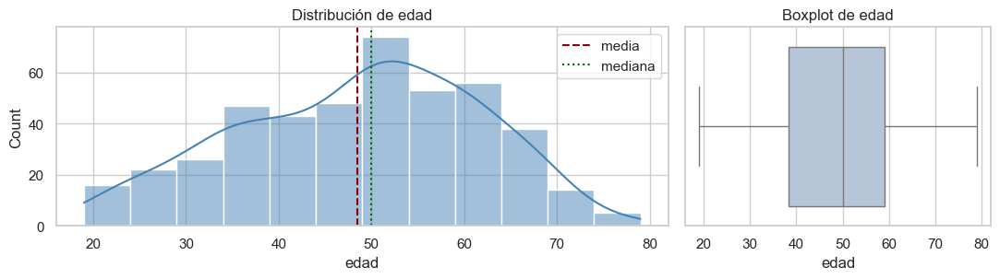

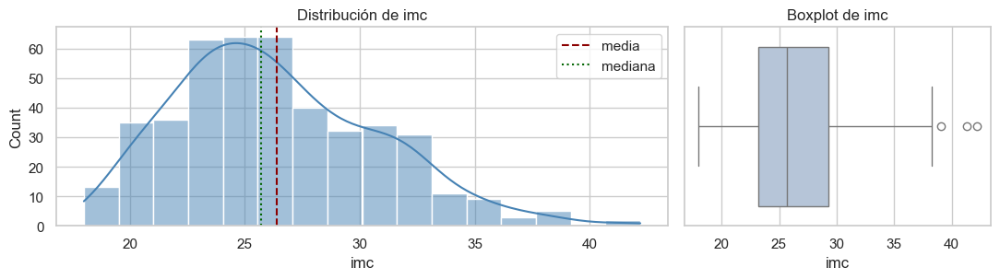

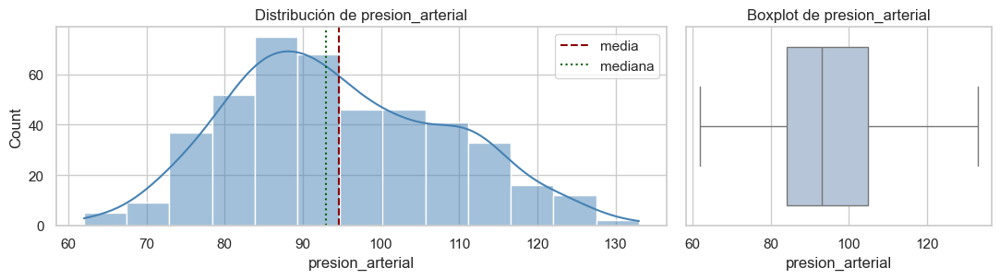

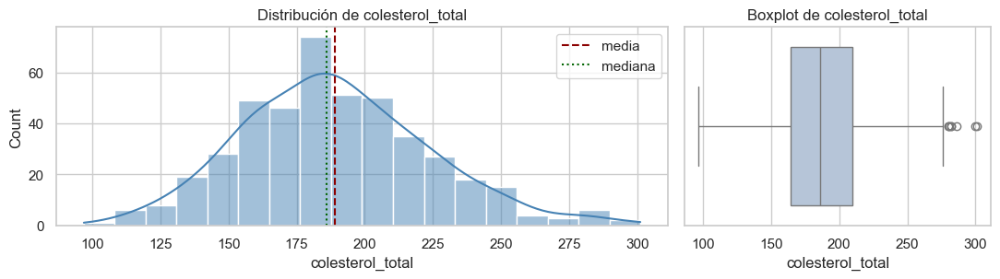

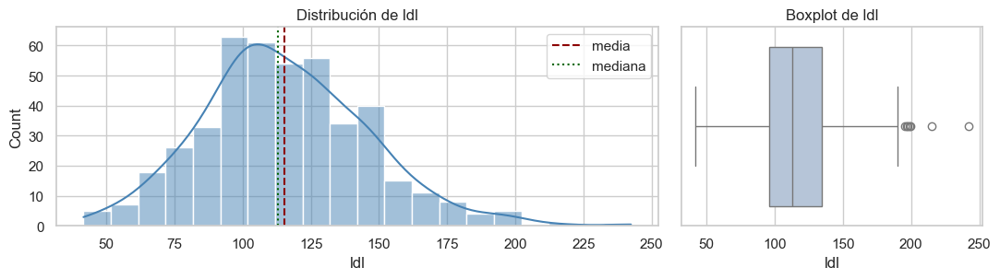

...

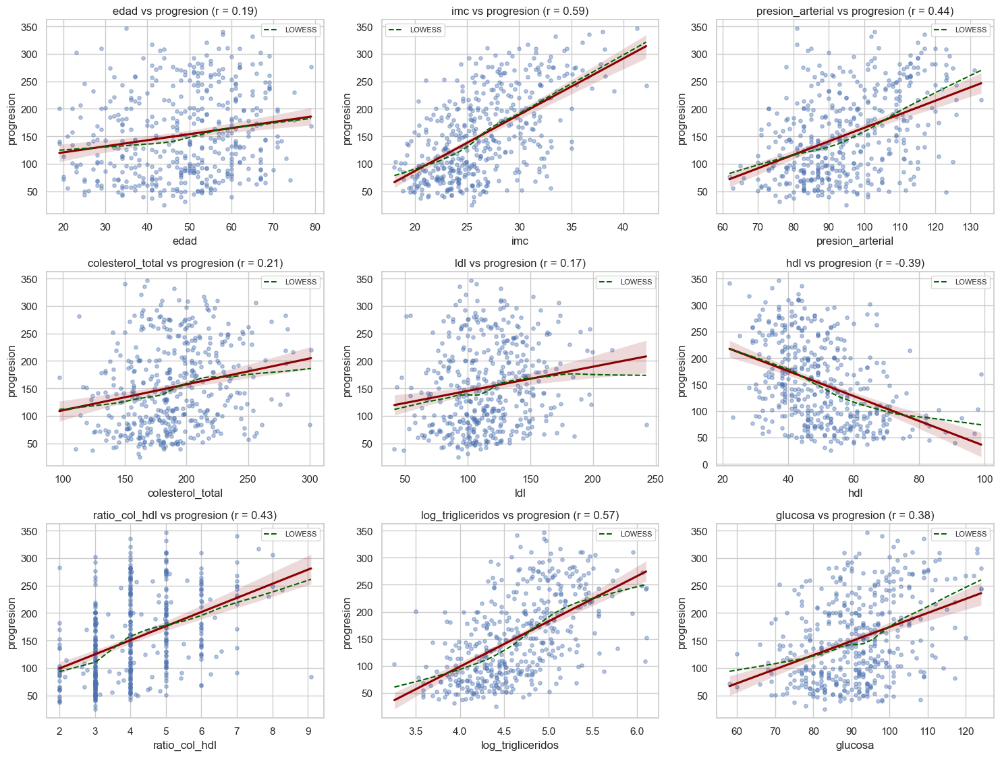

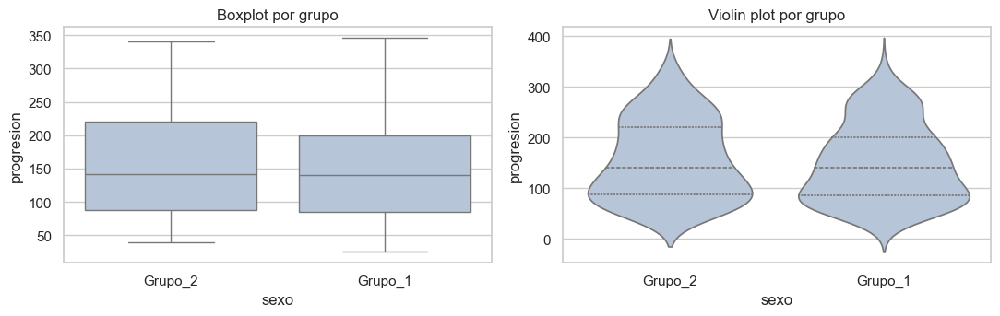

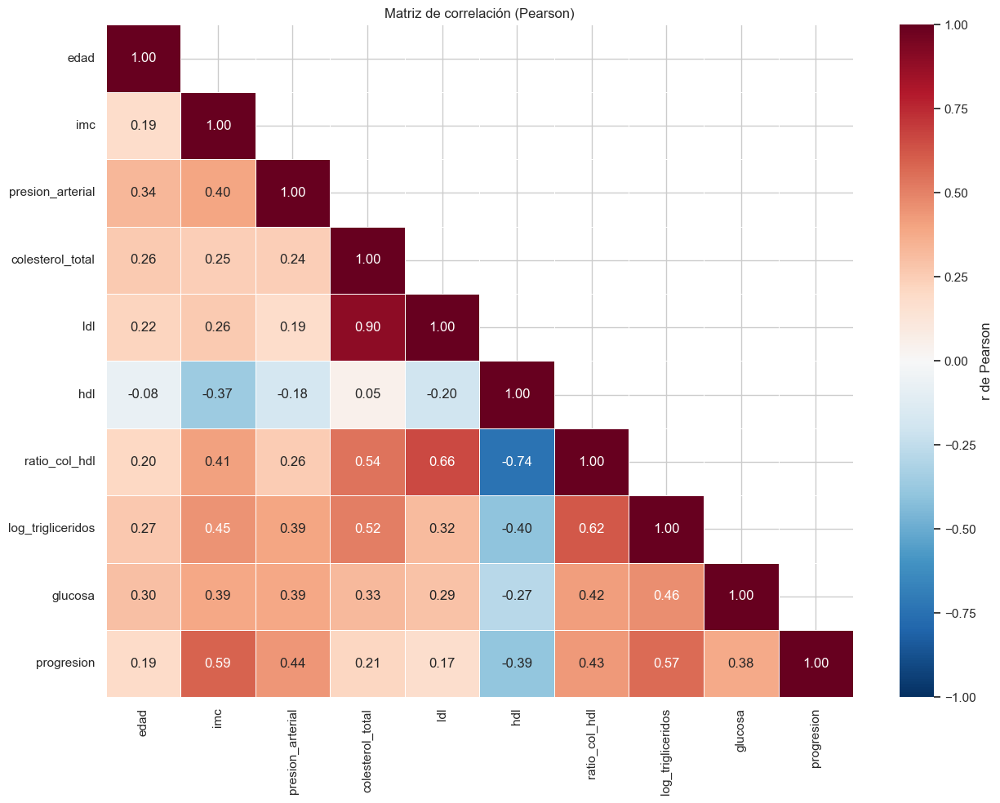

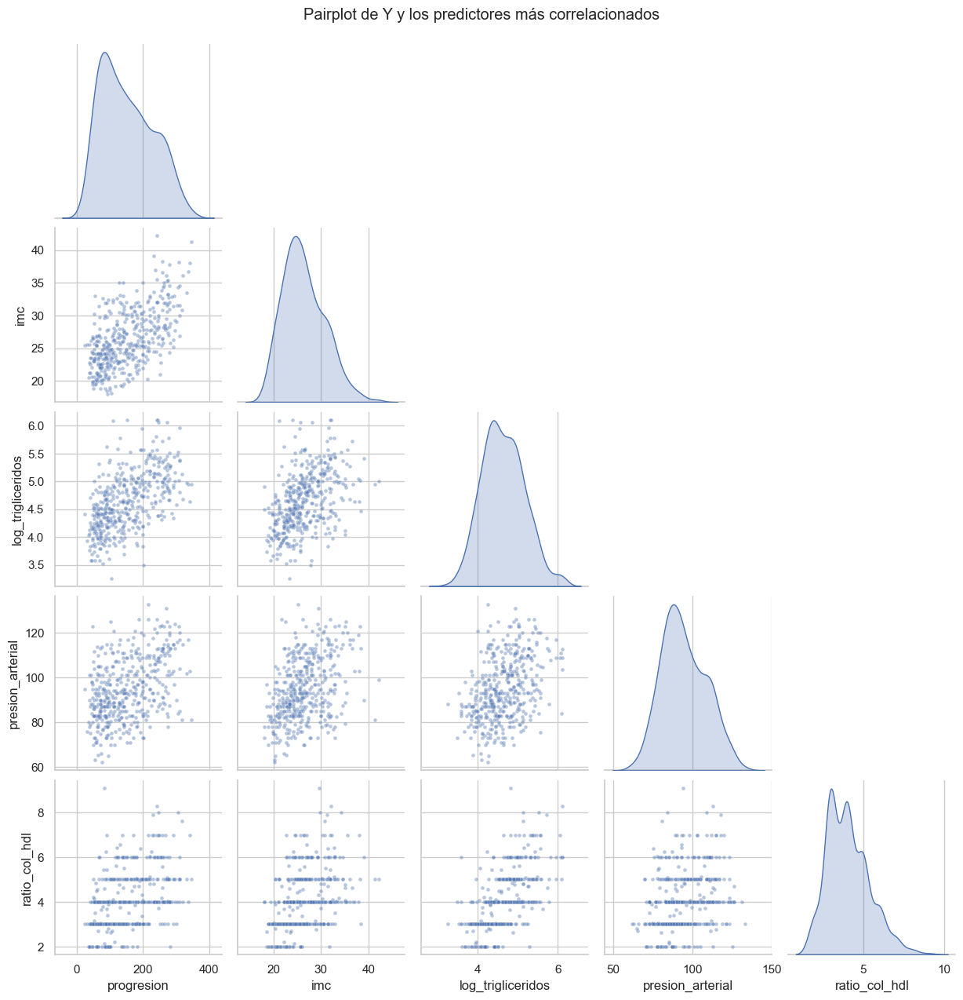

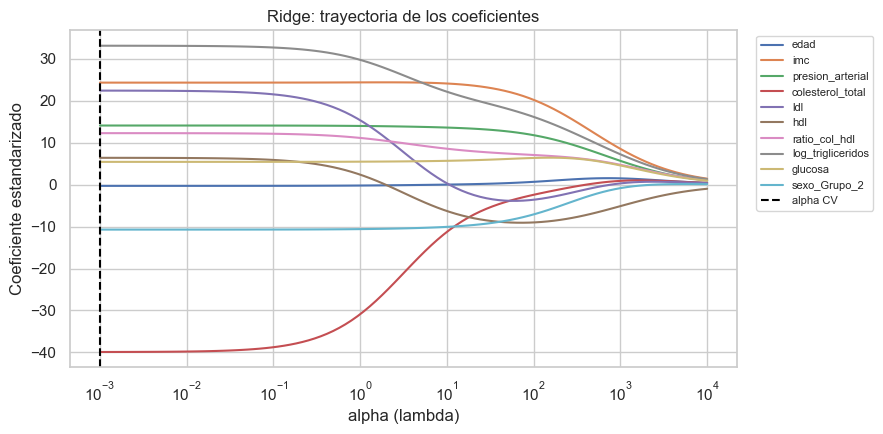

In [51]:
escalador_tmp = StandardScaler().fit(X_train)
X_train_std = escalador_tmp.transform(X_train)
trayectoria_ridge = np.array([Ridge(alpha=a).fit(X_train_std, y_train).coef_ for a in malla_alphas_ridge])

fig, ax = plt.subplots(figsize=(9, 4.5))
for j, nombre in enumerate(X_train.columns):
    ax.plot(malla_alphas_ridge, trayectoria_ridge[:, j], label=nombre)
ax.axvline(alpha_ridge, color="black", ls="--", label="alpha CV")
ax.set_xscale("log"); ax.set_xlabel("alpha (lambda)"); ax.set_ylabel("Coeficiente estandarizado")
ax.set_title("Ridge: trayectoria de los coeficientes")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## 12.2 Lasso (penalización L1)

$$
\min_{\beta}
\left[
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\lambda\sum_{j=1}^{p}|\beta_j|
\right]
$$

El castigo es la **suma de los valores absolutos** de los coeficientes.

**Características:**

- También encoge los coeficientes, pero por la forma de este castigo, **algunos se vuelven exactamente cero**. Una variable con coeficiente cero queda **fuera** del modelo.
- Por eso Lasso **selecciona variables automáticamente**, algo que Ridge no hace.
- Con predictores muy correlacionados, Lasso tiende a quedarse con **uno** y descartar los demás, a veces de forma arbitraria. Por eso su selección puede cambiar con otra muestra.

**Cómo leer la salida:** se muestra el $\lambda$ óptimo, la tabla de coeficientes, la lista de variables que **se mantienen** (coeficiente distinto de cero) y las que **se descartan** (coeficiente igual a cero).

**Nota técnica:** en scikit-learn, la parte del error de Lasso se multiplica por $\frac{1}{2n}$. Esto sólo cambia la escala numérica de $\lambda$; la lógica del método es la misma. `LassoCV` prueba automáticamente 100 valores de $\lambda$.

In [52]:
pipe_lasso = crear_pipeline(LassoCV(cv=kf, max_iter=50000, random_state=RANDOM_STATE))
pipe_lasso.fit(X_train, y_train)

lasso = pipe_lasso.named_steps["modelo"]
print(f"Alpha (lambda) óptimo por validación cruzada: {lasso.alpha_:.4f}")

coef_lasso = pd.DataFrame({
    "coef_estandarizado": pd.Series(lasso.coef_, index=X_train.columns),
    "coef_escala_original": llevar_a_escala_original(pipe_lasso, X_train.columns).drop("const"),
})
display(coef_lasso)

seleccion_lasso_vars = coef_lasso.index[coef_lasso["coef_estandarizado"].abs() > 1e-10].tolist()
descartadas_lasso = [v for v in X_train.columns if v not in seleccion_lasso_vars]
print("Variables con coeficiente distinto de cero:", seleccion_lasso_vars)
print("Variables descartadas por Lasso (coef = 0):", descartadas_lasso if descartadas_lasso else "ninguna")

pred_lasso_test = pipe_lasso.predict(X_test)
print("Desempeño en PRUEBA (Lasso):", {k: round(v, 4) for k, v in metricas_regresion(y_test, pred_lasso_test).items()})

Alpha (lambda) óptimo por validación cruzada: 0.0440


,coef_estandarizado,coef_escala_original
edad,-0.1759,-0.0135
imc,24.3654,5.4557
presion_arterial,13.9743,1.0093
colesterol_total,-33.0365,-0.9409
ldl,17.1720,0.5599
hdl,3.1206,0.2348
ratio_col_hdl,11.0751,8.4233
log_trigliceridos,30.6729,58.3439
glucosa,5.4024,0.4586
sexo_Grupo_2,-10.6151,-21.2611


Variables con coeficiente distinto de cero: ['edad', 'imc', 'presion_arterial', 'colesterol_total', 'ldl', 'hdl', 'ratio_col_hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Variables descartadas por Lasso (coef = 0): ninguna
Desempeño en PRUEBA (Lasso): {'R2': 0.5677, 'MAE': 42.868, 'MSE': 2723.7512, 'RMSE': 52.1896}


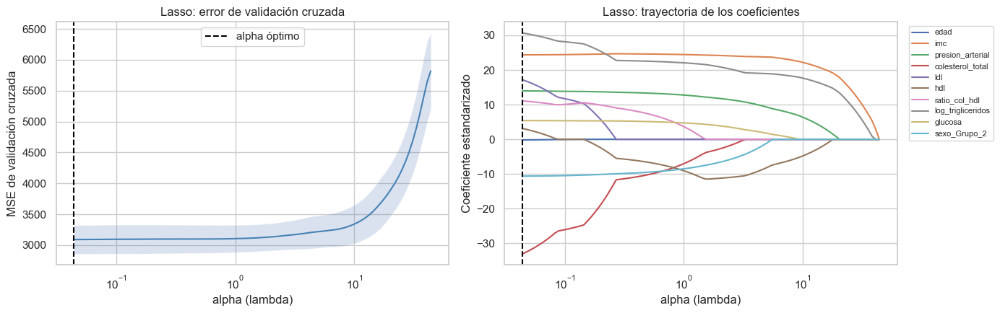

In [53]:
# Curva de validación cruzada y trayectoria de coeficientes de Lasso
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

mse_medio = lasso.mse_path_.mean(axis=1)
mse_de = lasso.mse_path_.std(axis=1)
ejes[0].plot(lasso.alphas_, mse_medio, color="steelblue")
ejes[0].fill_between(lasso.alphas_, mse_medio - mse_de, mse_medio + mse_de, alpha=0.2)
ejes[0].axvline(lasso.alpha_, color="black", ls="--", label="alpha óptimo")
ejes[0].set_xscale("log"); ejes[0].set_xlabel("alpha (lambda)"); ejes[0].set_ylabel("MSE de validación cruzada")
ejes[0].set_title("Lasso: error de validación cruzada"); ejes[0].legend()

trayectoria_lasso = np.array([Lasso(alpha=a, max_iter=50000).fit(X_train_std, y_train).coef_
                              for a in lasso.alphas_])
for j, nombre in enumerate(X_train.columns):
    ejes[1].plot(lasso.alphas_, trayectoria_lasso[:, j], label=nombre)
ejes[1].axvline(lasso.alpha_, color="black", ls="--")
ejes[1].set_xscale("log"); ejes[1].set_xlabel("alpha (lambda)"); ejes[1].set_ylabel("Coeficiente estandarizado")
ejes[1].set_title("Lasso: trayectoria de los coeficientes")
ejes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**Cómo leer estos dos gráficos:**

- **Izquierda, error de validación cruzada:** muestra el error de predicción (MSE) para cada valor de $\lambda$. La franja sombreada indica la variabilidad entre particiones. La línea vertical marca el $\lambda$ con el menor error.
- **Derecha, trayectoria de los coeficientes:** a diferencia de Ridge, aquí las líneas **llegan a cero** y se quedan ahí. Las variables que siguen siendo distintas de cero con castigos fuertes (hacia la derecha) son las que más aportan a la predicción.

### Complemento: la regla de "un error estándar"

A veces la curva de error es casi plana: muchos valores de $\lambda$ predicen prácticamente igual de bien. En ese caso, ¿por qué no elegir el modelo más simple?

La **regla de un error estándar** hace justamente eso: elige el $\lambda$ **más grande** (el que deja menos variables) cuyo error no supera al mínimo en más de un error estándar. Se obtiene un modelo más sencillo con una capacidad predictiva estadísticamente equivalente.

In [54]:
mse_min = mse_medio.min()
error_est = lasso.mse_path_.std(axis=1)[np.argmin(mse_medio)] / np.sqrt(lasso.mse_path_.shape[1])
alpha_1se = lasso.alphas_[mse_medio <= mse_min + error_est].max()
lasso_1se = Lasso(alpha=alpha_1se, max_iter=50000).fit(X_train_std, y_train)
vars_1se = X_train.columns[np.abs(lasso_1se.coef_) > 1e-10].tolist()
print(f"alpha mínimo CV = {lasso.alpha_:.4f} | alpha regla 1-EE = {alpha_1se:.4f}")
print(f"Variables retenidas con la regla 1-EE ({len(vars_1se)}): {vars_1se}")
print(f"Variables descartadas con la regla 1-EE: {[v for v in X_train.columns if v not in vars_1se]}")

alpha mínimo CV = 0.0440 | alpha regla 1-EE = 3.8299
Variables retenidas con la regla 1-EE (6): ['imc', 'presion_arterial', 'hdl', 'log_trigliceridos', 'glucosa', 'sexo_Grupo_2']
Variables descartadas con la regla 1-EE: ['edad', 'colesterol_total', 'ldl', 'ratio_col_hdl']


**Cómo leer el resultado:** compare cuántas variables conserva Lasso con el $\lambda$ mínimo y con la regla de un error estándar. Si la segunda conserva muchas menos variables, significa que varias de ellas aportaban muy poco a la predicción.

Las variables elegidas por Lasso pueden volver a ajustarse con OLS (lo que se llama **OLS post-Lasso**) para obtener coeficientes sin encoger y con p-valores. Este modelo aparece en la tabla comparativa de la Parte 13.

## 12.3 Elastic Net (complementario)

Elastic Net **combina** los dos castigos anteriores:

$$
\min_{\beta}\left[\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat y_i)^2 + \lambda\left(\rho\sum_j|\beta_j| + \frac{1-\rho}{2}\sum_j\beta_j^2\right)\right]
$$

El parámetro $\rho$ (`l1_ratio`) define la mezcla:

- $\rho = 1$: es Lasso puro.
- $\rho$ cercano a 0: se comporta como Ridge.
- Valores intermedios: selecciona variables (como Lasso) pero reparte el efecto entre variables correlacionadas (como Ridge), en lugar de quedarse con una sola.

La validación cruzada elige a la vez el mejor $\lambda$ y el mejor $\rho$. Se incluye como contenido complementario, para comparar.

In [55]:
pipe_enet = crear_pipeline(ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0], cv=kf,
                                        max_iter=50000, random_state=RANDOM_STATE))
pipe_enet.fit(X_train, y_train)
enet = pipe_enet.named_steps["modelo"]
print(f"Elastic Net -> alpha óptimo: {enet.alpha_:.4f} | l1_ratio óptimo: {enet.l1_ratio_}")
coef_enet = pd.Series(enet.coef_, index=X_train.columns, name="coef_estandarizado")
display(coef_enet.to_frame())
seleccion_enet_vars = coef_enet.index[coef_enet.abs() > 1e-10].tolist()
pred_enet_test = pipe_enet.predict(X_test)

Elastic Net -> alpha óptimo: 0.0440 | l1_ratio óptimo: 1.0


,coef_estandarizado
edad,-0.1759
imc,24.3654
presion_arterial,13.9743
colesterol_total,-33.0365
ldl,17.1720
hdl,3.1206
ratio_col_hdl,11.0751
log_trigliceridos,30.6729
glucosa,5.4024
sexo_Grupo_2,-10.6151


---
# PARTE 13. Comparación de todos los modelos

**Qué vamos a hacer:** reunir en una sola tabla todos los modelos construidos y compararlos con las mismas medidas.

**Columnas de la tabla:**

| Columna | Qué mide | ¿A qué modelos aplica? |
|---|---|---|
| `n_variables` | Número de predictores. | Todos |
| `R2_ajustado`, `AIC`, `BIC` | Ajuste penalizado por complejidad. | Sólo OLS (en Ridge, Lasso y Elastic Net aparecen como NA, porque no se calculan de la misma manera). |
| `RMSE_CV_train` | Error de predicción estimado por **validación cruzada** dentro del entrenamiento. | Todos. **Es la medida para comparar y decidir.** |
| `RMSE_test` | Error en el conjunto de prueba. | Todos. Es una **verificación final**, no se usa para elegir. |

El **RMSE** es la raíz del error cuadrático medio: el tamaño típico del error de predicción, en las mismas unidades de $Y$ (se explica en detalle en la Parte 17). **Menor es mejor.**

Para Ridge, Lasso y Elastic Net se usa **validación cruzada anidada**: dentro de cada partición se vuelve a elegir $\lambda$ con otra validación cruzada interna. Así, la elección de $\lambda$ no "hace trampa" usando los datos con los que se evalúa.

In [56]:
def fila_ols(nombre, variables):
    m = ajustar_ols(X_train, y_train, variables)
    pred_test = m.predict(con_constante(X_test[variables]))
    return {"Método": nombre, "n_variables": len(variables), "Variables seleccionadas": ", ".join(variables),
            "R2_ajustado": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic,
            "RMSE_CV_train": rmse_cv(X_train, y_train, variables).mean(),
            "RMSE_test": np.sqrt(mean_squared_error(y_test, pred_test))}


def fila_regularizado(nombre, pipeline, variables_texto, n_vars):
    cv_rmse = -cross_val_score(pipeline, X_train, y_train, cv=kf,
                               scoring="neg_root_mean_squared_error").mean()
    return {"Método": nombre, "n_variables": n_vars, "Variables seleccionadas": variables_texto,
            "R2_ajustado": np.nan, "AIC": np.nan, "BIC": np.nan,
            "RMSE_CV_train": cv_rmse,
            "RMSE_test": np.sqrt(mean_squared_error(y_test, pipeline.predict(X_test)))}


filas = [fila_ols(nombre, vars_) for nombre, vars_ in candidatos_ols.items()]
if seleccion_lasso_vars:
    filas.append(fila_ols("OLS post-Lasso", seleccion_lasso_vars))
if vars_1se:
    filas.append(fila_ols("OLS post-Lasso (regla 1-EE)", vars_1se))
filas.append(fila_regularizado("Lasso", pipe_lasso, ", ".join(seleccion_lasso_vars), len(seleccion_lasso_vars)))
filas.append(fila_regularizado("Ridge", pipe_ridge, "Todas", X_train.shape[1]))
filas.append(fila_regularizado("Elastic Net (opcional)", pipe_enet, ", ".join(seleccion_enet_vars), len(seleccion_enet_vars)))

tabla_comparacion = pd.DataFrame(filas).set_index("Método")
display(tabla_comparacion.style
        .format({"R2_ajustado": "{:.4f}", "AIC": "{:.2f}", "BIC": "{:.2f}",
                 "RMSE_CV_train": "{:.3f}", "RMSE_test": "{:.3f}"}, na_rep="NA")
        .highlight_min(subset=["RMSE_CV_train"], color="#d4edda"))

,n_variables,Variables seleccionadas,R2_ajustado,AIC,BIC,RMSE_CV_train,RMSE_test
Método,,,,,,,
Completo,10,"edad, imc, presion_arterial, colesterol_total, ldl, hdl, ratio_col_hdl, log_trigliceridos, glucosa, sexo_Grupo_2",0.4870,3839.14,3881.68,55.524,52.194
Backward (p-valor),6,"imc, presion_arterial, colesterol_total, ratio_col_hdl, log_trigliceridos, sexo_Grupo_2",0.4865,3835.54,3862.61,55.163,51.868
Forward (p-valor),5,"imc, log_trigliceridos, presion_arterial, hdl, sexo_Grupo_2",0.4815,3838.00,3861.20,55.342,51.689
Stepwise (p-valor),5,"imc, log_trigliceridos, presion_arterial, hdl, sexo_Grupo_2",0.4815,3838.00,3861.20,55.342,51.689
Backward (AIC),7,"imc, presion_arterial, colesterol_total, ratio_col_hdl, log_trigliceridos, glucosa, sexo_Grupo_2",0.4886,3835.08,3866.01,55.585,52.501
Backward (BIC),6,"imc, presion_arterial, colesterol_total, ratio_col_hdl, log_trigliceridos, sexo_Grupo_2",0.4865,3835.54,3862.61,55.163,51.868
OLS post-Lasso,10,"edad, imc, presion_arterial, colesterol_total, ldl, hdl, ratio_col_hdl, log_trigliceridos, glucosa, sexo_Grupo_2",0.4870,3839.14,3881.68,55.524,52.194
OLS post-Lasso (regla 1-EE),6,"imc, presion_arterial, hdl, log_trigliceridos, glucosa, sexo_Grupo_2",0.4827,3838.19,3865.26,55.760,52.202
Lasso,10,"edad, imc, presion_arterial, colesterol_total, ldl, hdl, ratio_col_hdl, log_trigliceridos, glucosa, sexo_Grupo_2",NA,NA,NA,55.754,52.190


**Cómo leer la tabla:**

- La celda verde marca el modelo con **menor RMSE de validación cruzada**.
- Si varios modelos tienen RMSE muy parecidos (diferencias menores que la variabilidad entre particiones que se verá en la Parte 19), **no hay un ganador claro** en predicción. En ese caso, conviene preferir el modelo **más simple e interpretable**.
- Ridge y Lasso se comparan sobre todo por su **capacidad predictiva**. Los modelos OLS, además, permiten **inferencia estadística** (p-valores, intervalos de confianza, pruebas de supuestos).

### Preguntas de reflexión

1. ¿Qué modelo tiene el menor RMSE de validación cruzada? ¿La diferencia con los demás es importante o mínima?
2. ¿Los modelos con menos variables predicen peor que el completo? Si predicen igual, ¿qué significa?
3. ¿Qué variables aparecen en casi todos los métodos? Esas son las más confiables.
4. ¿Ridge o Lasso mejoran claramente a OLS? ¿Qué sugiere eso sobre el efecto de la multicolinealidad en la predicción?

---
# PARTE 14. Selección del modelo final

**Qué vamos a hacer:** elegir el modelo que se va a interpretar, validar y usar para predecir.

La elección **no es automática** ni depende de un solo número. Un buen modelo final equilibra varios criterios:

| Criterio | Pregunta |
|---|---|
| Fundamento conceptual | ¿Las variables tienen sentido y los signos son los esperados? |
| Parsimonia | ¿Existe un modelo más simple que funcione casi igual? |
| Multicolinealidad | ¿Los VIF son aceptables? |
| Ajuste | ¿Cómo son el $R^2$ ajustado, el AIC y el BIC? |
| Supuestos | ¿Los residuos cumplen razonablemente los supuestos? (se verifica en la Parte 15) |
| Estabilidad | ¿Las variables aparecen en varios métodos de selección? |
| Capacidad predictiva | ¿Cómo es su RMSE de validación cruzada frente a los demás? |
| Interpretabilidad | ¿Se puede explicar a alguien que no es especialista? |

**Recomendaciones:**

- El modelo que se presente como **ecuación** debería ser un modelo **OLS**, porque permite interpretar coeficientes con p-valores e intervalos de confianza.
- **Lasso** es útil como apoyo para identificar qué variables vale la pena conservar.
- **Ridge** sirve como punto de comparación cuando hay multicolinealidad o interés principal en predecir.

### Configuración: ¿qué variables tendrá el modelo final?

La lista `predictores_finales` define el modelo final. **Esta es la decisión más importante del análisis** y debe tomarla usted, con base en la tabla comparativa y en los criterios anteriores.

Por defecto se usa el resultado de **Stepwise**, sólo para que el cuadernillo pueda ejecutarse completo. Eso **no significa** que sea el mejor modelo para sus datos.

**Opciones disponibles** (escriba una de ellas después del signo `=`):

| Escriba | Para usar |
|---|---|
| `list(X_train.columns)` | Todas las variables (modelo completo) |
| `list(seleccion_backward_vars)` | El resultado de Backward |
| `list(seleccion_forward_vars)` | El resultado de Forward |
| `list(seleccion_stepwise_vars)` | El resultado de Stepwise |
| `list(seleccion_aic_vars)` | El resultado de Backward por AIC |
| `list(seleccion_lasso_vars)` | Las variables que conserva Lasso |
| `["imc", "presion_arterial", "hdl"]` | Una lista escrita a mano (use los nombres exactos de las columnas de `X_train`; las dummies se llaman, por ejemplo, `sexo_Grupo_2`) |

**Cómo leer la salida:** se muestran el resumen completo del modelo final, su tabla de coeficientes, su ecuación, una interpretación redactada de cada coeficiente y sus VIF.

In [57]:
# ===============================================================
# CONFIGURACIÓN: variables del modelo final (ver la tabla de opciones de la celda anterior)
# Por defecto: resultado de Stepwise, sólo para que el cuadernillo se ejecute completo.
# ===============================================================
predictores_finales = list(seleccion_stepwise_vars)

assert len(predictores_finales) > 0, "El modelo final debe tener al menos un predictor."
print("Predictores del modelo final:", predictores_finales)

modelo_final = ajustar_ols(X_train, y_train, predictores_finales)
modelo_final.summary()

Predictores del modelo final: ['imc', 'log_trigliceridos', 'presion_arterial', 'hdl', 'sexo_Grupo_2']


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             progresion   R-squared:                       0.489
Model:                            OLS   Adj. R-squared:                  0.482
Method:                 Least Squares   F-statistic:                     66.38
Date:                Fri, 25 Sep 2026   Prob (F-statistic):           1.60e-48
Time:                        19:52:39   Log-Likelihood:                -1913.0
No. Observations:                 353   AIC:                             3838.
Df Residuals:                     347   BIC:                             3861.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              -212.7210     39.006     -5.454      0.000    -289.438    -136.004
imc                   5.5739      0.782      7.131      0.000       4.037       7.111
log_trigliceridos    39.8917      6.650      5.999      0.000      26.812      52.971
presion_arterial      1.0466      0.240      4.369      0.000       0.575       1.518
hdl                  -1.1399      0.270     -4.224      0.000      -1.671      -0.609
sexo_Grupo_2        -20.1158      6.556     -3.068      0.002     -33.011      -7.221
==============================================================================
Omnibus:                        1.424   Durbin-Watson:                   2.176
Prob(Omnibus):                  0.491   Jarque-Bera (JB):                1.325
Skew:                           0.014   Prob(JB):                        0.516
Kurtosis:                       2.701   Cond. No.                     1.48e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.48e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [58]:
display(Markdown("### Coeficientes del modelo final"))
tabla_coef_final = tabla_coeficientes(modelo_final)
display(tabla_coef_final)
display(resumen_global(modelo_final).to_frame("modelo final"))

display(Markdown("### Ecuación estimada del modelo final"))
ec_final_texto, ec_final_latex = ecuacion_modelo(modelo_final.params, variable_objetivo, decimales=3)
print(ec_final_texto)
display(Math(ec_final_latex))

display(Markdown("### Interpretación (borrador a revisar)"))
display(Markdown(interpretar_coeficientes(modelo_final, variable_objetivo, columnas_dummy)))

display(Markdown("### VIF del modelo final"))
tabla_vif_final = calcular_vif(X_train[predictores_finales]) if len(predictores_finales) > 1 else \
    pd.DataFrame({"Variable": predictores_finales, "VIF": [1.0], "lectura": ["un solo predictor"]})
display(tabla_vif_final)

### Coeficientes del modelo final

,coeficiente,error_estandar,t,p_valor,IC_95%_inf,IC_95%_sup,significativo
const,-212.7210,39.0057,-5.4536,0.0000,-289.4384,-136.0037,sí
imc,5.5739,0.7817,7.1310,0.0000,4.0366,7.1113,sí
log_trigliceridos,39.8917,6.6502,5.9986,0.0000,26.8119,52.9714,sí
presion_arterial,1.0466,0.2395,4.3689,0.0000,0.5754,1.5177,sí
hdl,-1.1399,0.2699,-4.2238,0.0000,-1.6707,-0.6091,sí
sexo_Grupo_2,-20.1158,6.5564,-3.0681,0.0023,-33.0110,-7.2205,sí


,modelo final
n,353.0000
p (predictores),5.0000
R2,0.4889
R2_ajustado,0.4815
F,66.3839
p_valor_F,0.0000
AIC,"3,837.9964"
BIC,"3,861.1952"
sigma_residual,55.0858


### Ecuación estimada del modelo final

progresion_estimado = -212.721 + 5.574*imc + 39.892*log_trigliceridos + 1.047*presion_arterial - 1.140*hdl - 20.116*sexo_Grupo_2


<IPython.core.display.Math object>

### Interpretación (borrador a revisar)

- **Intercepto:** valor esperado de progresion cuando todos los predictores valen 0: -212.7210. Evalúe si ese escenario tiene sentido.
- **imc:** controlando por las demás variables del modelo, un incremento de una unidad en imc se asocia con una aumento promedio de 5.5739 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **log_trigliceridos:** controlando por las demás variables del modelo, un incremento de una unidad en log_trigliceridos se asocia con una aumento promedio de 39.8917 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **presion_arterial:** controlando por las demás variables del modelo, un incremento de una unidad en presion_arterial se asocia con una aumento promedio de 1.0466 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **hdl:** controlando por las demás variables del modelo, un incremento de una unidad en hdl se asocia con una disminución promedio de 1.1399 unidades en progresion; estadísticamente significativo (p = 0.0000).
- **sexo_Grupo_2:** controlando por las demás variables, esta categoría presenta en promedio un valor de progresion 20.1158 unidades menor que la categoría de referencia; estadísticamente significativo (p = 0.0023).

### VIF del modelo final

,Variable,VIF,lectura
0,hdl,1.4969,baja/moderada
1,log_trigliceridos,1.4219,baja/moderada
2,imc,1.4176,baja/moderada
3,presion_arterial,1.2797,baja/moderada
4,sexo_Grupo_2,1.2465,baja/moderada


---
# PARTE 15. Validación de supuestos

**Qué vamos a hacer:** revisar si el modelo final cumple las condiciones que la regresión lineal necesita para que sus resultados sean confiables.

**Por qué:** los p-valores, los intervalos de confianza y los intervalos de predicción de OLS se calculan **suponiendo** ciertas condiciones. Si no se cumplen, esos números pueden ser engañosos. Las predicciones puntuales pueden seguir siendo útiles con violaciones leves, pero la inferencia (decir "esta variable es significativa") pierde respaldo.

**La herramienta principal son los residuos.** El residuo de cada observación es la diferencia entre lo observado y lo que predice el modelo:

$$
e_i = y_i - \hat y_i
$$

Si el modelo está bien planteado, los residuos deberían comportarse como "ruido": sin patrones, centrados en cero y con dispersión similar en todo el rango. Cualquier patrón en los residuos es una señal de que el modelo está dejando algo sin capturar.

| Supuesto | En palabras sencillas | Cómo se revisa |
|---|---|---|
| **Linealidad** | La relación entre $Y$ y los predictores es una línea recta (no una curva). | Gráfico de residuos vs valores ajustados; prueba Rainbow |
| **Normalidad** | Los errores siguen una distribución en forma de campana. | Histograma, Q-Q plot, pruebas de Shapiro-Wilk y Jarque-Bera |
| **Homocedasticidad** | El tamaño de los errores es parecido para valores bajos y altos de $Y$. | Gráfico de residuos; prueba de Breusch-Pagan |
| **Independencia** | El error de una observación no depende del error de otra. | Estadístico de Durbin-Watson |
| **Sin observaciones dominantes** | Ningún caso individual determina por sí solo los resultados. | Residuos estudentizados, leverage, distancia de Cook |

Todos los diagnósticos se hacen con los residuos del modelo final en los datos de **entrenamiento**.

In [59]:
residuos = modelo_final.resid
ajustados = modelo_final.fittedvalues
influencia = modelo_final.get_influence()
residuos_estud = influencia.resid_studentized_external
n_train, p_final = int(modelo_final.nobs), int(modelo_final.df_model)
print(f"n = {n_train}, p = {p_final}, media de residuos = {residuos.mean():.2e} (debe ser ≈ 0)")

n = 353, p = 5, media de residuos = -2.68e-13 (debe ser ≈ 0)


## 15.1 Linealidad

**Qué se verifica:** que una línea recta (o un plano, con varios predictores) sea una buena descripción de la relación entre los predictores y $Y$.

**Gráfico de residuos vs valores ajustados:** en el eje horizontal están los valores que predice el modelo; en el vertical, los residuos.

| Lo que se ve | Qué significa |
|---|---|
| Nube de puntos sin forma, alrededor de la línea horizontal en 0; la curva roja (LOWESS) casi plana | **Bien**: la relación lineal es adecuada. |
| Forma de **U** o de U invertida; curva roja claramente curvada | **Problema**: la relación no es lineal. Puede faltar una variable, un término cuadrático o una transformación (logaritmo). |

**Prueba Rainbow:** complementa el gráfico con un número.

- Hipótesis nula ($H_0$): la relación es lineal.
- Si el p-valor es **mayor que 0.05**, no hay evidencia contra la linealidad.
- Si es **menor que 0.05**, hay evidencia de que la relación no es lineal.

Después se muestran los residuos frente a **cada predictor numérico** por separado, para identificar cuál variable, en particular, podría tener una relación curva.

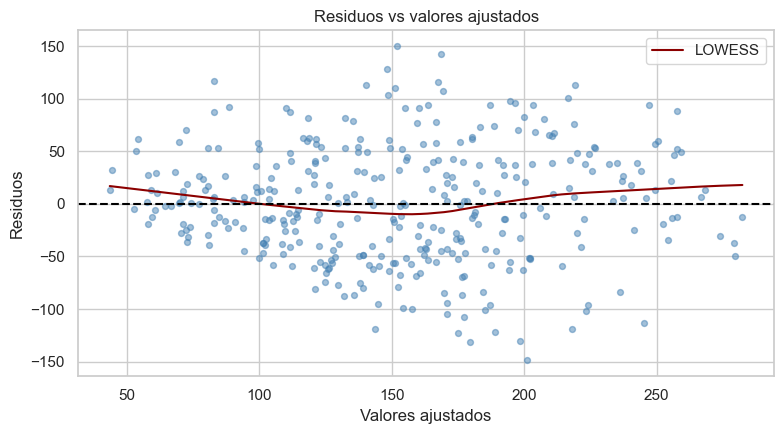

Prueba Rainbow de linealidad: estadístico = 1.2223, p-valor = 0.0939


In [60]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(ajustados, residuos, alpha=0.5, s=18, color="steelblue")
suav = sm.nonparametric.lowess(residuos, ajustados, frac=0.6)
ax.plot(suav[:, 0], suav[:, 1], color="darkred", label="LOWESS")
ax.axhline(0, color="black", ls="--")
ax.set_xlabel("Valores ajustados"); ax.set_ylabel("Residuos")
ax.set_title("Residuos vs valores ajustados"); ax.legend()
plt.tight_layout(); plt.show()

rainbow_est, rainbow_p = linear_rainbow(modelo_final)
print(f"Prueba Rainbow de linealidad: estadístico = {rainbow_est:.4f}, p-valor = {rainbow_p:.4f}")

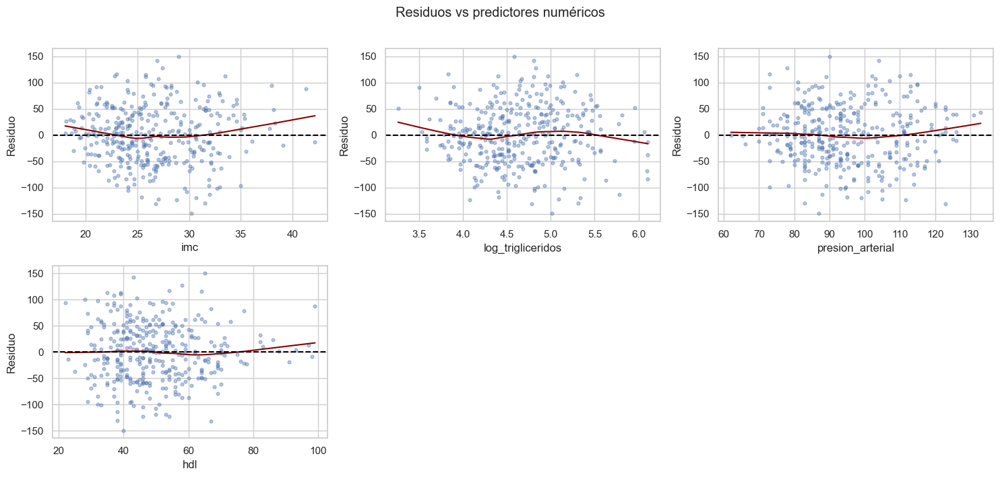

In [61]:
# Residuos frente a cada predictor numérico del modelo final
num_finales = [v for v in predictores_finales if v in pred_numericos]
if num_finales:
    n_col = 3
    n_fil = int(np.ceil(len(num_finales) / n_col))
    fig, ejes = plt.subplots(n_fil, n_col, figsize=(5 * n_col, 3.5 * n_fil), squeeze=False)
    for ax, var in zip(ejes.flat, num_finales):
        ax.scatter(X_train[var], residuos, alpha=0.4, s=12)
        s_ = sm.nonparametric.lowess(residuos, X_train[var], frac=0.6)
        ax.plot(s_[:, 0], s_[:, 1], color="darkred")
        ax.axhline(0, color="black", ls="--"); ax.set_xlabel(var); ax.set_ylabel("Residuo")
    for ax in list(ejes.flat)[len(num_finales):]:
        ax.set_visible(False)
    fig.suptitle("Residuos vs predictores numéricos", y=1.01)
    plt.tight_layout(); plt.show()

## 15.2 Normalidad de los residuos

**Qué se verifica:** que los errores del modelo tengan una distribución aproximadamente normal (forma de campana), centrada en cero.

**Por qué importa:** los p-valores y los intervalos de confianza de OLS se calculan suponiendo normalidad. Con muestras grandes, este supuesto es menos crítico (gracias al teorema central del límite), pero con muestras pequeñas es importante.

**Herramientas:**

| Herramienta | Qué mirar |
|---|---|
| **Histograma + curva** | Debe parecerse a la curva normal teórica (línea roja punteada): simétrico y centrado en 0. |
| **Q-Q plot** | Compara los residuos con los valores que tendría una normal perfecta. Los puntos deben seguir la **línea diagonal**. Si se separan en los extremos formando una "S" o una curva, hay colas pesadas o asimetría. |
| **Prueba de Shapiro-Wilk** | $H_0$: los residuos son normales. p-valor > 0.05: no hay evidencia contra la normalidad. Se recomienda hasta 5000 observaciones. |
| **Prueba de Jarque-Bera** | Misma hipótesis; se basa en la asimetría (ideal 0) y la curtosis (ideal 3) de los residuos. |

**Cuidado con las pruebas de normalidad:**

- Con muestras **grandes** (miles de datos), detectan diferencias mínimas sin importancia práctica y casi siempre "rechazan" la normalidad.
- Con muestras **pequeñas**, tienen poca capacidad para detectar problemas reales.

Por eso **siempre se leen junto con los gráficos**. Si el Q-Q plot se ve razonablemente recto, una prueba significativa con una muestra grande no es motivo de alarma.

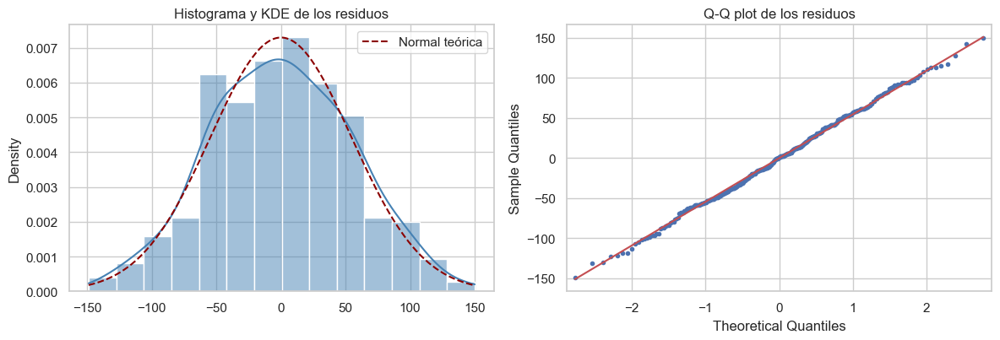

Shapiro-Wilk: W = 0.9971, p-valor = 0.7977
Jarque-Bera: JB = 1.3248, p-valor = 0.5156 | asimetría = 0.014, curtosis = 2.701


In [62]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(residuos, kde=True, ax=ejes[0], color="steelblue", stat="density")
x_ = np.linspace(residuos.min(), residuos.max(), 200)
ejes[0].plot(x_, stats.norm.pdf(x_, residuos.mean(), residuos.std()), color="darkred", ls="--", label="Normal teórica")
ejes[0].set_title("Histograma y KDE de los residuos"); ejes[0].legend()
sm.qqplot(residuos, line="s", ax=ejes[1], markersize=3)
ejes[1].set_title("Q-Q plot de los residuos")
plt.tight_layout(); plt.show()

if len(residuos) <= 5000:
    sw_est, sw_p = stats.shapiro(residuos)
    print(f"Shapiro-Wilk: W = {sw_est:.4f}, p-valor = {sw_p:.4f}")
else:
    sw_est, sw_p = np.nan, np.nan
    print("Shapiro-Wilk no se aplica (n > 5000); use Jarque-Bera y los gráficos.")
jb_est, jb_p, jb_asim, jb_curt = jarque_bera(residuos)
print(f"Jarque-Bera: JB = {jb_est:.4f}, p-valor = {jb_p:.4f} | asimetría = {jb_asim:.3f}, curtosis = {jb_curt:.3f}")

## 15.3 Homocedasticidad (varianza constante)

**Qué se verifica:** que la dispersión de los errores sea **similar** en todo el rango de predicciones. La palabra viene del griego: *homo* (igual) y *skedasis* (dispersión).

**Ejemplo del problema contrario (heterocedasticidad):** al predecir el gasto de los hogares, el error suele ser pequeño en hogares de bajos ingresos (todos gastan parecido) y grande en hogares de altos ingresos (unos gastan mucho, otros poco). La dispersión crece con el nivel.

**Gráficos:**

- **Residuos vs ajustados (izquierda):** la nube debería tener un ancho parecido de izquierda a derecha. Una forma de **embudo** o **abanico** (se abre o se cierra) indica heterocedasticidad.
- **Escala-localización (derecha):** muestra la raíz del tamaño de los residuos estandarizados. La curva roja debería ser aproximadamente **horizontal**; si sube o baja, la dispersión cambia con el nivel de $Y$.

**Prueba de Breusch-Pagan:**

$$
H_0: \text{la varianza de los errores es constante} \qquad H_1: \text{la varianza depende de los predictores}
$$

- p-valor > 0.05: no hay evidencia de heterocedasticidad.
- p-valor < 0.05: hay evidencia de heterocedasticidad.

**¿Qué pasa si hay heterocedasticidad?** Los coeficientes siguen siendo correctos en promedio, pero sus **errores estándar** están mal calculados, y con ellos los p-valores y los intervalos de confianza. Soluciones habituales:

- transformar $Y$ (por ejemplo, con logaritmo);
- usar **errores estándar robustos** (llamados HC3), que corrigen el cálculo sin cambiar los coeficientes. La siguiente celda los calcula para comparar.

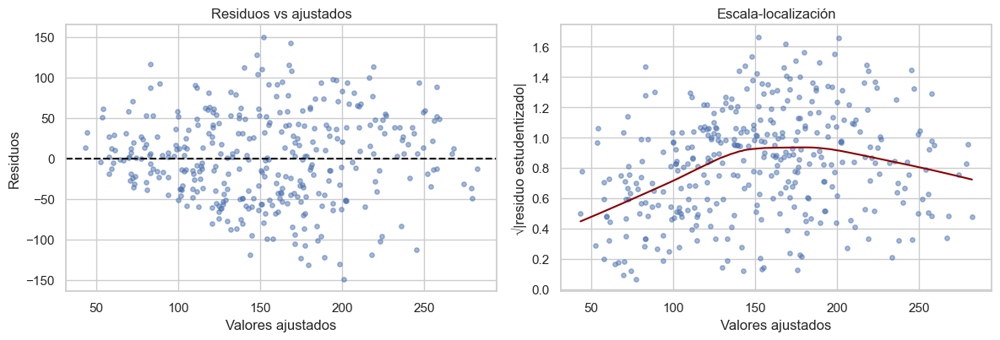

Breusch-Pagan: LM = 15.8767, p-valor = 0.0072 | F = 3.2684, p-valor = 0.0067


In [63]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
ejes[0].scatter(ajustados, residuos, alpha=0.5, s=15)
ejes[0].axhline(0, color="black", ls="--")
ejes[0].set_xlabel("Valores ajustados"); ejes[0].set_ylabel("Residuos"); ejes[0].set_title("Residuos vs ajustados")

raiz_abs = np.sqrt(np.abs(residuos_estud))
ejes[1].scatter(ajustados, raiz_abs, alpha=0.5, s=15)
s_ = sm.nonparametric.lowess(raiz_abs, ajustados, frac=0.6)
ejes[1].plot(s_[:, 0], s_[:, 1], color="darkred")
ejes[1].set_xlabel("Valores ajustados"); ejes[1].set_ylabel("√|residuo estudentizado|")
ejes[1].set_title("Escala-localización")
plt.tight_layout(); plt.show()

bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(residuos, modelo_final.model.exog)
print(f"Breusch-Pagan: LM = {bp_lm:.4f}, p-valor = {bp_lm_p:.4f} | F = {bp_f:.4f}, p-valor = {bp_f_p:.4f}")

In [64]:
# Complemento: comparación con errores estándar robustos a heterocedasticidad (HC3)
modelo_final_hc3 = sm.OLS(y_train, con_constante(X_train[predictores_finales])).fit(cov_type="HC3")
display(pd.DataFrame({
    "coef": modelo_final.params, "SE_clasico": modelo_final.bse, "p_clasico": modelo_final.pvalues,
    "SE_robusto_HC3": modelo_final_hc3.bse, "p_robusto_HC3": modelo_final_hc3.pvalues,
}))

,coef,SE_clasico,p_clasico,SE_robusto_HC3,p_robusto_HC3
const,-212.7210,39.0057,0.0000,36.5265,0.0000
imc,5.5739,0.7817,0.0000,0.8187,0.0000
log_trigliceridos,39.8917,6.6502,0.0000,6.8433,0.0000
presion_arterial,1.0466,0.2395,0.0000,0.2489,0.0000
hdl,-1.1399,0.2699,0.0000,0.2539,0.0000
sexo_Grupo_2,-20.1158,6.5564,0.0023,6.4598,0.0018


**Cómo leer la comparación:** la tabla muestra, para cada coeficiente, el error estándar y el p-valor clásicos junto a los robustos (HC3). Si las conclusiones no cambian (las variables significativas siguen siéndolo), la heterocedasticidad no altera las conclusiones del modelo. Si alguna variable deja de ser significativa con los errores robustos, conviene reportar la versión robusta.

## 15.4 Independencia de los errores

**Qué se verifica:** que el error de una observación no esté relacionado con el de la siguiente.

**Cuándo importa:** sobre todo con datos que tienen un **orden natural**, como series de tiempo (ventas mes a mes) o mediciones sucesivas. Si un mes el modelo subestima y el siguiente también, los errores están "encadenados" (**autocorrelación**).

**Estadístico de Durbin-Watson (DW):** toma valores entre 0 y 4.

| Valor de DW | Lectura (orientativa) |
|---|---|
| Cercano a 2 (entre 1.5 y 2.5) | Sin autocorrelación |
| Menor que 1.5 | Posible autocorrelación positiva (errores consecutivos parecidos) |
| Mayor que 2.5 | Posible autocorrelación negativa (errores consecutivos alternan de signo) |

Con datos de **corte transversal** (por ejemplo, pacientes o encuestados sin un orden particular), el valor depende del orden arbitrario de las filas y tiene poca relevancia. En ese caso, la independencia se garantiza principalmente por la **forma en que se recolectaron los datos** (por ejemplo, un muestreo aleatorio).

In [65]:
dw = durbin_watson(residuos)
print(f"Durbin-Watson: {dw:.4f}")

Durbin-Watson: 2.1761


## 15.5 Observaciones atípicas e influyentes

**Qué se verifica:** si hay observaciones individuales que se ajustan muy mal al modelo o que tienen un peso desproporcionado en los resultados.

Hay que distinguir tres conceptos:

| Medida | Qué detecta | Analogía | Umbral orientativo |
|---|---|---|---|
| **Residuo estudentizado** | Observaciones con un valor de $Y$ muy distinto al que predice el modelo (**atípicos en $Y$**). | Un estudiante que saca una nota muy distinta a la que se esperaría por sus horas de estudio. | $|r_i| > 3$ (mayor que 2 merece revisión) |
| **Leverage** ($h_{ii}$) | Observaciones con valores **extremos o inusuales en los predictores**. Tienen "palanca" para mover la recta. | Un estudiante que estudió 80 horas cuando los demás estudiaron entre 5 y 20. | $h_{ii} > 2(p+1)/n$ |
| **Distancia de Cook** ($D_i$) | Cuánto **cambiarían todos los coeficientes** si se eliminara esa observación. Combina las dos anteriores: una observación es **influyente** cuando es atípica **y** tiene alto leverage. | El caso que, si se retira, cambia la conclusión del estudio. | $D_i > 4/n$ (revisar); $D_i > 1$ (muy influyente) |

($p$ es el número de predictores y $n$ el número de observaciones.)

**Regla fundamental: no elimine observaciones automáticamente.** Para cada caso señalado, pregúntese:

- ¿Es un **error** de digitación o de medición? Si es así, corríjalo o retírelo, dejando constancia.
- ¿Pertenece a **otra población** (por ejemplo, un dato de una empresa gigante en una base de pymes)?
- ¿Es un **valor real**, aunque extremo? Entonces forma parte del fenómeno y debe conservarse.

Si decide excluir alguna observación, compare los resultados del modelo **con y sin** ella.

**Cómo leer la salida:** primero se muestran los umbrales y cuántas observaciones los superan. Luego, la tabla de las 10 observaciones con mayor distancia de Cook (el número de la izquierda es el número de fila en la base original, para que pueda ubicarla).

In [66]:
distancia_cook = influencia.cooks_distance[0]
leverage = influencia.hat_matrix_diag
umbral_cook = 4 / n_train
umbral_lev = 2 * (p_final + 1) / n_train

tabla_influencia = pd.DataFrame({
    "residuo_estudentizado": residuos_estud, "leverage": leverage, "cook": distancia_cook,
}, index=X_train.index)
tabla_influencia["atipico_|r|>3"] = tabla_influencia["residuo_estudentizado"].abs() > 3
tabla_influencia["alto_leverage"] = tabla_influencia["leverage"] > umbral_lev
tabla_influencia["cook>4/n"] = tabla_influencia["cook"] > umbral_cook

print(f"Umbrales -> Cook: 4/n = {umbral_cook:.4f} | leverage: 2(p+1)/n = {umbral_lev:.4f}")
print(f"Atípicos (|r|>3): {tabla_influencia['atipico_|r|>3'].sum()} | "
      f"Alto leverage: {tabla_influencia['alto_leverage'].sum()} | "
      f"Cook > 4/n: {tabla_influencia['cook>4/n'].sum()} | Cook > 1: {(distancia_cook > 1).sum()}")

display(Markdown("**Las 10 observaciones con mayor distancia de Cook** (índice = fila original de la base):"))
display(tabla_influencia.sort_values("cook", ascending=False).head(10))

Umbrales -> Cook: 4/n = 0.0113 | leverage: 2(p+1)/n = 0.0340
Atípicos (|r|>3): 0 | Alto leverage: 21 | Cook > 4/n: 22 | Cook > 1: 0


**Las 10 observaciones con mayor distancia de Cook** (índice = fila original de la base):

,residuo_estudentizado,leverage,cook,atipico_|r|>3,alto_leverage,cook>4/n
256,1.6557,0.0536,0.0257,False,True,True
58,1.6295,0.0542,0.0252,False,True,True
92,-2.4377,0.0250,0.0250,False,False,True
29,2.1362,0.0256,0.0198,False,False,True
382,-2.0921,0.0266,0.0197,False,False,True
380,-2.2701,0.0225,0.0195,False,False,True
289,-2.4047,0.0200,0.0194,False,False,True
169,-1.5639,0.0450,0.0191,False,True,True
32,1.7422,0.0342,0.0178,False,True,True
417,-1.8328,0.0296,0.0170,False,False,True


C:\Users\wsand\AppData\Local\Temp\ipykernel_34644\3803687546.py:12: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
C:\Users\wsand\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


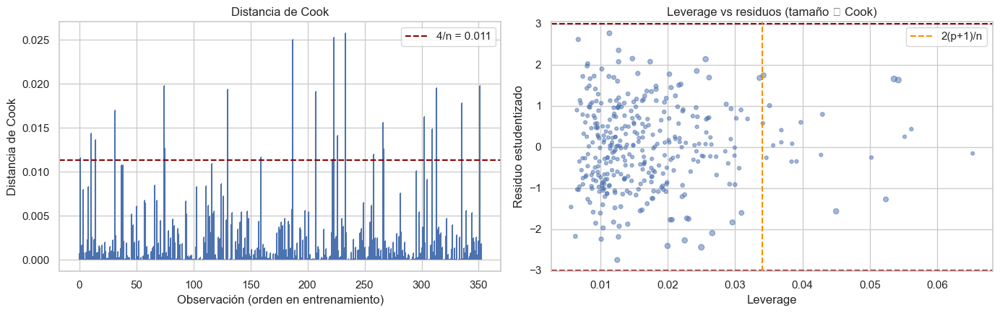

In [67]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].stem(np.arange(len(distancia_cook)), distancia_cook, markerfmt=",", basefmt=" ")
ejes[0].axhline(umbral_cook, color="darkred", ls="--", label=f"4/n = {umbral_cook:.3f}")
ejes[0].set_xlabel("Observación (orden en entrenamiento)"); ejes[0].set_ylabel("Distancia de Cook")
ejes[0].set_title("Distancia de Cook"); ejes[0].legend()

ejes[1].scatter(leverage, residuos_estud, s=12 + 800 * distancia_cook, alpha=0.5)
ejes[1].axhline(3, color="darkred", ls="--"); ejes[1].axhline(-3, color="darkred", ls="--")
ejes[1].axvline(umbral_lev, color="darkorange", ls="--", label="2(p+1)/n")
ejes[1].set_xlabel("Leverage"); ejes[1].set_ylabel("Residuo estudentizado")
ejes[1].set_title("Leverage vs residuos (tamaño ∝ Cook)"); ejes[1].legend()
plt.tight_layout(); plt.show()

**Cómo leer los gráficos:**

- **Izquierda, distancia de Cook:** cada barra es una observación. Las que sobrepasan la línea roja punteada ($4/n$) merecen revisión. Si alguna superara 1, sería muy influyente.
- **Derecha, leverage vs residuos:** el tamaño de cada punto es proporcional a su distancia de Cook. Los puntos a la **derecha** de la línea naranja tienen leverage alto; los que están **por fuera** de las líneas rojas horizontales ($\pm3$) son atípicos en $Y$. Los puntos más preocupantes son los **grandes** y alejados en ambas direcciones.

---
# PARTE 16. Tabla resumen del diagnóstico

**Qué vamos a hacer:** reunir en una sola tabla el resultado de todos los diagnósticos anteriores.

La tabla se construye **automáticamente** a partir de los valores calculados. La columna *Interpretación* aplica las reglas orientativas explicadas en cada sección; es una guía, y siempre debe contrastarse con los gráficos.

In [68]:
def tabla_diagnostico(alpha=ALPHA):
    def lectura_p(p, ok, mal):
        return ok if p >= alpha else mal
    vif_max = tabla_vif_final["VIF"].max()
    filas = [
        {"Diagnóstico": "Linealidad", "Herramienta": "Residuos vs ajustados + Rainbow",
         "Resultado": f"p Rainbow = {rainbow_p:.4f}",
         "Interpretación": lectura_p(rainbow_p, "Sin evidencia de no linealidad (revise el gráfico)",
                                     "Posible no linealidad: revise transformaciones")},
        {"Diagnóstico": "Normalidad", "Herramienta": "Q-Q / Shapiro-Wilk / Jarque-Bera",
         "Resultado": f"p SW = {sw_p:.4f}; p JB = {jb_p:.4f}",
         "Interpretación": lectura_p(min(p for p in [sw_p, jb_p] if not np.isnan(p)),
                                     "Sin evidencia contra la normalidad",
                                     "Evidencia de no normalidad: valore su relevancia con el Q-Q plot y n")},
        {"Diagnóstico": "Homocedasticidad", "Herramienta": "Breusch-Pagan",
         "Resultado": f"LM = {bp_lm:.3f}; p = {bp_lm_p:.4f}",
         "Interpretación": lectura_p(bp_lm_p, "Sin evidencia de heterocedasticidad",
                                     "Evidencia de heterocedasticidad: considere errores robustos (HC3)")},
        {"Diagnóstico": "Independencia", "Herramienta": "Durbin-Watson",
         "Resultado": f"DW = {dw:.3f}",
         "Interpretación": "Sin autocorrelación de primer orden aparente" if 1.5 <= dw <= 2.5
                           else "Posible autocorrelación: revise el orden/diseño de los datos"},
        {"Diagnóstico": "Multicolinealidad", "Herramienta": "VIF",
         "Resultado": f"VIF máximo = {vif_max:.2f}",
         "Interpretación": "Colinealidad baja/moderada" if vif_max <= 5
                           else ("Revisar colinealidad (VIF > 5)" if vif_max <= 10 else "Posible problema importante (VIF > 10)")},
        {"Diagnóstico": "Influencia", "Herramienta": "Distancia de Cook",
         "Resultado": f"{int((distancia_cook > umbral_cook).sum())} obs. > 4/n; {int((distancia_cook > 1).sum())} obs. > 1",
         "Interpretación": "Ninguna observación extremadamente influyente (Cook < 1)" if (distancia_cook <= 1).all()
                           else "Hay observaciones muy influyentes: revisar"},
    ]
    return pd.DataFrame(filas)

tabla_diag = tabla_diagnostico()
display(tabla_diag)

,Diagnóstico,Herramienta,Resultado,Interpretación
0,Linealidad,Residuos vs ajustados + Rainbow,p Rainbow = 0.0939,Sin evidencia de no linealidad (revise el gráf...
1,Normalidad,Q-Q / Shapiro-Wilk / Jarque-Bera,p SW = 0.7977; p JB = 0.5156,Sin evidencia contra la normalidad
2,Homocedasticidad,Breusch-Pagan,LM = 15.877; p = 0.0072,Evidencia de heterocedasticidad: considere err...
3,Independencia,Durbin-Watson,DW = 2.176,Sin autocorrelación de primer orden aparente
4,Multicolinealidad,VIF,VIF máximo = 1.50,Colinealidad baja/moderada
5,Influencia,Distancia de Cook,22 obs. > 4/n; 0 obs. > 1,Ninguna observación extremadamente influyente ...


**Cómo leer la tabla:** revise cada fila y pregúntese si el supuesto se cumple **razonablemente**. Ningún modelo real cumple todos los supuestos a la perfección; lo importante es identificar las violaciones relevantes y saber qué consecuencias tienen:

| Si falla… | Consecuencia principal | Qué se puede hacer |
|---|---|---|
| Linealidad | Coeficientes y predicciones sesgados | Transformar variables, agregar términos cuadráticos |
| Normalidad | p-valores e intervalos poco precisos (sobre todo con $n$ pequeño) | Transformar $Y$; con $n$ grande suele ser menos grave |
| Homocedasticidad | Errores estándar y p-valores incorrectos | Errores robustos (HC3), transformar $Y$ |
| Independencia | Errores estándar subestimados | Modelos para datos temporales |
| Multicolinealidad | Coeficientes inestables | Quitar o combinar variables, Ridge |
| Influencia | Resultados dependientes de pocos casos | Revisar esas observaciones |

---
# PARTE 17. Evaluación del ajuste (datos de entrenamiento)

**Qué vamos a hacer:** medir qué tan bien reproduce el modelo los mismos datos con los que fue construido.

| Métrica | Fórmula | Qué significa | Cómo leerla |
|---|---|---|---|
| $R^2$ | $1-\dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$ | Proporción de la variabilidad de $Y$ que explica el modelo. | Entre 0 y 1. Un $R^2$ de 0.49 significa que el modelo explica el 49% de las diferencias en $Y$. |
| $R^2$ ajustado | $1-(1-R^2)\dfrac{n-1}{n-p-1}$ | $R^2$ corregido por el número de predictores. | Siempre algo menor que $R^2$. Útil para comparar modelos de distinto tamaño. |
| MAE | $\frac1n\sum|y_i-\hat y_i|$ | Error absoluto medio: en promedio, cuánto se equivoca el modelo. | En las **mismas unidades de $Y$**. Si MAE = 44, el modelo se equivoca en promedio en 44 unidades. |
| MSE | $\frac1n\sum(y_i-\hat y_i)^2$ | Error cuadrático medio. | En unidades de $Y$ **al cuadrado**; difícil de interpretar directamente. |
| RMSE | $\sqrt{MSE}$ | Raíz del error cuadrático medio: tamaño típico del error. | En unidades de $Y$. Siempre $\ge$ MAE; castiga más los errores grandes. Si es mucho mayor que el MAE, hay algunos errores muy grandes. |

**Una referencia útil:** compare el RMSE con la **desviación estándar de $Y$**. La desviación estándar es el error que se cometería si, en lugar del modelo, siempre se predijera el promedio. Cuanto menor sea el RMSE frente a ella, más aporta el modelo.

In [69]:
pred_train = modelo_final.predict(con_constante(X_train[predictores_finales]))
metricas_train = metricas_regresion(y_train, pred_train, p=len(predictores_finales))
display(pd.Series(metricas_train).to_frame("Entrenamiento"))
print(f"Como referencia, la desviación estándar de Y en entrenamiento es {y_train.std():.3f}; "
      f"el RMSE indica cuánto se reduce el error típico al usar el modelo en vez de la media.")

,Entrenamiento
R2,0.4889
R2_ajustado,0.4815
MAE,44.2333
MSE,"2,982.8650"
RMSE,54.6156


Como referencia, la desviación estándar de Y en entrenamiento es 76.503; el RMSE indica cuánto se reduce el error típico al usar el modelo en vez de la media.


---
# PARTE 18. Evaluación de la capacidad predictiva (datos de prueba)

**Qué vamos a hacer:** usar el modelo final, **tal como quedó**, para predecir los datos de prueba que se guardaron al comienzo, y comparar sus errores con los del entrenamiento.

**Por qué:** es el momento de la verdad. El error en entrenamiento dice qué tan bien el modelo describe los datos que ya conoce; el error en prueba dice qué tan bien **predice datos nuevos**, que es lo que realmente importa si se quiere usar el modelo.

**Cómo interpretar la comparación:**

| Situación | Lo que se observa | Significado |
|---|---|---|
| **Buena generalización** | Errores parecidos en entrenamiento y prueba. | El modelo aprendió patrones reales, no particularidades de la muestra. |
| **Sobreajuste** | Error mucho **menor** en entrenamiento que en prueba. | El modelo "memorizó" los datos de entrenamiento (como estudiar sólo las respuestas de un examen anterior) y falla con datos nuevos. |
| **Subajuste** | Error **alto en ambos** conjuntos. | El modelo es demasiado simple: faltan variables, hay relaciones no lineales, o el fenómeno es muy difícil de predecir. |

La celda calcula además la **razón RMSE prueba / RMSE entrenamiento** y da una lectura orientativa.

In [70]:
pred_test = modelo_final.predict(con_constante(X_test[predictores_finales]))
metricas_test = metricas_regresion(y_test, pred_test, p=len(predictores_finales))

tabla_train_test = pd.DataFrame({"Train": metricas_train, "Test": metricas_test}).loc[
    ["R2", "R2_ajustado", "MAE", "MSE", "RMSE"]]
tabla_train_test["Diferencia (Test - Train)"] = tabla_train_test["Test"] - tabla_train_test["Train"]
display(tabla_train_test)

razon_rmse = metricas_test["RMSE"] / metricas_train["RMSE"]
print(f"Razón RMSE test / RMSE train = {razon_rmse:.3f}")
if razon_rmse > 1.2:
    print("Lectura orientativa: el error de prueba es claramente mayor -> revisar posible sobreajuste.")
elif razon_rmse < 0.8:
    print("Lectura orientativa: el error de prueba es menor que el de entrenamiento; puede deberse al azar "
          "de la partición (verifique con validación cruzada).")
else:
    print("Lectura orientativa: errores de magnitud similar -> sin indicios fuertes de sobreajuste.")

,Train,Test,Diferencia (Test - Train)
R2,0.4889,0.5759,0.0870
R2_ajustado,0.4815,0.5504,0.0688
MAE,44.2333,42.8363,-1.3970
MSE,"2,982.8650","2,671.7455",-311.1195
RMSE,54.6156,51.6889,-2.9267


Razón RMSE test / RMSE train = 0.946
Lectura orientativa: errores de magnitud similar -> sin indicios fuertes de sobreajuste.


**Nota:** el $R^2$ de prueba puede ser incluso **negativo**. Eso ocurre cuando el modelo predice peor que simplemente usar el promedio de $Y$, y sería señal de un problema serio.

---
# PARTE 19. Validación cruzada

**Qué vamos a hacer:** estimar el error de predicción de una forma más estable que con una sola división de los datos.

**El problema de una única división:** el error en el conjunto de prueba depende de **qué observaciones cayeron por azar** en ese 20%. Con otra división, el resultado podría ser algo mejor o peor.

**La solución, validación cruzada con $k = 5$ partes (*folds*):**

1. Se divide el conjunto de **entrenamiento** en 5 partes de tamaño similar.
2. Se ajusta el modelo con 4 partes y se mide el error en la parte restante.
3. Se repite 5 veces, cambiando cada vez la parte que se deja para evaluar.
4. Se obtienen **5 errores**: se reportan su **promedio** y su **desviación estándar**.

```
Ronda 1: [Evalúa] [Ajusta] [Ajusta] [Ajusta] [Ajusta]
Ronda 2: [Ajusta] [Evalúa] [Ajusta] [Ajusta] [Ajusta]
Ronda 3: [Ajusta] [Ajusta] [Evalúa] [Ajusta] [Ajusta]
Ronda 4: [Ajusta] [Ajusta] [Ajusta] [Evalúa] [Ajusta]
Ronda 5: [Ajusta] [Ajusta] [Ajusta] [Ajusta] [Evalúa]
```

**Ventajas:** todas las observaciones de entrenamiento se usan para evaluar alguna vez; el promedio de 5 errores es más estable que un solo error; y la desviación estándar indica **cuánto varía** el error según los datos. Además, permite comparar modelos **sin tocar el conjunto de prueba**.

La celda compara el modelo final con el modelo completo.

In [71]:
kf_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

pipe_ols_final = Pipeline([("modelo", LinearRegression())])
rmse_folds = -cross_val_score(pipe_ols_final, X_train[predictores_finales], y_train,
                              cv=kf_cv, scoring="neg_root_mean_squared_error")
r2_folds = cross_val_score(pipe_ols_final, X_train[predictores_finales], y_train, cv=kf_cv, scoring="r2")
rmse_folds_completo = -cross_val_score(pipe_ols_final, X_train, y_train, cv=kf_cv,
                                       scoring="neg_root_mean_squared_error")

tabla_cv = pd.DataFrame({"Fold": range(1, 6), "RMSE_modelo_final": rmse_folds,
                         "R2_modelo_final": r2_folds, "RMSE_modelo_completo": rmse_folds_completo}).set_index("Fold")
display(tabla_cv)
print(f"Modelo final   -> RMSE promedio = {rmse_folds.mean():.3f} (DE = {rmse_folds.std(ddof=1):.3f}); "
      f"R² promedio = {r2_folds.mean():.3f}")
print(f"Modelo completo-> RMSE promedio = {rmse_folds_completo.mean():.3f} (DE = {rmse_folds_completo.std(ddof=1):.3f})")

,RMSE_modelo_final,R2_modelo_final,RMSE_modelo_completo
Fold,,,
1,51.9504,0.5323,51.6819
2,58.0413,0.3999,57.9942
3,52.7843,0.4580,56.3350
4,57.5088,0.3859,56.2853
5,56.4252,0.5423,55.3248


Modelo final   -> RMSE promedio = 55.342 (DE = 2.793); R² promedio = 0.464
Modelo completo-> RMSE promedio = 55.524 (DE = 2.353)


**Cómo leer el resultado:** la tabla muestra el RMSE y el $R^2$ de cada una de las 5 rondas. Luego se dan el promedio y la desviación estándar (DE).

Si la diferencia entre el RMSE promedio de dos modelos es **menor que la DE** entre rondas, no hay evidencia clara de que uno prediga mejor que el otro. En ese caso, conviene preferir el modelo más simple.

---
# PARTE 20. Gráfico de valores observados vs predichos

**Qué muestra:** cada punto es una observación. En el eje horizontal está su **valor real** y en el vertical el **valor que predijo el modelo**. Los puntos grises son de entrenamiento y los azules de prueba.

La **línea diagonal roja** ($y = x$) representa la predicción perfecta: si un punto está sobre ella, el modelo acertó exactamente.

**Cómo leerlo:**

- **Puntos cerca de la diagonal:** buenas predicciones.
- **Nube ancha alrededor de la diagonal:** errores grandes; coherente con un RMSE alto.
- **Puntos sistemáticamente por encima de la diagonal** en valores bajos y **por debajo** en valores altos: el modelo "aplana" los extremos, es decir, sobreestima los valores bajos y subestima los altos. Es un comportamiento habitual cuando el $R^2$ es moderado.

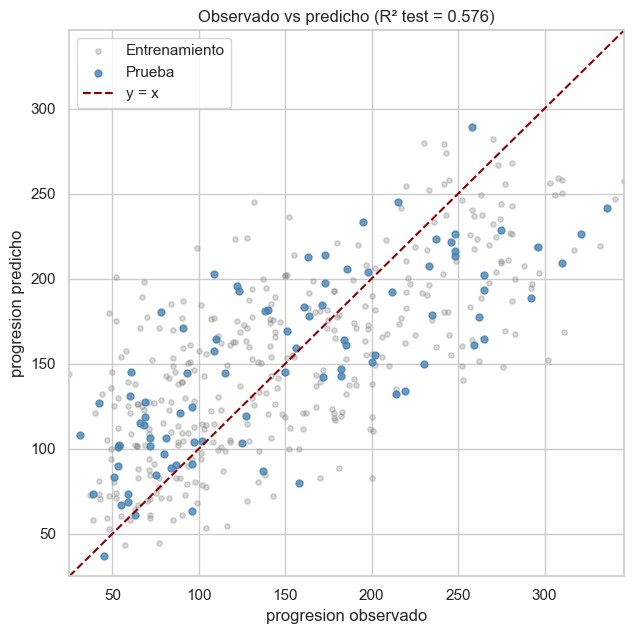

In [72]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(y_train, pred_train, alpha=0.3, s=15, color="grey", label="Entrenamiento")
ax.scatter(y_test, pred_test, alpha=0.8, s=25, color="steelblue", label="Prueba")
limites = [min(y.min(), pred_train.min(), pred_test.min()), max(y.max(), pred_train.max(), pred_test.max())]
ax.plot(limites, limites, color="darkred", ls="--", label="y = x")
ax.set_xlim(limites); ax.set_ylim(limites)
ax.set_xlabel(f"{variable_objetivo} observado"); ax.set_ylabel(f"{variable_objetivo} predicho")
ax.set_title(f"Observado vs predicho (R² test = {metricas_test['R2']:.3f})")
ax.legend(); plt.tight_layout(); plt.show()

---
# PARTE 21. Predicciones

## 21.1 Predicciones sobre el conjunto de prueba

Para cada observación de prueba se muestra:

| Columna | Significado |
|---|---|
| `Real` | Valor observado de $Y$. |
| `Predicho` | Valor que calculó el modelo con la ecuación. |
| `Residuo` | Real − Predicho. **Positivo**: el modelo se quedó corto (subestimó). **Negativo**: el modelo se pasó (sobreestimó). |
| `Error_absoluto` | Tamaño del error sin importar el signo. |

También se listan los 5 casos con **mayor error**, que conviene revisar: ¿tienen algo en común que el modelo no está capturando?

In [73]:
tabla_predicciones = pd.DataFrame({
    "Real": y_test, "Predicho": pred_test,
}, index=y_test.index)
tabla_predicciones["Residuo"] = tabla_predicciones["Real"] - tabla_predicciones["Predicho"]
tabla_predicciones["Error_absoluto"] = tabla_predicciones["Residuo"].abs()

display(Markdown("**Primeras 10 predicciones de prueba:**"))
display(tabla_predicciones.head(10))
display(Markdown("**Las 5 predicciones con mayor error absoluto:**"))
display(tabla_predicciones.sort_values("Error_absoluto", ascending=False).head(5))

**Primeras 10 predicciones de prueba:**

,Real,Predicho,Residuo,Error_absoluto
13,185.0000,160.8160,24.1840,24.1840
66,150.0000,144.8720,5.1280,5.1280
234,246.0000,221.5543,24.4457,24.4457
24,184.0000,164.0020,19.9980,19.9980
388,110.0000,164.3519,-54.3519,54.3519
72,202.0000,155.3567,46.6433,46.6433
138,336.0000,241.4332,94.5668,94.5668
384,69.0000,127.6032,-58.6032,58.6032
11,69.0000,118.6651,-49.6651,49.6651
33,87.0000,90.3637,-3.3637,3.3637


**Las 5 predicciones con mayor error absoluto:**

,Real,Predicho,Residuo,Error_absoluto
190,292.0000,188.7419,103.2581,103.2581
328,78.0000,180.4972,-102.4972,102.4972
9,310.0000,209.2347,100.7653,100.7653
280,265.0000,164.3203,100.6797,100.6797
232,259.0000,161.1209,97.8791,97.8791


## 21.2 Predicción para casos nuevos

**Qué vamos a hacer:** usar la ecuación del modelo para estimar $Y$ en situaciones que nosotros definimos.

### Dos tipos de intervalos

Toda predicción tiene incertidumbre, y se expresa con dos intervalos distintos que responden a preguntas diferentes:

| Intervalo | Pregunta que responde | Ejemplo con la base de ejemplo |
|---|---|---|
| **Intervalo de confianza (IC) de la media** | ¿Cuál es el valor **promedio** de $Y$ para **todos** los individuos con estas características? | "El promedio de progresión de los pacientes con este perfil está entre A y B." |
| **Intervalo de predicción (IP)** | ¿Qué valor de $Y$ puede tener **un individuo en particular** con estas características? | "Un paciente concreto con este perfil tendrá una progresión entre C y D." |

El **intervalo de predicción siempre es más ancho**, porque además de la incertidumbre sobre los coeficientes incluye la variabilidad natural entre individuos (el error $\varepsilon$). Es más fácil acertar el promedio de un grupo que el valor de una persona.

$$
\text{IC: } \hat y_0 \pm t\cdot\hat\sigma\sqrt{\mathbf{x}_0^\top(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{x}_0}
\qquad\qquad
\text{IP: } \hat y_0 \pm t\cdot\hat\sigma\sqrt{1+\mathbf{x}_0^\top(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{x}_0}
$$

El "1 +" dentro de la raíz del IP es precisamente la variabilidad individual adicional.

### Configuración: definir los casos que se quieren predecir

Los casos nuevos se escriben con las **variables originales**, tal como aparecen en la base (por ejemplo, `"sexo": "Grupo_2"`, no con dummies). El cuadernillo se encarga de transformarlos igual que en el entrenamiento.

**Punto de partida:** `valores_defecto` contiene un "perfil típico": la **mediana** de cada variable numérica y la **categoría más frecuente** de cada variable categórica. Con eso la celda funciona sin cambios.

**Cómo crear sus propios casos:** cada caso es una línea dentro de la lista. La expresión `{**valores_defecto, "imc": 32}` significa *"tome el perfil típico y cambie el IMC a 32"*. Para agregar un caso, quite el `#` de la línea de ejemplo o copie esa línea y modifique los valores:

```python
nuevo_caso = pd.DataFrame([
    valores_defecto,                                         # caso 1: perfil típico
    {**valores_defecto, "imc": 32, "presion_arterial": 110}, # caso 2: IMC y presión más altos
    {**valores_defecto, "sexo": "Grupo_2"},                  # caso 3: igual al típico, pero Grupo_2
])
```

**Advertencia de extrapolación:** si algún valor está fuera del rango observado en los datos de entrenamiento, el código lo avisa. Fuera de ese rango no se sabe si la relación sigue siendo lineal, y la predicción puede ser poco confiable.

In [74]:
# Valores por defecto: mediana (numéricas) o moda (categóricas) de los datos de modelamiento
valores_defecto = {c: datos_modelo[c].median() for c in pred_numericos}
valores_defecto.update({c: datos_modelo[c].mode().iloc[0] for c in pred_categoricos})

# ===============================================================
# CONFIGURACIÓN: casos nuevos (una línea por caso), en variables ORIGINALES
# ===============================================================
nuevo_caso = pd.DataFrame([
    valores_defecto,                                   # caso 1: "perfil típico"
    # {**valores_defecto, "imc": 32, "presion_arterial": 110},   # caso 2: quite el # para usarlo
])
display(Markdown("**Caso(s) nuevo(s) en variables originales:**"))
display(nuevo_caso)

# Misma codificación que en entrenamiento y sólo las columnas del modelo final
X_nuevo = codificar_predictores(nuevo_caso, pred_numericos, pred_categoricos, categorias)
X_nuevo = X_nuevo.reindex(columns=X.columns, fill_value=0.0)[predictores_finales]

# Advertencia de extrapolación: valores fuera del rango observado en entrenamiento
fuera = [(i, v, X_nuevo.loc[i, v]) for i in X_nuevo.index for v in predictores_finales
         if not (X_train[v].min() <= X_nuevo.loc[i, v] <= X_train[v].max())]
for i, v, val in fuera:
    print(f"⚠️ Caso {i}: {v} = {val} está fuera del rango de entrenamiento "
          f"[{X_train[v].min()}, {X_train[v].max()}] -> extrapolación.")

prediccion = modelo_final.get_prediction(con_constante(X_nuevo)).summary_frame(alpha=ALPHA)
nivel = int((1 - ALPHA) * 100)
prediccion = prediccion.rename(columns={
    "mean": "Prediccion_puntual", "mean_se": "Error_estandar_media",
    "mean_ci_lower": f"IC{nivel}_media_inf", "mean_ci_upper": f"IC{nivel}_media_sup",
    "obs_ci_lower": f"IP{nivel}_inf", "obs_ci_upper": f"IP{nivel}_sup",
})
display(Markdown("**Predicción, intervalo de confianza de la media e intervalo de predicción:**"))
display(prediccion)

**Caso(s) nuevo(s) en variables originales:**

,edad,imc,presion_arterial,colesterol_total,ldl,hdl,ratio_col_hdl,log_trigliceridos,glucosa,sexo
0,50.0000,25.7000,93.0000,186.0000,113.0000,48.0000,4.0000,4.6200,91.0000,Grupo_1


**Predicción, intervalo de confianza de la media e intervalo de predicción:**

,Prediccion_puntual,Error_estandar_media,IC95_media_inf,IC95_media_sup,IP95_inf,IP95_sup
0,157.4445,4.4422,148.7074,166.1816,48.7487,266.1402


**Cómo leer la tabla de resultados:**

| Columna | Significado |
|---|---|
| `Prediccion_puntual` | El valor de $Y$ que estima el modelo. |
| `IC95_media_inf`, `IC95_media_sup` | Límites del intervalo de confianza para el **promedio**. |
| `IP95_inf`, `IP95_sup` | Límites del intervalo de predicción para **un individuo**. |

**Ejemplo de redacción:** *"Para un paciente con [características], el modelo estima una progresión de [predicción puntual]. Con un 95% de confianza, el promedio de progresión de los pacientes con ese perfil está entre [IC inf] y [IC sup]; para un paciente individual, se espera un valor entre [IP inf] y [IP sup]."*

Las predicciones sólo son válidas para la **misma población** representada por los datos y dentro del **rango de valores observados**.

---
# PARTE 22. Conclusiones y recomendaciones

**Qué vamos a hacer:** reunir los resultados principales y responder la pregunta que motivó el análisis.

La celda siguiente recopila **automáticamente** los resultados clave del cuadernillo: variables del modelo, ecuación, variables significativas, métricas de ajuste y predicción, y el resumen de supuestos. Es una base para construir las conclusiones, que deben redactarse con criterio propio y en el lenguaje del problema.

In [75]:
sig = tabla_coef_final.drop("const")
sig = sig[sig["p_valor"] < ALPHA]

print("=== INSUMOS PARA LAS CONCLUSIONES ===\n")
print(f"Variable respuesta: {variable_objetivo} | n entrenamiento = {len(y_train)}, n prueba = {len(y_test)}")
print(f"Predictores del modelo final ({len(predictores_finales)}): {predictores_finales}\n")
print("Ecuación:", ec_final_texto, "\n")
print(f"Variables significativas al {int(ALPHA * 100)}%:")
for var, fila in sig.iterrows():
    print(f"  - {var}: coef = {fila['coeficiente']:.4f} ({'positiva' if fila['coeficiente'] > 0 else 'negativa'}), p = {fila['p_valor']:.4f}")
print(f"\nAjuste (train): R² = {metricas_train['R2']:.3f}, R² aj = {metricas_train['R2_ajustado']:.3f}, "
      f"RMSE = {metricas_train['RMSE']:.3f}, MAE = {metricas_train['MAE']:.3f}")
print(f"Predicción (test): R² = {metricas_test['R2']:.3f}, RMSE = {metricas_test['RMSE']:.3f}, MAE = {metricas_test['MAE']:.3f}")
print(f"Validación cruzada: RMSE = {rmse_folds.mean():.3f} ± {rmse_folds.std(ddof=1):.3f}")
print(f"VIF máximo del modelo final: {tabla_vif_final['VIF'].max():.2f}")
print(f"Lasso descartó: {descartadas_lasso if descartadas_lasso else 'ninguna variable'} (alpha = {lasso.alpha_:.4f})")
print(f"Ridge: alpha = {alpha_ridge:.4f}; RMSE test = {np.sqrt(mean_squared_error(y_test, pred_ridge_test)):.3f}")
print("\nDiagnóstico de supuestos:")
for fila in tabla_diag.itertuples():
    print(f"  - {fila.Diagnóstico}: {fila.Resultado} -> {fila.Interpretación}")

=== INSUMOS PARA LAS CONCLUSIONES ===

Variable respuesta: progresion | n entrenamiento = 353, n prueba = 89
Predictores del modelo final (5): ['imc', 'log_trigliceridos', 'presion_arterial', 'hdl', 'sexo_Grupo_2']

Ecuación: progresion_estimado = -212.721 + 5.574*imc + 39.892*log_trigliceridos + 1.047*presion_arterial - 1.140*hdl - 20.116*sexo_Grupo_2 

Variables significativas al 5%:
  - imc: coef = 5.5739 (positiva), p = 0.0000
  - log_trigliceridos: coef = 39.8917 (positiva), p = 0.0000
  - presion_arterial: coef = 1.0466 (positiva), p = 0.0000
  - hdl: coef = -1.1399 (negativa), p = 0.0000
  - sexo_Grupo_2: coef = -20.1158 (negativa), p = 0.0023

Ajuste (train): R² = 0.489, R² aj = 0.482, RMSE = 54.616, MAE = 44.233
Predicción (test): R² = 0.576, RMSE = 51.689, MAE = 42.836
Validación cruzada: RMSE = 55.342 ± 2.793
VIF máximo del modelo final: 1.50
Lasso descartó: ninguna variable (alpha = 0.0440)
Ridge: alpha = 0.0010; RMSE test = 52.194

Diagnóstico de supuestos:
  - Linealidad:

## Preguntas para construir las conclusiones

**Sobre las variables**

1. ¿Qué variables resultaron relevantes para explicar $Y$?
2. ¿Cuál fue su relación con $Y$ (dirección y magnitud, expresadas en las unidades reales)?

**Sobre la calidad del modelo**

3. ¿Qué tan bien se ajusta el modelo ($R^2$, $R^2$ ajustado)?
4. ¿Qué tan bien predice (RMSE y MAE en prueba y en validación cruzada)? ¿Es ese nivel de error aceptable para el uso que se le quiere dar?
5. ¿Se cumplen razonablemente los supuestos? ¿Qué implican las violaciones encontradas?
6. ¿Hay problemas de multicolinealidad?

**Sobre los métodos**

7. ¿Qué mostró Lasso? ¿Coincide con la selección por p-valores?
8. ¿Qué mostró Ridge? ¿Mejora la predicción frente a OLS?

**Sobre el uso del modelo**

9. ¿El modelo es fácil de interpretar para quien lo va a usar?
10. ¿Cuáles son sus limitaciones (datos observacionales, variables que no se midieron, tamaño de muestra, calidad de la medición)?
11. ¿Para qué población y en qué rango de valores es válido usarlo?
12. ¿Qué podría mejorarse (más datos, nuevas variables, transformaciones, interacciones)?

**Ejemplo de conclusión bien formulada:** *"El índice de masa corporal, los triglicéridos y la presión arterial se asocian positivamente con la progresión de la enfermedad, controlando por las demás variables del modelo. El modelo explica cerca de la mitad de la variabilidad de la progresión y su error de predicción típico es de alrededor de 52 unidades. Estas asociaciones no implican causalidad, dado el carácter observacional de los datos."* (Las cifras de este ejemplo corresponden a la base incluida; con otra base deben reemplazarse por las obtenidas.)

---
# PARTE 23. Lista de verificación final

Use esta lista para comprobar que recorrió todo el proceso:

- [ ] Definí el problema.
- [ ] Identifiqué la variable respuesta.
- [ ] Identifiqué los predictores.
- [ ] Revisé la calidad de los datos.
- [ ] Realicé el análisis exploratorio.
- [ ] Separé entrenamiento y prueba.
- [ ] Construí el modelo completo.
- [ ] Analicé las correlaciones.
- [ ] Evalué el VIF.
- [ ] Probé la selección Forward.
- [ ] Probé Backward.
- [ ] Probé Stepwise.
- [ ] Probé Lasso.
- [ ] Probé Ridge.
- [ ] Comparé las alternativas.
- [ ] Seleccioné y justifiqué el modelo final.
- [ ] Escribí la ecuación.
- [ ] Interpreté los coeficientes.
- [ ] Analicé los residuos.
- [ ] Evalué la normalidad.
- [ ] Evalué la homocedasticidad.
- [ ] Evalué las observaciones influyentes.
- [ ] Calculé $R^2$ y $R^2$ ajustado.
- [ ] Calculé MAE y RMSE.
- [ ] Evalué el desempeño en prueba.
- [ ] Realicé validación cruzada.
- [ ] Realicé predicciones.
- [ ] Elaboré conclusiones.